<h1 style="color:#1a5276;">Predicción de ROP — Análisis de los pozos 0, 2, 3, 4 y 6, sin relleno (ffill/bfill)</h1>

### Limpieza pozo por pozo, usando solo mediciones reales

En el **Notebook 1** limpiamos el pozo 1 desde su archivo crudo y lo dejamos en dos versiones: una **con** `ffill`/`bfill` y otra **sin relleno** (solo mediciones reales). Acá hacemos **el mismo análisis, con el mismo nivel de detalle, para los otros pozos de entrenamiento**: los pozos **6, 0, 2, 3 y 4**, de a uno.

### ¿Por qué sin relleno?

Los archivos oficiales del dataset vienen **rellenados** (con `ffill` y `bfill`), y de esos ya tenemos la versión "con relleno" de todos los pozos. Explorar los datos antes de transformarlos mostró, en el pozo 1, que con relleno las correlaciones se ven mucho más fuertes de lo que son (la presión daba 0.80 con relleno y 0.42 con mediciones reales), y el `Weight on Bit` llegaba a cambiar de signo. Por eso, para el modelado queremos tener **también** la versión sin relleno de cada pozo, y poder comparar los dos resultados teniendo en cuenta que éste último sería más realista.

### Qué aprendimos del pozo 1 (el modelo a seguir)

| Paso | Resultado en el pozo 1 (Notebook 1) |
|---|---|
| Filas del archivo crudo | 21.013 (19.018 después de sacar el tramo de 36 pulgadas) |
| Filas donde los sensores de superficie midieron algo | 638 |
| Filas **completas** (6 sensores + ROP a la vez) | **603** (3,2 %) |
| Nulos que quedaban en esas filas | **ninguno**; las 35 incompletas eran valores imposibles que nosotras invalidamos |
| Qué hicimos con esas 35 | Las descartamos (el ROP no se inventa; reemplazar movía las correlaciones) |
| Variables que sacamos | `Gamma Ray` (solo 7 filas completas) y `Mud Density` (no coincide en los otros pozos) |
| Correlación con el ROP, con mediciones reales | positiva pero moderada (0.30 a 0.42) |

**Ahora repetimos ese recorrido en cada pozo**, para ver cuántas filas reales tiene cada uno y si los hallazgos se repiten.

## Qué vamos a hacer en este notebook

**Objetivo:** dejar los pozos de entrenamiento **limpios y sin relleno**, uno por uno, con el mismo criterio que el pozo 1, para poder combinarlos después en un solo dataset.

**Entregables:**
- Un archivo `USROP_A N sin relleno.csv` por cada pozo (`N` = número de pozo), con las mismas columnas y el mismo orden que los pozos oficiales (10 columnas).
- El pozo 5 (test) **limpio con el mismo procedimiento pero sin explorar**.
- Una tabla comparativa de los pozos y un dataset conjunto (con el pozo 1) listo para el Notebook de modelado.

### Cómo está organizado

| Parte | Contenido |
|---|---|
| **0** | Preparación del entorno |
| **1** | Los pozos de un vistazo: profundidades, tramos y tamaño |
| **2** | Reglas de limpieza comunes (las mismas del Notebook 1, definidas una sola vez) |
| **3** | Pozo 6 |
| **4** | Pozo 0 |
| **5** | Pozo 2 |
| **6** | Pozo 3 |
| **7** | Pozo 4 |
| **8** | Pozo 5 (test): solo limpieza, sin explorar |
| **9** | Comparación entre pozos y dataset conjunto (con el pozo 1) |

**Orden de los pozos: 6, 0, 2, 3 y 4.** Empezamos por el 6 porque es el más simple (casi vertical, el de menos filas) y nos sirve para afinar la plantilla; el 3 y el 4 son los más grandes y los que más valores fuera de rango tienen, así que los dejamos para el final.

### La plantilla: los mismos pasos en cada pozo

Cada pozo (Partes 3 a 7) tiene **exactamente los mismos subtítulos**, para poder compararlos fácil:

| Paso | Qué hacemos |
|---|---|
| **X.1** El archivo y sus tramos | Filas, columnas, diámetros de mecha |
| **X.2** Qué hay realmente medido | % de datos reales; si el grupo de superficie reporta junto |
| **X.3** Limpieza | Sacar los tramos grandes, ordenar por tramo y profundidad, pasar a `NaN` los valores imposibles |
| **X.4** Nulos que quedan | Qué falta en las filas incompletas, y si conviene descartar o reemplazar |
| **X.5** Dataset final del pozo | Filas, columnas, ceros, estadística y rangos físicos (la verificación de la sección 10.9 del Notebook 1) |
| **X.6** Outliers | Con IQR, sobre mediciones reales; de qué lado caen |
| **X.7** Correlación con el ROP | Simple y parcial (sin el efecto de la profundidad) |
| **X.8** Guardar | `USROP_A N sin relleno.csv` |
| **X.9** Conclusión | Caja amarilla con lo que encontramos |

<div style="background-color:#fdecea; border-left:6px solid #e74c3c; padding:14px 18px; border-radius:4px;">

**🔴 Dos reglas que valen en todo el notebook**

1. **El pozo 5 es el test.** Se limpia con exactamente el mismo procedimiento que los demás (para poder usarlo al final), pero **no se explora, no se grafica y no se usa para tomar ninguna decisión**. Por eso en la tabla de la Parte 1 solo mostramos sus datos de archivo (filas, columnas, tamaño), sin profundidades.
2. **El pozo 1 ya está hecho** (Notebook 1, secciones 10.3 a 10.9). Acá no se vuelve a explorar: se incorpora su archivo `USROP_A 1 sin relleno.csv` recién en la Parte 9, para armar el dataset conjunto.

</div>

### Glosario rápido

| Término | Qué es |
|---|---|
| **Medición real** | Valor que el sensor efectivamente registró en esa fila (no copiado de otra) |
| **`ffill` / `bfill`** | Rellenar un hueco con el último valor anterior (`ffill`) o el siguiente (`bfill`). **Acá no se usan** |
| **Núcleo de perforación** | Los sensores de superficie que reportan juntos: WOB, torque, RPM, presión de bombeo, Hookload y caudal de lodo |
| **Fila completa** | Fila donde el núcleo y el ROP tienen dato real a la vez |
| **MD** (`Measured Depth`) | Profundidad medida a lo largo del hueco, siguiendo su recorrido |
| **TVD** (`Hole Depth (TVD)`) | Profundidad vertical verdadera, medida en línea recta hacia abajo |
| **Pozo desviado** | Pozo perforado en ángulo: su MD es mayor que su TVD |
| **Tramo** | Sección del pozo perforada con un mismo diámetro de mecha |
| **MAR** | Faltante que depende de otra cosa que sí observamos (por ejemplo, qué sensores reportan juntos) |

## Parte 0. Preparación del entorno

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

Definimos los datos de cada pozo una sola vez. El **número de pozo** (`0` a `6`) es el mismo que usa el dataset oficial. Los nombres reales del campo (`F-9 A`, `F-7`, ...) quedan solo como referencia en la tabla de la Parte 1; en el resto del notebook llamamos a cada pozo por su número.

In [2]:
# Archivos crudos (tal cual salen de los sensores; nunca se modifican)
archivos_crudos = {k: f'crudo_temp/well{k}_crudo.csv' for k in range(7)}
nombre_real = {0: 'F-9 A', 1: 'F-7', 2: 'F-14', 3: 'F-15', 4: 'F-15S', 5: 'F-5', 6: 'F-9'}   # nombre de campo: solo de referencia
nombre_pozo = {k: f'pozo {k}' for k in nombre_real}                                          # así los llamamos en todo el notebook

POZO_TEST = 5            # reservado: se limpia, pero no se explora
POZO_HECHO = 1           # ya resuelto en el Notebook 1
pozos_a_analizar = [6, 0, 2, 3, 4]   # en este orden

uso = {0: 'Entrenamiento', 1: 'Entrenamiento (hecho en el Notebook 1)', 2: 'Entrenamiento', 3: 'Entrenamiento',
       4: 'Entrenamiento', 5: 'TEST (reservado)', 6: 'Entrenamiento'}

def pulgadas(nombre):
    """Diámetro de mecha en pulgadas, a partir del nombre del tramo (entiende '17.5 in', '17 1/2in', '12 1/4in')."""
    m = re.search(r'(\d+)\s+(\d)/(\d)\s*in', nombre)          # fracciones: 17 1/2in
    if m:
        return int(m.group(1)) + int(m.group(2)) / int(m.group(3))
    m = re.search(r'(\d+(?:\.\d+)?)\s*in', nombre)            # decimales: 17.5 in
    return float(m.group(1)) if m else np.nan

print('Pozos a analizar, en orden:', [nombre_pozo[k] for k in pozos_a_analizar])

Pozos a analizar, en orden: ['pozo 6', 'pozo 0', 'pozo 2', 'pozo 3', 'pozo 4']


<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Conclusión Parte 0:** el notebook trabaja con los **archivos crudos** (sin `ffill`/`bfill`), analiza los pozos **6, 0, 2, 3 y 4** en ese orden, deja el pozo 1 como ya resuelto y trata al pozo 5 como test (se limpia, no se explora).

</div>

## Parte 1. Los pozos de un vistazo

Antes de limpiar nada, miramos **qué hay en cada archivo**: cuántas filas, qué profundidad cubre y con qué diámetros de mecha se perforó. Todo se calcula con código a partir de los archivos crudos.

### 1.1 Tabla de los 7 pozos

Leemos **solo tres columnas** de cada archivo (las dos profundidades y el nombre del tramo), porque cada crudo tiene hasta 189 columnas y no las necesitamos todavía. Del pozo 5 solo contamos filas y columnas del archivo: **no leemos sus profundidades**.

In [3]:
filas_tabla = []
for k in range(7):
    ruta = archivos_crudos[k]
    fila = {'N°': k, 'Nombre real': nombre_real[k], 'Uso': uso[k],
            'Filas': len(pd.read_csv(ruta, usecols=[0])),
            'Columnas del archivo': pd.read_csv(ruta, nrows=0).shape[1],
            'Tamaño (MB)': round(os.path.getsize(ruta) / 1e6, 1)}
    if k != POZO_TEST:
        d = pd.read_csv(ruta, usecols=['Measured Depth m', 'Hole Depth (TVD) m', 'name'])
        md_max, tvd_max = d['Measured Depth m'].max(), d['Hole Depth (TVD) m'].max()
        tramos_pulg = sorted(d['name'].map(pulgadas).unique(), reverse=True)
        fila.update({'MD mín (m)': round(d['Measured Depth m'].min()), 'MD máx (m)': round(md_max),
                     'TVD máx (m)': round(tvd_max), 'MD / TVD': round(md_max / tvd_max, 2),
                     'Tipo': 'Casi vertical' if md_max / tvd_max < 1.02 else 'Desviado',
                     'Tramos (pulgadas)': ', '.join(f'{p:g}' for p in tramos_pulg)})
    else:
        fila.update({'MD mín (m)': '—', 'MD máx (m)': '—', 'TVD máx (m)': '—', 'MD / TVD': '—',
                     'Tipo': '—', 'Tramos (pulgadas)': '—'})
    filas_tabla.append(fila)

tabla_pozos = pd.DataFrame(filas_tabla).set_index('N°')
tabla_pozos

,Nombre real,Uso,Filas,Columnas del archivo,Tamaño (MB),MD mín (m),MD máx (m),TVD máx (m),MD / TVD,Tipo,Tramos (pulgadas)
N°,,,,,,,,,,,
0,F-9 A,Entrenamiento,16670,115,5.6,273,1206,1013,1.19,Desviado,"12.25, 8.5"
1,F-7,Entrenamiento (hecho en el Notebook 1),21013,65,4.2,0,915,911,1.0,Casi vertical,"36, 17.5"
2,F-14,Entrenamiento,110301,160,31.2,0,3466,2994,1.16,Desviado,"26, 17.5, 12.25, 8.5"
3,F-15,Entrenamiento,112714,189,37.4,1179,4065,3189,1.27,Desviado,"17.5, 8.5"
4,F-15S,Entrenamiento,124636,159,33.3,0,4090,3172,1.29,Desviado,"12.25, 8.5"
5,F-5,TEST (reservado),30356,79,6.7,—,—,—,—,—,—
6,F-9,Entrenamiento,13830,87,3.2,0,634,633,1.0,Casi vertical,"36, 17.5"


### 1.2 Cuánta profundidad cubre cada pozo

La misma información de la tabla, en un gráfico: cada barra va desde la profundidad medida (MD) más baja hasta la más alta de ese pozo. El pozo 5 no aparece, por la regla del test.

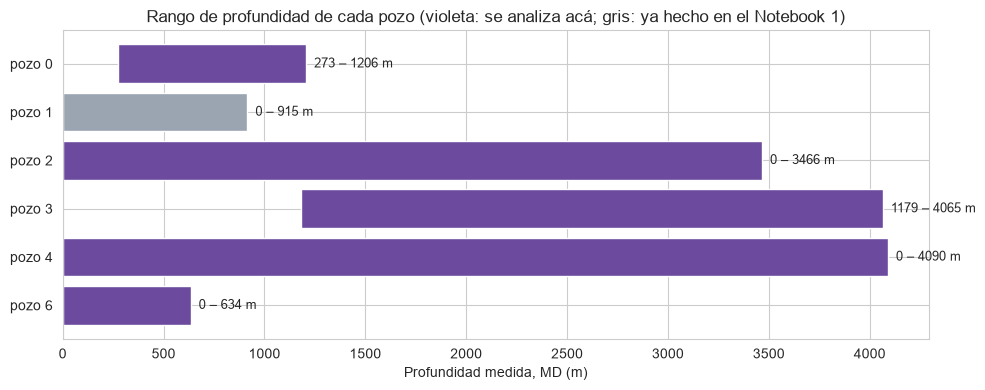

In [4]:
visibles = tabla_pozos[tabla_pozos['MD mín (m)'] != '—'].copy()
colores = {'Entrenamiento': '#6c4a9e', 'Entrenamiento (hecho en el Notebook 1)': '#9aa5b1'}

fig, ax = plt.subplots(figsize=(10, 4))
for pos, (k, f) in enumerate(visibles.iterrows()):
    ax.barh(pos, f['MD máx (m)'] - f['MD mín (m)'], left=f['MD mín (m)'], color=colores[f['Uso']])
    ax.text(f['MD máx (m)'] + 40, pos, f"{f['MD mín (m)']} – {f['MD máx (m)']} m", va='center', fontsize=9)
ax.set_yticks(range(len(visibles)))
ax.set_yticklabels([f"pozo {k}" for k, f in visibles.iterrows()])
ax.invert_yaxis()
ax.set_xlabel('Profundidad medida, MD (m)')
ax.set_title('Rango de profundidad de cada pozo (violeta: se analiza acá; gris: ya hecho en el Notebook 1)')
plt.tight_layout()
plt.show()

<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Conclusión Parte 1:** los 7 pozos son **muy distintos entre sí**: de 13.830 a 124.636 filas, de 634 a 4.090 m de profundidad máxima, dos casi verticales y cuatro desviados (más el pozo 5, del que solo vemos los datos de archivo), y con entre 2 y 4 tramos de mecha. Dos de ellos (los pozos 0 y 3) no empiezan en superficie.

Esto importa para el modelo: lo que se aprenda en pozos poco profundos puede no servir en los profundos, y **más filas no significa más información** (en el pozo 1, 21.013 filas dieron solo 603 mediciones completas). Por eso analizamos **pozo por pozo** antes de juntarlos.

</div>

## Parte 2. Reglas de limpieza comunes

Todos los pozos se limpian **con las mismas reglas**, las del Notebook 1. Las definimos **una sola vez**, acá, como funciones, y cada pozo (Partes 3 a 7) las usa y muestra lo que encuentra. Así no hay diferencias entre pozos por error, y si hay que cambiar una regla se cambia en un solo lugar.

### 2.1 Variables y lectura de un pozo

Primero nombramos las variables. El **núcleo de perforación** son los 6 sensores de superficie que reportan juntos; el **objetivo** es el ROP.

In [5]:
objetivo = 'Rate of Penetration m/h'
nucleo = ['Weight on Bit kkgf', 'Average Surface Torque kN.m', 'Average Rotary Speed rpm',
          'Average Standpipe Pressure kPa', 'Average Hookload kkgf', 'Mud Flow In L/min']
grupo_superficie = nucleo + [objetivo]          # las 7 variables que tienen que estar a la vez
densidad = 'Mud Density In g/cm3'
RPM = 'Average Rotary Speed rpm'
RPM_ALTERNATIVA = 'Total Downhole RPM rpm'          # misma medición de RPM bajo otro nombre (se demuestra en 2.1.1)
columnas_leer = ['Measured Depth m', 'Hole Depth (TVD) m', 'name', densidad] + grupo_superficie

def cargar_pozo(k):
    """Lee solo las columnas de interés del archivo crudo del pozo k (el crudo nunca se modifica)."""
    ruta = archivos_crudos[k]
    encabezado = pd.read_csv(ruta, nrows=0).columns
    gamma_cols = [c for c in encabezado if 'Gamma Ray' in c]               # cada pozo llama distinto a su Gamma
    rpm_equivalente = [RPM_ALTERNATIVA] if RPM_ALTERNATIVA in encabezado else []   # canal con la misma RPM (ver 2.1.1)
    d = pd.read_csv(ruta, usecols=columnas_leer + gamma_cols + rpm_equivalente)
    if rpm_equivalente:
        d[RPM] = d[RPM].fillna(d[RPM_ALTERNATIVA])                         # solo donde la columna principal está vacía
        d = d.drop(columns=rpm_equivalente)
    d['Gamma medido'] = d[gamma_cols].notna().any(axis=1) if gamma_cols else False   # solo guardamos si hay dato o no
    d = d.drop(columns=gamma_cols)
    d['pulgadas'] = d['name'].map(pulgadas)                                # diámetro de mecha del tramo, en pulgadas
    d['Diameter mm'] = (d['pulgadas'] * 25.4).round(2)                     # el mismo diámetro, en milímetros
    return d

#### 2.1.1 Una misma medición con dos nombres: la RPM

Al mirar las columnas de los archivos crudos aparece `Total Downhole RPM`. Si fuera **la misma medición** que `Average Rotary Speed` (la RPM que usamos), podríamos usarla donde la otra está vacía, sin inventar nada: sería una lectura real. Lo comprobamos en las filas donde **las dos columnas** tienen dato:

In [6]:

filas_rpm = []
for k in range(7):
    if k == POZO_TEST:
        continue
    d = pd.read_csv(archivos_crudos[k], usecols=lambda c: c in ('name', RPM, RPM_ALTERNATIVA))
    d['pulgadas'] = d['name'].map(pulgadas)
    d = d[d['pulgadas'] < 26]
    if RPM_ALTERNATIVA not in d.columns:
        filas_rpm.append({'pozo': nombre_pozo[k], 'lecturas de ' + RPM: int(d[RPM].notna().sum()), 'lecturas de ' + RPM_ALTERNATIVA: 0})
        continue
    ambas = d[RPM].notna() & d[RPM_ALTERNATIVA].notna()
    filas_rpm.append({'pozo': nombre_pozo[k], 'lecturas de ' + RPM: int(d[RPM].notna().sum()), 'lecturas de ' + RPM_ALTERNATIVA: int(d[RPM_ALTERNATIVA].notna().sum()),
                      'filas con las dos': int(ambas.sum()), '% idénticas en esas filas': round(100 * (d.loc[ambas, RPM] == d.loc[ambas, RPM_ALTERNATIVA]).mean(), 1),
                      'lecturas que se suman': int((d[RPM].isna() & d[RPM_ALTERNATIVA].notna()).sum())})
pd.DataFrame(filas_rpm).set_index('pozo').fillna('—')


,lecturas de Average Rotary Speed rpm,lecturas de Total Downhole RPM rpm,filas con las dos,% idénticas en esas filas,lecturas que se suman
pozo,,,,,
pozo 0,5603,5603,5603.0,100.0,0.0
pozo 1,638,0,—,—,—
pozo 2,2162,0,—,—,—
pozo 3,9121,18049,9121.0,100.0,8928.0
pozo 4,18656,17432,17184.0,99.9,248.0
pozo 6,414,0,0.0,—,0.0


<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Cómo se lee:** en los pozos 0, 3 y 4, donde las dos columnas coinciden en el mismo instante, son **idénticas** (en el 100 % de las filas en los pozos 0 y 3, y en el 99,9 % en el pozo 4): es la misma RPM con otro nombre. El pozo 3 es donde importa: `Average Rotary Speed` tiene 9.121 lecturas y `Total Downhole RPM` tiene 18.049, **una en cada fila con datos de superficie**. Por eso `cargar_pozo` usa la segunda donde la primera está vacía: se suman 8.928 lecturas reales al pozo 3 y 248 al pozo 4. Los pozos 1, 2 y 6 no tienen esa columna.

Se revisaron también las otras variables del núcleo y el ROP: las columnas parecidas que existen (`Averaged WOB`, `Stand Pipe Pressure`, `Flow Pumps`, `Total Hookload`, `Rate of Penetration (5ft avg)`, entre otras) o tienen muy pocas lecturas o **no coinciden con la principal**, así que no se usan.

</div>

### 2.2 Regla 1 y 2: sacar los tramos grandes y ordenar

**Regla 1 — sacar los tramos de 26 pulgadas o más.** Son los tramos de la superficie (36 y 26 pulgadas). Se descartan por dos razones que ya vimos en el pozo 1 (sección 6.4): es donde aparecen los valores imposibles más groseros y **se solapan en profundidad** con el tramo siguiente.

**Regla 2 — ordenar por tramo y, dentro de cada tramo, por profundidad.** Primero por diámetro de mayor a menor (que es el orden en que se perfora) y después por profundidad. Ordenar solo por profundidad mezclaría filas de tramos distintos, como vimos en el pozo 1 (sección 6.3).

In [7]:
def preparar_pozo(d):
    """Regla 1: sacar tramos de 26 pulgadas o más. Regla 2: ordenar por tramo (de mayor a menor diámetro) y profundidad."""
    d = d[d['pulgadas'] < 26].copy()
    return d.sort_values(['pulgadas', 'Measured Depth m'], ascending=[False, True]).reset_index(drop=True)

#### 2.2.1 Verlo en los datos: por qué hay que ordenar por tramo

Dibujamos la profundidad medida (MD) **en el orden en que vienen las filas del archivo**, pintando cada tramo de un color. Para cada pozo hay dos gráficos: arriba, el archivo crudo; abajo, el resultado de aplicar las reglas 1 y 2. Los tramos de 26 pulgadas o más (los que se sacan) van en gris. **Están los 6 pozos de entrenamiento.**

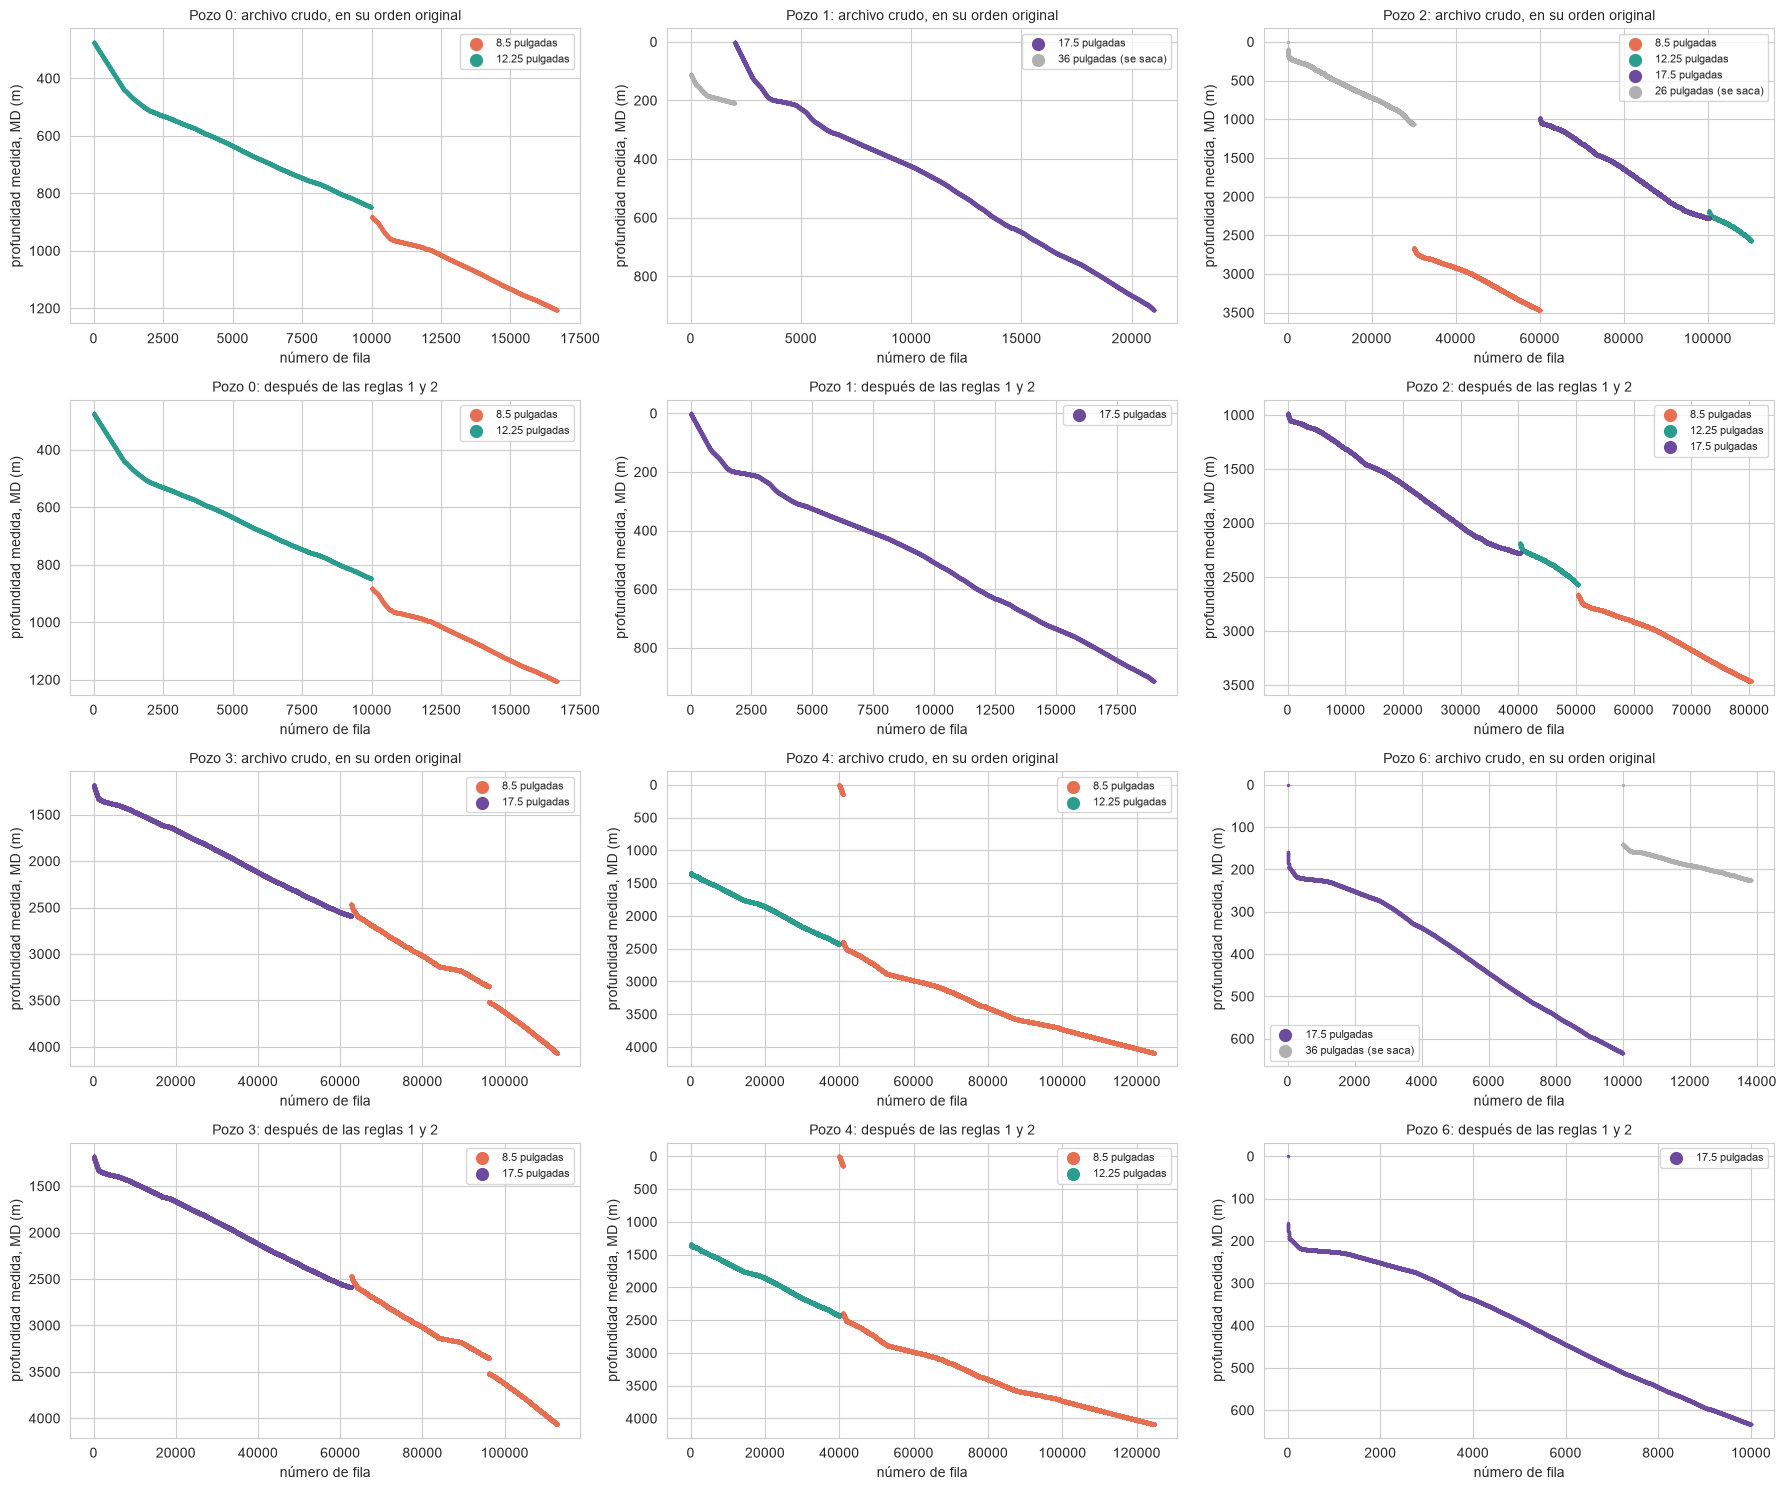

In [8]:

def color_tramo(p):
    paleta = {17.5: '#6c4a9e', 12.25: '#2a9d8f', 8.5: '#e76f51'}
    return '#b0b0b0' if p >= 26 else paleta.get(p, '#444444')

pozos_vis = [0, 1, 2, 3, 4, 6]
fig, axes = plt.subplots(4, 3, figsize=(18, 15))
for n_pozo, k in enumerate(pozos_vis):
    bloque, col = n_pozo // 3, n_pozo % 3          # 2 bloques de 3 pozos; cada pozo ocupa 2 filas (crudo y después)
    d = cargar_pozo(k)                             # orden original del archivo
    listo = preparar_pozo(d)                       # después de las reglas 1 y 2
    for fila, tabla, titulo in [(2 * bloque, d, 'archivo crudo, en su orden original'), (2 * bloque + 1, listo, 'después de las reglas 1 y 2')]:
        ax = axes[fila, col]
        for p, g in tabla.groupby('pulgadas'):
            etiqueta = f'{p:g} pulgadas' + (' (se saca)' if p >= 26 else '')
            ax.scatter(g.index, g['Measured Depth m'], s=2, color=color_tramo(p), label=etiqueta)
        ax.set_title(f'Pozo {k}: {titulo}', fontsize=10)
        ax.set_xlabel('número de fila')
        ax.set_ylabel('profundidad medida, MD (m)')
        ax.invert_yaxis()
        ax.legend(markerscale=6, fontsize=8)
plt.tight_layout()
plt.show()


El segundo gráfico que mostramos son **las filas de cada tramo**, y cuáles se sacan con la regla 1:

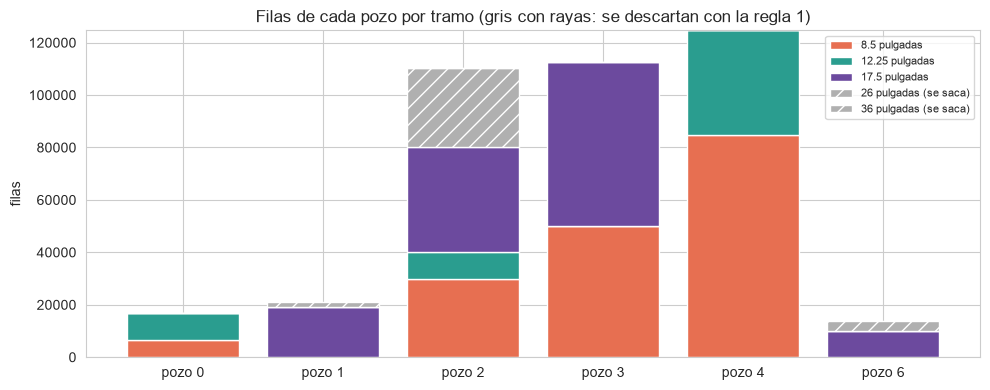

,pozo 0,pozo 1,pozo 2,pozo 3,pozo 4,pozo 6
diámetro (pulgadas),,,,,,
8.50,6670,0,30000,50000,84636,0
12.25,10000,0,10000,0,40000,0
17.50,0,19018,40301,62714,0,10000
26.00,0,0,30000,0,0,0
36.00,0,1995,0,0,0,3830


In [9]:
filas_por_tramo = pd.DataFrame({nombre_pozo[k]: cargar_pozo(k).groupby('pulgadas').size() for k in range(7) if k != POZO_TEST}).fillna(0).astype(int)
filas_por_tramo.index.name = 'diámetro (pulgadas)'

fig, ax = plt.subplots(figsize=(10, 4))
base = np.zeros(filas_por_tramo.shape[1])
for p in filas_por_tramo.index:
    valores = filas_por_tramo.loc[p].values
    ax.bar(filas_por_tramo.columns, valores, bottom=base, color=color_tramo(p),
           hatch='//' if p >= 26 else None, edgecolor='white', label=f'{p:g} pulgadas' + (' (se saca)' if p >= 26 else ''))
    base += valores
ax.set_ylabel('filas')
ax.set_title('Filas de cada pozo por tramo (gris con rayas: se descartan con la regla 1)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
filas_por_tramo

<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Qué se ve en 2.2.1:** 

- **Pozos 0, 3 y 4:** no tienen tramos de 26 pulgadas o más y sus filas ya vienen en orden de perforación (de mayor a menor diámetro): las reglas 1 y 2 **no cambian nada**. El pozo 0 va de 12,25 a 8,5 pulgadas; el pozo 3, de 17,5 a 8,5 (los dos tramos se pisan entre ~2.480 y 2.600 m); el pozo 4, de 12,25 a 8,5.
- **Pozos 1 y 6:** el archivo trae un tramo de 36 pulgadas (de ~110 a 210 m en el pozo 1; de ~140 a 226 m en el pozo 6) que **se pisa en profundidad** con el de 17,5 pulgadas. La regla 1 saca el de 36.
- **Pozo 2:** el archivo **no está ordenado por profundidad**: primero el tramo de 26 pulgadas (0 a ~1.070 m, se saca), después el de 8,5 (2.670 a 3.466 m) y recién después los de 17,5 (1.000 a 2.290 m) y de 12,25 (2.200 a 2.580 m). Ordenando de mayor a menor diámetro, que es el orden en que se perfora, la profundidad queda creciente.
- **Una rareza del pozo 4:** hay 958 filas etiquetadas como tramo de 8,5 pulgadas a profundidades de 0 a 146 m (arriba, cerca de la fila 40.000), cuando ese tramo empieza recién a los ~2.390 m. Ninguna tiene datos de superficie, así que no afectan las filas completas (lo retomamos en la Parte 7).
- **Cuántas filas saca la regla 1:** 30.000 del pozo 2 (26 pulgadas), 3.830 del pozo 6 y 1.995 del pozo 1.

</div>

### 2.3 Regla 3: valores imposibles y lecturas sin perforar → `NaN`

Un valor imposible (un torque negativo, un ROP de 7.000 m/h) no es un dato *faltante*, es un dato *malo*. Lo pasamos a `NaN` y **no borramos la fila entera**, porque el resto de la fila puede estar bien.

**Por qué estos límites.** No vienen de una norma: donde hay una base física se usa, y donde no, se respalda con los datos (2.3.4). Cada regla tiene su razón:

| Regla | Por qué |
|---|---|
| **Pisos:** WOB, torque, presión, caudal y ROP ≥ 0 | Físicamente no existen valores negativos de estas magnitudes. Se descartan solo los negativos, no los ceros: un cero puede ser una medición real (bomba parada, mecha levantada del fondo). |
| **WOB ≤ 35 kkgf** | Si el WOB fuera real, el hookload bajaría en la misma cantidad cuando la mecha apoya en el fondo (se comprueba en 2.3.4). Además, 35 kkgf (77.162 lbf) supera lo que se recomienda para mechas PDC: 1.000 a 2.500 lbf por pulgada de diámetro ([Drilling Manual](https://www.drillingmanual.com/pdc-bit-drilling-parameters/)). |
| **Presión ≤ 51.700 kPa** | Es el máximo que pueden dar las bombas del equipo que perforó Volve, el Mærsk Inspirer: 7.500 psi = 51.700 kPa ([Offshore](https://www.offshore-mag.com/drilling-completion/article/16759717/new-jackups-designed-for-multiple-roles), [OGJ](https://www.ogj.com/drilling-production/drilling-operations/article/17217493/special-report-dubai-contracts-first-new-maersk-jack-up)). El equipo no puede dar más presión que esa. |
| **ROP ≤ 100 m/h** (se descarta lo que supera 100) | El ROP real depende de la roca, la mecha y la profundidad, así que no hay un tope físico exacto. Pero en los pozos las lecturas normales están por debajo de ~100 m/h (el 99 % de las que se conservan no pasa de 65), y lo que supera 100 va de 100 hasta más de 20.000 m/h, algo imposible para una mecha (21.200 m/h son casi 6 metros por segundo). Por eso 100 es un corte práctico: casi todo lo descartado está muy por encima, y subirlo a 125 solo recuperaría 39 filas. |
| **Operativa:** el ROP se descarta si RPM < 20 o caudal < 500 L/min | El ROP solo mide perforación cuando la mecha gira y hay circulación de lodo. Sin eso, lo que se mide es la velocidad de bajada de la sarta (2.3.6). |

**Un detalle de pandas que importa:** un casillero vacío (`NaN`) no es mayor ni menor que nada, así que una comparación como "WOB > 35" da "no". Por eso los vacíos no cuentan como valores malos, que es justo lo que queremos (casi todas las filas están vacías).

#### 2.3.1 Las reglas en código

Se definen una sola vez, como funciones, y cada pozo las usa.

In [10]:
reglas_imposibles = [
    ('WOB < 0',         'Weight on Bit kkgf',             lambda s: s < 0),
    ('WOB > 35',        'Weight on Bit kkgf',             lambda s: s > 35),
    ('Torque < 0',      'Average Surface Torque kN.m',    lambda s: s < 0),
    ('Presión < 0',     'Average Standpipe Pressure kPa', lambda s: s < 0),
    ('Presión > 51700', 'Average Standpipe Pressure kPa', lambda s: s > 51700),   # 7.500 psi: presión máxima de las bombas del equipo
    ('Caudal < 0',      'Mud Flow In L/min',              lambda s: s < 0),
    ('ROP < 0',         'Rate of Penetration m/h',        lambda s: s < 0),
    ('ROP > 100',       'Rate of Penetration m/h',        lambda s: s > 100),
]

def invalidar_imposibles(d):
    """Regla 3: pasa a NaN cada valor imposible y el ROP de las lecturas sin perforar. Devuelve la tabla corregida y cuántos valores cayó cada regla."""
    d = d.copy()
    conteo = {}
    for nombre, col, es_malo in reglas_imposibles:
        malos = es_malo(d[col])            # NaN da False: los vacíos no cuentan como malos
        conteo[nombre] = int(malos.sum())
        d.loc[malos, col] = np.nan
    # Regla operativa: el ROP solo tiene sentido si la mecha gira y hay circulación de lodo
    sin_perforar = (d['Average Rotary Speed rpm'] < 20) | (d['Mud Flow In L/min'] < 500)
    afectadas = sin_perforar & d[objetivo].notna()
    conteo['ROP sin perforar (RPM<20 o caudal<500)'] = int(afectadas.sum())
    d.loc[afectadas, objetivo] = np.nan
    return d, pd.Series(conteo, name='valores invalidados')

#### 2.3.2 Qué hacen las reglas: mirar los datos crudos con el límite marcado

Para ver con los ojos qué descarta cada regla, juntamos los valores crudos de los **6 pozos de entrenamiento** (el pozo 5, test, no se toca) ya sin los tramos de 26 pulgadas o más, y dibujamos las cuatro variables en las que **efectivamente se descarta algo**: WOB, presión, ROP y torque. En el caudal la regla (≥ 0) no descarta nada en ningún pozo, y la RPM y el hookload no tienen reglas propias. **Rojo = lo que se descarta.** El eje vertical está en escala logarítmica, para que se vean también las colas con pocos valores.

In [11]:
pozos_entrenamiento = [k for k in range(7) if k != POZO_TEST]
prep_todos = {k: preparar_pozo(cargar_pozo(k)) for k in pozos_entrenamiento}
juntos = pd.concat([d.assign(pozo=nombre_pozo[k]) for k, d in prep_todos.items()], ignore_index=True)
print('Filas juntas (6 pozos de entrenamiento, sin tramos de 26 pulgadas o más):', len(juntos))

Filas juntas (6 pozos de entrenamiento, sin tramos de 26 pulgadas o más): 363339


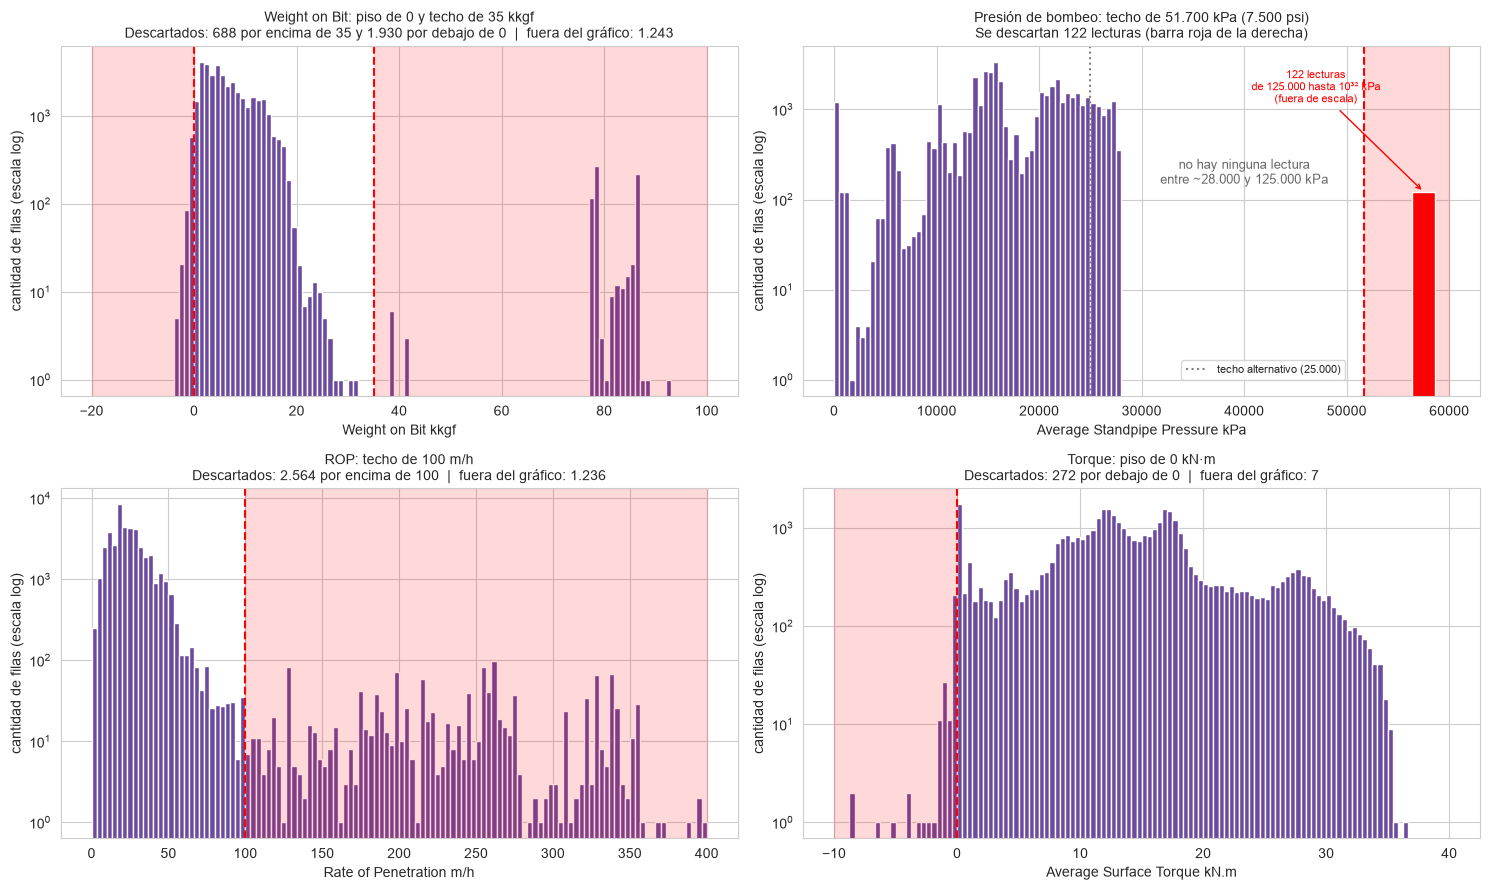

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
miles = lambda n: f'{n:,}'.replace(',', '.')

def panel(ax, col, rango, piso=None, techo=None, titulo=''):
    s = juntos[col].dropna()
    ax.hist(s, bins=120, range=rango, color='#6c4a9e')          # solo se dibuja lo que cae dentro del rango
    partes = []
    if techo is not None:
        ax.axvspan(techo, rango[1], color='red', alpha=0.15)
        ax.axvline(techo, color='red', linestyle='--')
        partes.append(f'{miles(int((s > techo).sum()))} por encima de {miles(techo)}')
    if piso is not None:
        ax.axvspan(rango[0], piso, color='red', alpha=0.15)
        ax.axvline(piso, color='red', linestyle='--')
        partes.append(f'{miles(int((s < piso).sum()))} por debajo de {piso}')
    fuera = int(((s < rango[0]) | (s > rango[1])).sum())
    ax.set_yscale('log')
    ax.set_title(titulo + '\nDescartados: ' + ' y '.join(partes) + (f'  |  fuera del gráfico: {miles(fuera)}' if fuera else ''), fontsize=10)
    ax.set_xlabel(col)
    ax.set_ylabel('cantidad de filas (escala log)')

panel(axes[0, 0], 'Weight on Bit kkgf', (-20, 100), piso=0, techo=35, titulo='Weight on Bit: piso de 0 y techo de 35 kkgf')
panel(axes[0, 1], 'Average Standpipe Pressure kPa', (0, 60000), techo=51700, titulo='Presión de bombeo: techo de 51.700 kPa (7.500 psi)')
axes[0, 1].axvline(25000, color='grey', linestyle=':', label='techo alternativo (25.000)')
axes[0, 1].legend(loc='lower center', bbox_to_anchor=(0.68, 0.03), fontsize=8)
axes[0, 1].text(40000, 150, 'no hay ninguna lectura\nentre ~28.000 y 125.000 kPa', ha='center', fontsize=9, color='dimgrey')
# las lecturas descartadas están muy por encima del eje: las mostramos como una sola barra roja al final
n_absurdas = int((juntos['Average Standpipe Pressure kPa'] > 51700).sum())
axes[0, 1].bar(57500, n_absurdas, width=2200, color='red')
axes[0, 1].annotate(f'{n_absurdas} lecturas\nde 125.000 hasta 10³² kPa\n(fuera de escala)', xy=(57500, n_absurdas), xytext=(47000, 1200), fontsize=8, color='red', ha='center',
                    arrowprops=dict(arrowstyle='->', color='red'))
axes[0, 1].set_title('Presión de bombeo: techo de 51.700 kPa (7.500 psi)\nSe descartan 122 lecturas (barra roja de la derecha)', fontsize=10)
panel(axes[1, 0], 'Rate of Penetration m/h', (0, 400), techo=100, titulo='ROP: techo de 100 m/h')
panel(axes[1, 1], 'Average Surface Torque kN.m', (-10, 40), piso=0, titulo='Torque: piso de 0 kN·m')
plt.tight_layout()
plt.show()

Y el resultado de aplicar **todas** las reglas: cuántos valores descarta cada una, en cada pozo:

In [13]:
conteos = pd.DataFrame({nombre_pozo[k]: invalidar_imposibles(d)[1] for k, d in prep_todos.items()})
conteos

,pozo 0,pozo 1,pozo 2,pozo 3,pozo 4,pozo 6
WOB < 0,1261,0,0,534,135,0
WOB > 35,0,0,0,679,9,0
Torque < 0,223,26,0,3,9,11
Presión < 0,0,0,0,0,0,0
Presión > 51700,0,0,0,122,0,0
Caudal < 0,0,0,0,0,0,0
ROP < 0,0,0,0,0,0,0
ROP > 100,1182,9,1,1274,95,3
ROP sin perforar (RPM<20 o caudal<500),69,2,2,219,219,0


<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Qué se ve:** 

- **Weight on Bit:** los valores razonables terminan en ~31 kkgf; entre ~43 y ~77 casi no hay nada, y después aparece un grupo aparte de 77 a 93 kkgf (casi todo en el pozo 3). El techo de 35 cae **en ese hueco**: separa dos poblaciones distintas de datos. También hay 1.930 valores negativos (piso).
- **Presión de bombeo:** los valores llegan hasta unos 28.000 kPa (4.000 psi) y después **hay un hueco enorme**: recién desde 125.000 kPa aparecen 122 valores absurdos (hasta 10³² kPa), fuera del gráfico. El techo que usamos (51.700 kPa, el máximo de las bombas del equipo) cae en ese hueco. Un techo de 25.000 (línea punteada gris) cortaría una zona con datos.
- **ROP:** la masa de valores está entre 0 y 75 m/h. A partir de 100 la distribución cambia: una cola larga y pareja que llega a más de 20.000 m/h. No hay hueco, pero sí un cambio claro de comportamiento cerca de 100.
- **Torque:** casi todo es positivo; los negativos son pocos y sueltos (272 en total).
- **Por pozo:** lo que se descarta está casi todo en **el pozo 0** (unos 2.700 valores: WOB negativo y ROP) y **el pozo 3** (unos 2.600: ROP, WOB y los valores absurdos de presión). El pozo 4 pierde unos 250 y los pozos 1, 2 y 6 casi nada.

</div>

#### 2.3.3 Dónde caen los valores descartados

Los histogramas de 2.3.2 muestran **cuánto** se descarta, pero no **dónde**. Acá se ve, en los tres casos más claros, cada lectura contra la profundidad: en **gris** lo que se conserva, en **rojo** lo que se descarta y en **naranja** la presión entre 25.000 y 51.700 kPa, que se conserva porque son lecturas posibles. La pregunta es: ¿son **picos sueltos** (errores de sensor al azar) o **tramos continuos** de lecturas seguidas? (Escala vertical logarítmica; las líneas rojas son los límites.)

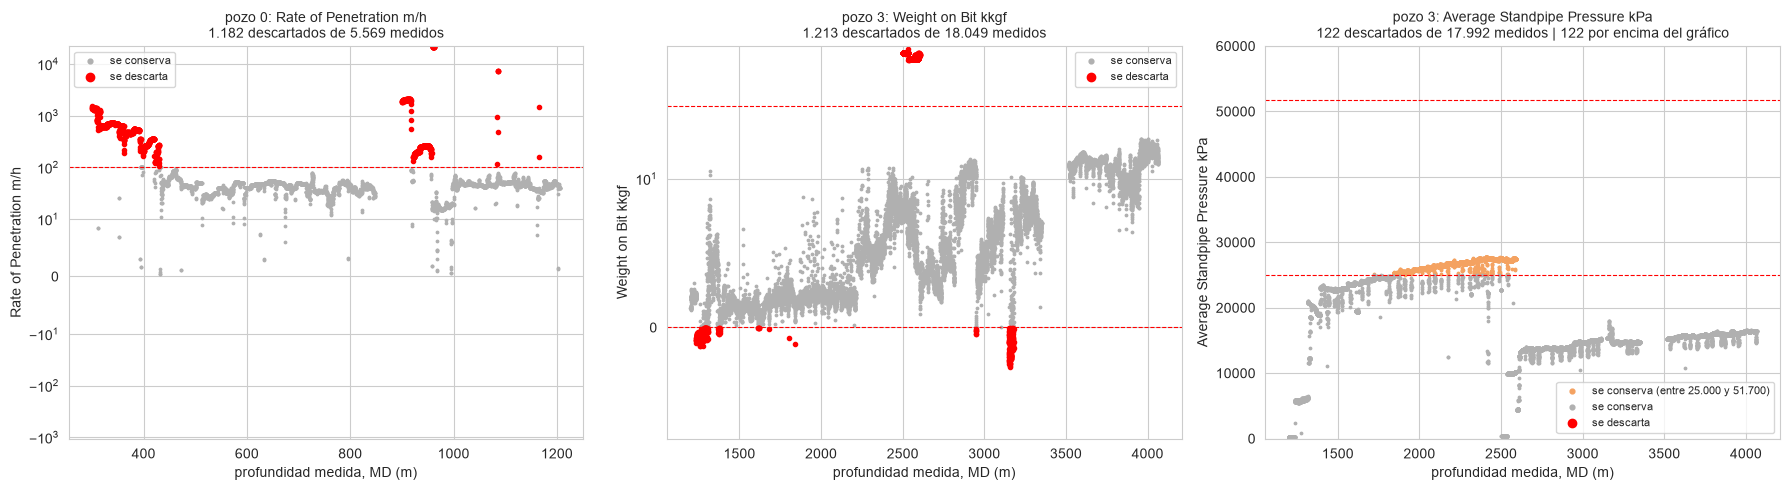

In [14]:
def panel_descartes(ax, k, col, es_malo, limites, linthresh=None, ylim=None, extra=None):
    d = prep_todos[k]
    valores = d[col]
    malo = es_malo(valores)                              # NaN da False: los vacíos no cuentan
    conservado = valores.notna() & ~malo
    if extra is not None:                                # lecturas entre un techo más bajo (25.000) y el que usamos
        naranja = extra(valores) & ~malo
        conservado = conservado & ~naranja
        ax.scatter(d.loc[naranja, 'Measured Depth m'], valores[naranja], s=3, color='#f4a261', label='se conserva (entre 25.000 y 51.700)')
    ax.scatter(d.loc[conservado, 'Measured Depth m'], valores[conservado], s=3, color='#b0b0b0', label='se conserva')
    ax.scatter(d.loc[malo, 'Measured Depth m'], valores[malo], s=9, color='red', label='se descarta')
    for lim in limites:
        ax.axhline(lim, color='red', linestyle='--', linewidth=0.8)
    texto_extra = ''
    if linthresh:
        ax.set_yscale('symlog', linthresh=linthresh)
    if ylim:                                             # escala lineal con tope: contamos lo que queda fuera del gráfico
        ax.set_ylim(*ylim)
        fuera = int((valores[malo] > ylim[1]).sum())
        texto_extra = f' | {fuera} por encima del gráfico' if fuera else ''
    ax.set_title(f'{nombre_pozo[k]}: {col}\n{int(malo.sum()):,} descartados de {int(valores.notna().sum()):,} medidos'.replace(',', '.') + texto_extra, fontsize=10)
    ax.set_xlabel('profundidad medida, MD (m)')
    ax.set_ylabel(col)
    ax.legend(fontsize=8, markerscale=2)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
panel_descartes(axes[0], 0, 'Rate of Penetration m/h', lambda s: s > 100, limites=[100], linthresh=10)
panel_descartes(axes[1], 3, 'Weight on Bit kkgf', lambda s: (s < 0) | (s > 35), limites=[0, 35], linthresh=10)
panel_descartes(axes[2], 3, 'Average Standpipe Pressure kPa', lambda s: s > 51700, limites=[25000, 51700], ylim=(0, 60000), extra=lambda s: s > 25000)
plt.tight_layout()
plt.show()

<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Qué se ve en 2.3.3:**

- **ROP > 100 m/h:** los puntos rojos **no están sueltos**: aparecen **agrupados en tramos puntuales**, y en cada tramo arrancan altísimos (hasta ~1.500 m/h) y bajan hasta valores normales. No es perforación real (se explica en 2.3.6).
- **WOB:** en el pozo 3 hay **un solo tramo** (entre los 2.500 y 2.604 m) con ~78 kkgf, rodeado de lecturas de ~4: un desajuste del sensor. En el pozo 0, los negativos (~−53 kkgf) están todos en un tramo de 300 a 490 m: error de sensor. En los pozos 3 y 4 son negativos chicos (−1 a −3), ruido alrededor de cero.
- **Presión:** solo se descartan 122 valores absurdos del pozo 3 (hasta 10³² kPa). Lo naranja es un tramo continuo que cruza 25.000 sin saltos: son lecturas posibles, por eso se conservan.

**En conclusión:** lo que se descarta con ROP > 100 y con WOB > 35 es claramente anómalo (tramos que no se parecen a las lecturas de al lado). Un techo de presión de 25.000 cortaría datos buenos, por eso usamos 51.700.

</div>

#### 2.3.4 Comprobar los límites con los datos

La tabla de 2.3 da las razones; acá se contrastan con lo que miden los pozos. Primero, los ceros, que se conservan porque pueden ser mediciones reales. Cuántos hay:

In [15]:
ceros = juntos[['Weight on Bit kkgf', 'Mud Flow In L/min', 'Average Surface Torque kN.m', densidad]].eq(0).sum()
medidos = juntos[['Weight on Bit kkgf', 'Mud Flow In L/min', 'Average Surface Torque kN.m', densidad]].notna().sum()
pd.DataFrame({'lecturas con valor exactamente 0': ceros, 'lecturas medidas': medidos, '% de ceros': (100 * ceros / medidos).round(2)})

,lecturas con valor exactamente 0,lecturas medidas,% de ceros
Weight on Bit kkgf,6,38758,0.02
Mud Flow In L/min,1521,45619,3.33
Average Surface Torque kN.m,198,41335,0.48
Mud Density In g/cm3,0,10650,0.00


**Lectura:** los ceros casi no importan para el WOB (6 lecturas), el torque (198, un 0,5 %) ni la densidad (ninguno). Pero **el caudal vale exactamente 0 en 1.521 lecturas (3,3 %)**: es la bomba parada (por ejemplo, durante una conexión de tubería), algo que ocurre de verdad. Por eso no se descartan: no son un valor imposible.

Primero, unas conversiones de unidades para poder comparar: `1 kkgf` = 1.000 kgf ≈ 2.205 lbf, y `1 psi` ≈ 6,895 kPa.

In [16]:
# Referencia para el WOB: para mechas PDC en formaciones blandas a medias se recomiendan 1.000 a 2.500 lbf por pulgada de diámetro
# (Drilling Manual, "Operating Parameters for PDC Bits"). Lo pasamos a kkgf para cada diámetro de mecha que hay en los pozos.
LBF_POR_KKGF = 2204.62
referencia_wob = pd.DataFrame({'diámetro (pulgadas)': [8.5, 12.25, 17.5]})
referencia_wob['recomendado mínimo (kkgf)'] = (referencia_wob['diámetro (pulgadas)'] * 1000 / LBF_POR_KKGF).round(1)
referencia_wob['recomendado máximo (kkgf)'] = (referencia_wob['diámetro (pulgadas)'] * 2500 / LBF_POR_KKGF).round(1)

# Lo que realmente midieron los pozos en cada diámetro (solo valores válidos, <= 35)
wob_valido = juntos[(juntos['Weight on Bit kkgf'] >= 0) & (juntos['Weight on Bit kkgf'] <= 35)]
observado = wob_valido.groupby('pulgadas')['Weight on Bit kkgf'].agg(mediana='median', p99=lambda s: s.quantile(0.99), máximo='max').round(1)
referencia_wob = referencia_wob.merge(observado, left_on='diámetro (pulgadas)', right_index=True, how='left')
print('El techo de 35 kkgf equivale a', round(35 * LBF_POR_KKGF), 'lbf.')
referencia_wob

El techo de 35 kkgf equivale a 77162 lbf.


,diámetro (pulgadas),recomendado mínimo (kkgf),recomendado máximo (kkgf),mediana,p99,máximo
0,8.50,3.9,9.6,8.0,18.0,31.4
1,12.25,5.6,13.9,5.9,18.8,20.1
2,17.50,7.9,19.8,2.4,9.3,25.6


In [17]:
# Presión: pasamos el techo y las presiones de trabajo típicas de los equipos de standpipe a kPa
KPA_POR_PSI = 6.895
print(f'Un techo de 25.000 kPa = {25000 / KPA_POR_PSI:,.0f} psi'.replace(',', '.'))
print(f'Techo que usamos: 51.700 kPa = {51700 / KPA_POR_PSI:,.0f} psi (bombas del equipo, 7.500 psi)'.replace(',', '.'))
for psi in (3000, 5000, 7500):
    print(f'Presión de trabajo de {psi:,} psi = {psi * KPA_POR_PSI:,.0f} kPa'.replace(',', '.'))

# ¿Hay un hueco en los datos cerca del techo de 25.000?
p = juntos['Average Standpipe Pressure kPa'].dropna()
franjas = pd.cut(p, [0, 12500, 18750, 25000, 31250, 50000, 125000, np.inf])
print()
print('Cantidad de valores por franja de presión (kPa):')
print(franjas.value_counts().sort_index().to_string())
print()
print('Valor más alto que es "razonable" (por debajo de 50.000 kPa):', round(p[p < 50000].max()))
print('Valores por encima de 50.000 kPa:', int((p > 50000).sum()), '| el mayor:', f'{p.max():.2e}')

Un techo de 25.000 kPa = 3.626 psi
Techo que usamos: 51.700 kPa = 7.498 psi (bombas del equipo. 7.500 psi)
Presión de trabajo de 3.000 psi = 20.685 kPa
Presión de trabajo de 5.000 psi = 34.475 kPa
Presión de trabajo de 7.500 psi = 51.712 kPa

Cantidad de valores por franja de presión (kPa):
Average Standpipe Pressure kPa
(0.0, 12500.0]          6067
(12500.0, 18750.0]     17019
(18750.0, 25000.0]     16502
(25000.0, 31250.0]      5728
(31250.0, 50000.0]         0
(50000.0, 125000.0]        0
(125000.0, inf]          122

Valor más alto que es "razonable" (por debajo de 50.000 kPa): 27767
Valores por encima de 50.000 kPa: 122 | el mayor: 1.30e+32


In [18]:
# ROP: ¿cómo se reparten los valores alrededor del techo de 100 m/h?
r = juntos[objetivo].dropna()
franjas_rop = pd.cut(r, [0, 25, 50, 75, 100, 125, 200, 500, 2000, np.inf])
print('Cantidad de valores por franja de ROP (m/h):')
print(franjas_rop.value_counts().sort_index().to_string())
print()
print('ROP válido (<= 100): percentil 99 =', round(r[r <= 100].quantile(0.99), 1), '| máximo =', round(r[r <= 100].max(), 1))
print('ROP descartado (> 100): mediana =', round(r[r > 100].median()), '| máximo =', round(r.max()), 'm/h  (equivale a', round(r.max() / 3600, 1), 'm por segundo)')

Cantidad de valores por franja de ROP (m/h):
Rate of Penetration m/h
(0.0, 25.0]        25027
(25.0, 50.0]       16087
(50.0, 75.0]        1501
(75.0, 100.0]        209
(100.0, 125.0]        67
(125.0, 200.0]       395
(200.0, 500.0]      1053
(500.0, 2000.0]      948
(2000.0, inf]        101

ROP válido (<= 100): percentil 99 = 65.5 | máximo = 99.7
ROP descartado (> 100): mediana = 353 | máximo = 21200 m/h  (equivale a 5.9 m por segundo)


Lo que dicen los datos sobre cada límite:

| Límite | Qué dicen los datos | Veredicto |
| --- | --- | --- |
| **WOB ≤ 35 kkgf** | Los valores razonables llegan hasta 31,4 kkgf; entre ~43 y ~77 casi no hay nada, y los 688 descartados caen entre 38 y 93 kkgf. 679 de ellos (pozo 3) forman **un único bloque continuo**, rodeado de WOB de ~4 kkgf (ver 2.3.3) | **Sí**: esas lecturas son físicamente imposibles. El número 35 cae en un hueco de los datos |
| **Presión ≤ 51.700 kPa** | Los valores llegan hasta ~27.800 kPa (4.000 psi); no hay nada entre ahí y 125.000; recién después aparecen 122 valores absurdos (hasta 10³² kPa) | **Sí**: es un límite físico. Cualquier techo entre ~28.000 y 125.000 kPa da el mismo resultado. Un techo de 25.000 kPa (3.626 psi) cortaría 5.728 lecturas posibles de los pozos 3 y 4 |
| **ROP ≤ 100 m/h** | Los valores razonables tienen percentil 99 en 65 m/h y máximo 99,7. Los descartados van de 100 a 21.200 m/h (mediana 353) y **no son picos sueltos**: en el pozo 0, 1.182 valores forman unos pocos tramos continuos rodeados de ROP normal (~26 m/h) (ver 2.3.3) | **Criterio práctico**, no físico. El número importa poco: casi todo lo descartado está muy por encima de 100, y subir el techo a 125 solo recupera 39 filas (ver 2.3.5) |
| **Pisos (≥ 0)** | Hay 1.930 WOB negativos y 272 torques negativos; presión, caudal y ROP no tienen | **Sí** |

**Prueba física del WOB.** Si el WOB reportado fuera real, el hookload tendría que bajar en esa misma cantidad. Comparamos los dos bloques que se descartan con el resto de las lecturas de su pozo:

In [19]:

H, W = 'Average Hookload kkgf', 'Weight on Bit kkgf'
casos = [('pozo 3: WOB > 35 (se descarta)', 3, lambda d: d[W] > 35),
         ('pozo 3: resto de las lecturas',   3, lambda d: (d[W] >= 0) & (d[W] <= 35)),
         ('pozo 0: WOB < −20 (se descarta)', 0, lambda d: d[W] < -20),
         ('pozo 0: resto de las lecturas',   0, lambda d: (d[W] >= 0) & (d[W] <= 35))]
filas = []
for nombre, k, grupo in casos:
    d = prep_todos[k]
    d = d[d[H].notna() & d[W].notna()]
    g = grupo(d)
    filas.append({'caso': nombre, 'lecturas': int(g.sum()), 'WOB (mediana)': round(d.loc[g, W].median(), 1),
                  'hookload (mediana)': round(d.loc[g, H].median(), 1), 'WOB + hookload (mediana)': round((d.loc[g, W] + d.loc[g, H]).median(), 1)})
pd.DataFrame(filas).set_index('caso')


,lecturas,WOB (mediana),hookload (mediana),WOB + hookload (mediana)
caso,,,,
pozo 3: WOB > 35 (se descarta),679,78.5,129.6,208.1
pozo 3: resto de las lecturas,16836,5.1,130.6,136.8
pozo 0: WOB < −20 (se descarta),1243,-53.3,92.9,39.5
pozo 0: resto de las lecturas,4342,9.3,94.3,100.7


**Cómo se lee:** en el pozo 3, el bloque con WOB ≈ 78 tiene el mismo hookload que el resto (≈130), así que **la suma da 208 contra 137**: ese peso nunca se aplicó sobre la mecha. En el pozo 0, el bloque con WOB ≈ −53 no sube el hookload (≈93 contra ≈94): **la suma da 40 contra 101**. Los dos bloques violan la relación física, y por eso se descartan.

**¿Se comportan parecido los 6 pozos?** Como son del mismo campo, esperamos rangos similares. Para cada variable con techo: la mediana y el percentil 99 de las lecturas **válidas**, y el porcentaje de lecturas medidas que se descarta.

In [20]:

comparacion_pozos = {}
for k, d in prep_todos.items():
    fila = {}
    for nombre, col, tope in [('WOB', 'Weight on Bit kkgf', 35), ('Presión', 'Average Standpipe Pressure kPa', 51700), ('ROP', 'Rate of Penetration m/h', 100)]:
        s = d[col].dropna()
        validos = s[(s >= 0) & (s <= tope)]
        fila[(nombre, 'mediana')] = round(validos.median(), 1)
        fila[(nombre, 'p99')] = round(validos.quantile(0.99), 1)
        fila[(nombre, '% descartado')] = round(100 * (1 - len(validos) / len(s)), 1)
    comparacion_pozos[nombre_pozo[k]] = fila
pd.DataFrame(comparacion_pozos).T


WOB                     Presión                           ROP                   
       mediana   p99 % descartado  mediana      p99 % descartado mediana   p99 % descartado
pozo 0     9.3  18.6         22.5  10344.7  15350.3          0.0    44.5  88.2         21.2
pozo 1     4.0  23.4          0.0  15809.5  17835.4          0.0    42.8  76.9          1.4
pozo 2     5.3  13.2          0.0  17495.0  24214.6          0.0    29.2  52.3          0.0
pozo 3     5.1  17.3          6.7  16283.1  27548.0          0.7    19.9  61.0          7.1
pozo 4     5.7  18.4          1.2  21161.7  25771.0          0.0    20.5  44.9          0.5
pozo 6     4.4   8.0          0.0  13936.5  15280.9          0.0    54.8  90.3          0.7

<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Qué se ve:** 

- **Los 6 pozos se parecen** una vez sacados los valores imposibles: el WOB tiene mediana de 4 a 9 kkgf, el ROP de 20 a 55 m/h, y la presión crece con la profundidad (15.000 a 18.000 kPa en los pozos de hasta ~1.200 m; 24.000 a 28.000 en los de 3.500 a 4.000 m).
- **Lo descartado no es parejo: se concentra en los pozos 0 y 3.** El pozo 0 pierde el 21 % de sus lecturas de ROP y el 22 % de las de WOB; el pozo 3, el 7 % de las dos. En los otros cuatro pozos el descarte es de 1,4 % o menos. No es un problema del campo: son fallas de esos dos registros.
- **El techo de 100 m/h para el ROP es el menos sólido de los tres**: no tiene base física propia, y en los pozos 0, 3 y 4 el máximo válido queda pegado al techo (99,7, 99,6 y 96,7 m/h). Pero lo que descarta son sobre todo lecturas de maniobra, sin perforar (ver 2.3.6).

</div>

#### 2.3.5 ¿Cuánto cambia si se mueven los techos?

Para ver cuánto pesa cada decisión, contamos cuántas **filas completas** queda cada pozo con un techo de presión de 25.000 kPa, con el que usamos (51.700 kPa) y con todas las reglas, incluida la operativa:

In [21]:
def completas_segun(d, techo_wob=35, techo_presion=51700, techo_rop=100, regla_operativa=True):
    """Cuántas filas completas quedan si se usan estos techos (los pisos de 0 son los mismos)."""
    x = d.copy()
    malas = {
        'Weight on Bit kkgf':              lambda s: (s < 0) | (s > techo_wob),
        'Average Surface Torque kN.m':     lambda s: s < 0,
        'Average Standpipe Pressure kPa':  lambda s: (s < 0) | (s > techo_presion),
        'Mud Flow In L/min':               lambda s: s < 0,
        'Rate of Penetration m/h':         lambda s: (s < 0) | (s > techo_rop),
    }
    for col, es_mala in malas.items():
        x.loc[es_mala(x[col]), col] = np.nan
    if regla_operativa:                       # el ROP solo vale si la mecha gira y hay circulación
        x.loc[(x['Average Rotary Speed rpm'] < 20) | (x['Mud Flow In L/min'] < 500), objetivo] = np.nan
    return int(x[grupo_superficie + ['Hole Depth (TVD) m']].notna().all(axis=1).sum())   # fila completa: las 7 variables + TVD

escenarios = {
    'presión hasta 25.000 (35 / 25.000 / 100)':  dict(techo_presion=25000, regla_operativa=False),
    'solo cambia la presión (51.700)':           dict(regla_operativa=False),
    'todas las reglas (con la regla operativa)':  dict(),
    'todas las reglas con ROP hasta 125':         dict(techo_rop=125),
}
sensibilidad = pd.DataFrame({nombre: {nombre_pozo[k]: completas_segun(d, **cfg) for k, d in prep_todos.items()}
                             for nombre, cfg in escenarios.items()})
sensibilidad.loc['TOTAL'] = sensibilidad.sum()
sensibilidad

,presión hasta 25.000 (35 / 25.000 / 100),solo cambia la presión (51.700),todas las reglas (con la regla operativa),todas las reglas con ROP hasta 125
pozo 0,3846,3846,3845,3846
pozo 1,603,603,602,602
pozo 2,2159,2161,2159,2159
pozo 3,11769,16375,16276,16310
pozo 4,10285,11392,11175,11176
pozo 6,400,400,400,403
TOTAL,29062,34777,34457,34496


#### 2.3.6 ¿Qué operación son las lecturas de ROP que se descartan?

El ROP solo mide perforación cuando la mecha **gira y hay circulación de lodo**. Para ver qué estaba pasando en las lecturas de ROP > 100, miramos la rotación (RPM) y el caudal en esas mismas filas, y las comparamos con las lecturas normales. Llamamos **"sin perforar"** a una lectura con RPM < 20 o caudal < 500 L/min.

In [22]:
columnas_operacion = ['name', 'Measured Depth m', 'Rate of Penetration m/h', 'Average Rotary Speed rpm', 'Mud Flow In L/min',
                      'Weight on Bit kkgf', 'Average Standpipe Pressure kPa', 'Bit run number unitless']

def leer_operacion(k):
    """Las columnas de operación de un pozo, con las reglas 1 y 2, y solo las filas con ROP medido."""
    d = pd.read_csv(archivos_crudos[k], usecols=lambda c: c in columnas_operacion or c == RPM_ALTERNATIVA)
    if RPM_ALTERNATIVA in d.columns:
        d[RPM] = d[RPM].fillna(d[RPM_ALTERNATIVA])
        d = d.drop(columns=[RPM_ALTERNATIVA])
    d['pulgadas'] = d['name'].map(pulgadas)
    d = preparar_pozo(d)
    return d[d['Rate of Penetration m/h'].notna()].reset_index(drop=True)

operacion = {k: leer_operacion(k) for k in pozos_entrenamiento}

filas = []
for k, d in operacion.items():
    alto = d['Rate of Penetration m/h'] > 100
    normal = d['Rate of Penetration m/h'].between(0, 100)
    sin_perforar = (d['Average Rotary Speed rpm'] < 20) | (d['Mud Flow In L/min'] < 500)
    filas.append({'pozo': nombre_pozo[k], 'lecturas con ROP > 100': int(alto.sum()),
                  '% de sus lecturas de ROP': round(100 * alto.mean(), 1),
                  '% de esas sin perforar': round(100 * sin_perforar[alto].mean()),
                  '% sin perforar en lecturas normales': round(100 * sin_perforar[normal].mean(), 1)})
pd.DataFrame(filas).set_index('pozo')

,lecturas con ROP > 100,% de sus lecturas de ROP,% de esas sin perforar,% sin perforar en lecturas normales
pozo,,,,
pozo 0,1182,21.2,78,1.6
pozo 1,9,1.4,100,0.3
pozo 2,1,0.0,100,0.1
pozo 3,1274,7.1,61,1.3
pozo 4,95,0.5,89,1.2
pozo 6,3,0.7,0,0.0


Y los bloques más largos de lecturas con ROP > 100, con el número de **corrida de mecha** y la profundidad donde empieza esa corrida:

In [23]:
filas = []
for k in [0, 3, 4]:
    d = operacion[k]
    alto = (d['Rate of Penetration m/h'] > 100).values
    posiciones = np.where(alto)[0]
    for b in np.split(posiciones, np.where(np.diff(posiciones) != 1)[0] + 1):
        x = d.iloc[b]
        corrida = x['Bit run number unitless'].dropna()
        corrida = corrida.mode().iloc[0] if len(corrida) else np.nan
        inicio = d.loc[d['Bit run number unitless'] == corrida, 'Measured Depth m'].min() if corrida == corrida else np.nan
        filas.append({'pozo': nombre_pozo[k], 'lecturas': len(b), 'MD desde (m)': round(x['Measured Depth m'].min()), 'MD hasta (m)': round(x['Measured Depth m'].max()),
                      'corrida de mecha': corrida, 'MD donde empieza la corrida': inicio, 'ROP (mediana)': round(x['Rate of Penetration m/h'].median()),
                      'RPM (mediana)': x['Average Rotary Speed rpm'].median(), 'caudal (mediana)': x['Mud Flow In L/min'].median(),
                      'presión (mediana)': x['Average Standpipe Pressure kPa'].median()})
bloques_operacion = pd.DataFrame(filas).sort_values('lecturas', ascending=False).groupby('pozo').head(4).sort_values(['pozo', 'MD desde (m)'])
bloques_operacion.round(0).set_index('pozo')

,lecturas,MD desde (m),MD hasta (m),corrida de mecha,MD donde empieza la corrida,ROP (mediana),RPM (mediana),caudal (mediana),presión (mediana)
pozo,,,,,,,,,
pozo 0,266,311,352,NaN,NaN,683,0.0,0.0,324.0
pozo 0,258,353,393,NaN,NaN,493,0.0,0.0,325.0
pozo 0,149,398,421,1.0,413.0,277,0.0,0.0,1153.0
pozo 0,225,922,956,2.0,901.0,244,140.0,1595.0,5382.0
pozo 3,216,1223,1256,3.0,1200.0,340,29.0,1994.0,5650.0
pozo 3,124,1278,1297,3.0,1200.0,328,30.0,1994.0,6034.0
pozo 3,230,2500,2535,NaN,NaN,1583,0.0,0.0,379.0
pozo 3,177,2536,2563,5.0,2542.0,262,0.0,1790.0,9943.0
pozo 4,3,1372,1372,2.0,1360.0,190,59.0,2991.0,12668.0


<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Qué operación es:** 

- **No es perforación.** En los pozos 0, 1, 2 y 4, entre el 78 % y el 100 % de las lecturas con ROP > 100 ocurren **sin perforar**: sin rotación o sin circulación de lodo, contra apenas 0,1 a 1,6 % de las lecturas normales. En el pozo 3 es el 61 %, y en el pozo 6 ninguna (son 3 lecturas apenas por encima de 100).
- **Aparecen justo antes o en los primeros metros de una corrida de mecha.** En el pozo 0, los dos bloques más largos (de 300 a 393 m, con RPM 0 y caudal 0) están antes de que empiece la corrida 1 (a 413 m); después hay bloques al arrancar la corrida 1 (de 398 a 430 m) y la corrida 2 (a 901 m, bloques de 900 a 962). En el pozo 3, la corrida 3 empieza a 1.200 m (bloques de 1.205 a 1.297) y la corrida 5 a 2.542 m (bloques de 2.500 a 2.587, con caudal 0 antes de que arranque). En el pozo 4, la corrida 6 empieza a 3.562 m (bloque de 3.571 a 3.582).
- **La huella de los sensores es la de una maniobra de bajada, lavado o escariado:** se baja la sarta con la mecha nueva, con la rotación y la bomba apagadas o reducidas (RPM de 0 a ~30; caudal de 0 o ~1.800 a 2.000 L/min, contra ~2.900 a 4.000 en lo normal), con la presión en 250 a 10.000 kPa (contra 11.000 a 27.000) y el WOB cerca de cero. La profundidad avanza rápido porque se mueve la sarta, no porque la mecha perfore: **ese "ROP" es la velocidad de bajada de la sarta.**
- **Qué hacemos:** como ese "ROP" no es perforación, la regla operativa de 2.3 lo descarta (RPM < 20 o caudal < 500 L/min), tenga el valor que tenga.
- **Efecto en las filas completas:** la regla quita 320 en total (217 del pozo 4 y 99 del pozo 3). En el pozo 1 quita una (la de 209 m, con RPM = 15), así que da 602 filas en vez de las 603 del Notebook 1.
- **Dónde:** sobre todo en el pozo 0 (21 % de sus lecturas de ROP) y en el pozo 3 (7 %). En los demás son muy pocas.

</div>

<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Conclusión de 2.3:**

- **Pisos (≥ 0):** física directa.
- **WOB ≤ 35 kkgf:** lo descartado es físicamente imposible (prueba con el hookload) y el límite cae en un hueco de los datos.
- **Presión ≤ 51.700 kPa:** el máximo que pueden dar las bombas del equipo (7.500 psi). Los datos llegan a ~27.800 kPa.
- **ROP ≤ 100 m/h:** criterio práctico (no hay un tope físico); el número importa poco.
- **ROP solo si se perfora (RPM ≥ 20 y caudal ≥ 500):** el ROP > 100 son sobre todo lecturas de maniobra, sin perforar (2.3.6); la regla operativa las saca por una razón física.
- **La presión es la decisión que más pesa.** Un techo de 25.000 kPa (3.626 psi) cortaría lecturas posibles: con 51.700 las filas completas de entrenamiento pasan de 29.062 a 34.777 (un 20 % más), sobre todo en el pozo 3 (de 11.769 a 16.375) y en el pozo 4 (1.107 más). La regla operativa quita después 320 filas (34.457 en total), casi todas del pozo 4 (217) y del pozo 3 (99). *(Estos totales ya incluyen la RPM del canal equivalente, 2.1.1.)*

</div>

*Referencia: el script del dataset original (`Code/making_USROP.py`, Tunkiel, Sui y Wiktorski, 2021) usa los mismos techos de WOB (35) y de ROP (100), con 25.000 kPa para la presión, y elimina la fila completa donde hay un valor fuera de rango; también descarta los ceros, mientras que acá solo se descartan los negativos. El script no explica el origen de esos límites, y el paper describe esa limpieza como en buena medida arbitraria (sección 3.2).*

### 2.4 Qué es una fila "completa" y con qué columnas nos quedamos

Como no rellenamos, el dataset final son **solo las filas donde los 6 sensores del núcleo y el ROP tienen dato real a la vez** (y la profundidad vertical, `TVD`). Las columnas finales son **10**, en el mismo orden que los pozos oficiales. `Mud Density` y `Gamma Ray` quedan afuera (no coinciden con el núcleo en todos los pozos), pero en cada pozo **informamos cuántas filas completas las tienen**.

In [24]:
orden_columnas = ['Measured Depth m', 'Weight on Bit kkgf', 'Average Standpipe Pressure kPa', 'Average Surface Torque kN.m',
                  'Rate of Penetration m/h', 'Average Rotary Speed rpm', 'Mud Flow In L/min', 'Diameter mm',
                  'Average Hookload kkgf', 'Hole Depth (TVD) m']

def filas_completas(d):
    """True en las filas donde las 7 variables del grupo de superficie y el TVD tienen dato real."""
    return d[grupo_superficie].notna().all(axis=1) & d['Hole Depth (TVD) m'].notna()

def armar_dataset(d):
    """Dataset final de un pozo: solo filas completas, con las 10 columnas en el orden oficial y sin filas idénticas repetidas."""
    return d.loc[filas_completas(d), orden_columnas].drop_duplicates().reset_index(drop=True)

#### 2.4.1 Verlo en los datos: de las filas del pozo a las filas completas

Dos gráficos. A la izquierda, **qué fracción** de las filas de cada pozo es completa, incompleta o no tiene ningún dato de superficie. A la derecha, **en qué profundidades** están las filas completas (cada raya es una fila): así se ve dónde hay datos reales y dónde hay huecos. Los dos usan los 6 pozos de entrenamiento, ya con las reglas 1, 2 y 3 aplicadas.

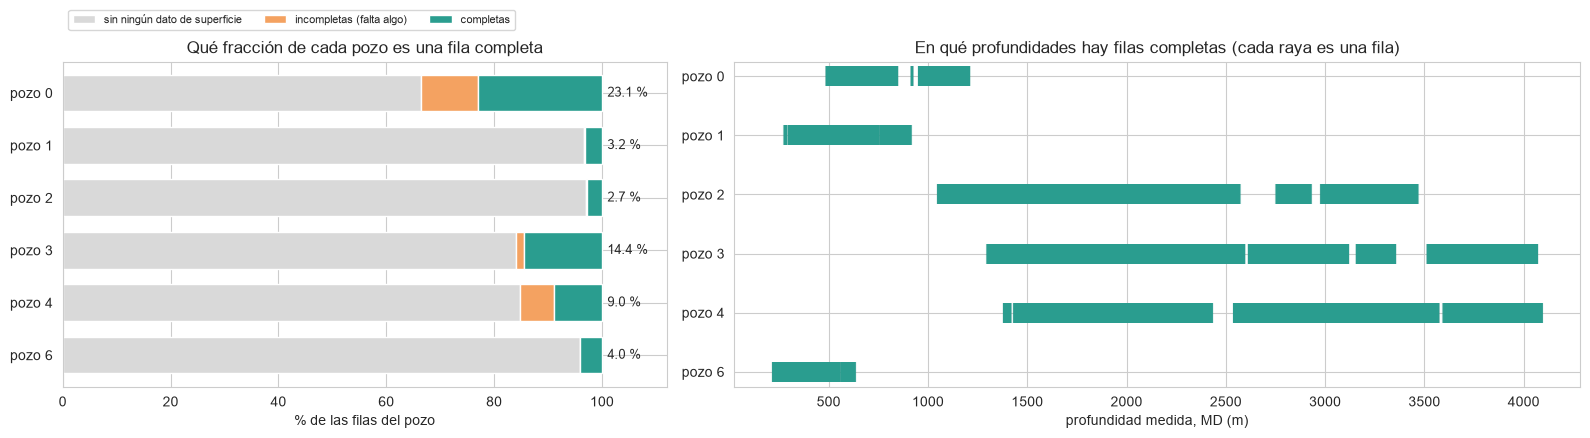

,completas,incompletas (falta algo),sin ningún dato de superficie
pozo 0,3845,1758,11067
pozo 1,602,36,18380
pozo 2,2159,235,77907
pozo 3,16276,1774,94664
pozo 4,11175,7749,105712
pozo 6,400,14,9586


In [25]:
resumen_filas = {}
for k, d in prep_todos.items():
    x, _ = invalidar_imposibles(d)
    alguna = x[grupo_superficie].notna().any(axis=1)
    completa = filas_completas(x)
    resumen_filas[nombre_pozo[k]] = {'completas': int(completa.sum()),
                                                      'incompletas (falta algo)': int((alguna & ~completa).sum()),
                                                      'sin ningún dato de superficie': int((~alguna).sum())}
resumen_filas = pd.DataFrame(resumen_filas).T
porcentaje = resumen_filas.div(resumen_filas.sum(axis=1), axis=0) * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={'width_ratios': [1, 1.4]})
izq = porcentaje[['sin ningún dato de superficie', 'incompletas (falta algo)', 'completas']]
izq.plot(kind='barh', stacked=True, ax=ax1, color=['#d9d9d9', '#f4a261', '#2a9d8f'], width=0.7)
ax1.invert_yaxis()
ax1.set_xlabel('% de las filas del pozo')
ax1.set_title('Qué fracción de cada pozo es una fila completa')
ax1.legend(fontsize=8, loc='lower left', bbox_to_anchor=(0, 1.08), ncol=3)
for pos, (_, f) in enumerate(porcentaje.iterrows()):
    ax1.text(101, pos, f"{f['completas']:.1f} %", va='center', fontsize=9)
ax1.set_xlim(0, 112)

for pos, (k, d) in enumerate(prep_todos.items()):
    x, _ = invalidar_imposibles(d)
    prof = x.loc[filas_completas(x), 'Measured Depth m']
    ax2.scatter(prof, np.full(len(prof), pos), marker='|', s=200, color='#2a9d8f', alpha=0.5)
ax2.set_yticks(range(len(prep_todos)))
ax2.set_yticklabels([nombre_pozo[k] for k in prep_todos])
ax2.invert_yaxis()
ax2.set_xlabel('profundidad medida, MD (m)')
ax2.set_title('En qué profundidades hay filas completas (cada raya es una fila)')
plt.tight_layout()
plt.show()
resumen_filas

<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Qué se ve en 2.4.1:** 

- **Izquierda:** la fila completa es una **fracción chica** de cada pozo: va de 2,7 % (pozo 2) a 23,1 % (pozo 0). El resto son filas sin ningún dato de superficie (gris) o incompletas (naranja). El pozo 4 tiene muchas incompletas (7.749 filas): en una parte del pozo no reportan el WOB, el hookload ni el torque (ver 7.4).
- **Derecha:** las filas completas **no están repartidas parejo** en profundidad. Los pozos 1 y 6 tienen un tramo continuo y el pozo 0 uno con un hueco de 75 m (el cambio de tramo); el pozo 2 tiene dos huecos (entre ~2.570 y 2.750 m, y entre ~2.930 y 2.970 m); el pozo 4 tiene dos bloques (de ~1.390 a 2.440 m y de ~2.540 a 4.090 m); el pozo 3 cubre de ~1.300 a 4.065 m, con un hueco de unos 167 m entre 3.350 y 3.520 m.
- **El pozo 3 casi quedaba cortado a la mitad:** con la columna principal de RPM, sus filas completas terminaban en ~2.600 m, aunque el pozo llega a 4.065 m. Con el canal equivalente de RPM (2.1.1) cubre todo el pozo.
- **El techo de presión importa en la parte media del pozo 3:** con un techo de 25.000 kPa, entre 2.000 y 2.500 m habría solo 209 filas completas; con el nuestro (51.700 kPa) hay 3.266.

</div>

#### 2.4.2 Variables que el perforador fija y variables que responden

En los gráficos de dispersión vimos que la RPM y el caudal se agrupan en **valores fijos**. Eso no es casualidad ni un problema de los datos: es cómo se perfora. Las revisiones sobre predicción de ROP separan las variables en dos grupos ([Springer, 2026](https://link.springer.com/article/10.1007/s13202-026-02189-7); [ScienceDirect, 2021](https://www.sciencedirect.com/science/article/abs/pii/S0920410521016442)):

| Grupo | Variables | Qué significa |
|---|---|---|
| **Palancas** (parámetros controlables) | `Weight on Bit`, `Rotary Speed`, `Mud Flow` | El perforador (o el piloto automático del equipo) las **elige y las mantiene** durante tramos, y las cambia a propósito |
| **Respuestas** | `ROP`, `Torque`, `Standpipe Pressure`, `Hookload` | **Resultan** de lo que pasa: la roca, la profundidad, la mecha y también las palancas |

Si esto es así, en los datos tendríamos que ver que las palancas **se quedan quietas por tramos** y las respuestas **se mueven más**. Lo comprobamos: para cada variable, qué porcentaje de las filas consecutivas (ordenadas por profundidad) casi no cambia el valor (menos de 1 %).

In [26]:
palancas = ['Weight on Bit kkgf', 'Average Rotary Speed rpm', 'Mud Flow In L/min']
respuestas = ['Rate of Penetration m/h', 'Average Surface Torque kN.m', 'Average Standpipe Pressure kPa', 'Average Hookload kkgf']

def pct_sin_cambio(s, umbral=0.01):
    """% de filas consecutivas en las que la variable cambia menos de 1 %."""
    cambio = (s.diff().abs() / s.abs().replace(0, np.nan)).dropna()
    return 100 * (cambio < umbral).mean()

finales = {k: armar_dataset(invalidar_imposibles(d)[0]) for k, d in prep_todos.items()}
quietud = pd.DataFrame({f'pozo {k}': {v: pct_sin_cambio(f[v]) for v in palancas + respuestas} for k, f in finales.items()}).round(0)
quietud['promedio'] = quietud.mean(axis=1).round(0)
quietud.insert(0, 'tipo', ['palanca'] * len(palancas) + ['respuesta'] * len(respuestas))
quietud.sort_values('promedio', ascending=False)

,tipo,pozo 0,pozo 1,pozo 2,pozo 3,pozo 4,pozo 6,promedio
Mud Flow In L/min,palanca,99.0,91.0,90.0,94.0,94.0,79.0,91.0
Average Hookload kkgf,respuesta,94.0,95.0,94.0,97.0,94.0,72.0,91.0
Average Rotary Speed rpm,palanca,98.0,88.0,94.0,94.0,90.0,76.0,90.0
Average Standpipe Pressure kPa,respuesta,82.0,72.0,86.0,93.0,84.0,59.0,79.0
Rate of Penetration m/h,respuesta,56.0,17.0,18.0,74.0,63.0,11.0,40.0
Average Surface Torque kN.m,respuesta,21.0,13.0,18.0,20.0,25.0,12.0,18.0
Weight on Bit kkgf,palanca,27.0,16.0,16.0,17.0,19.0,5.0,17.0


Y lo mismo a la vista, en el pozo 1: a la izquierda las **palancas**, a la derecha las **respuestas** que les corresponden, contra la profundidad.

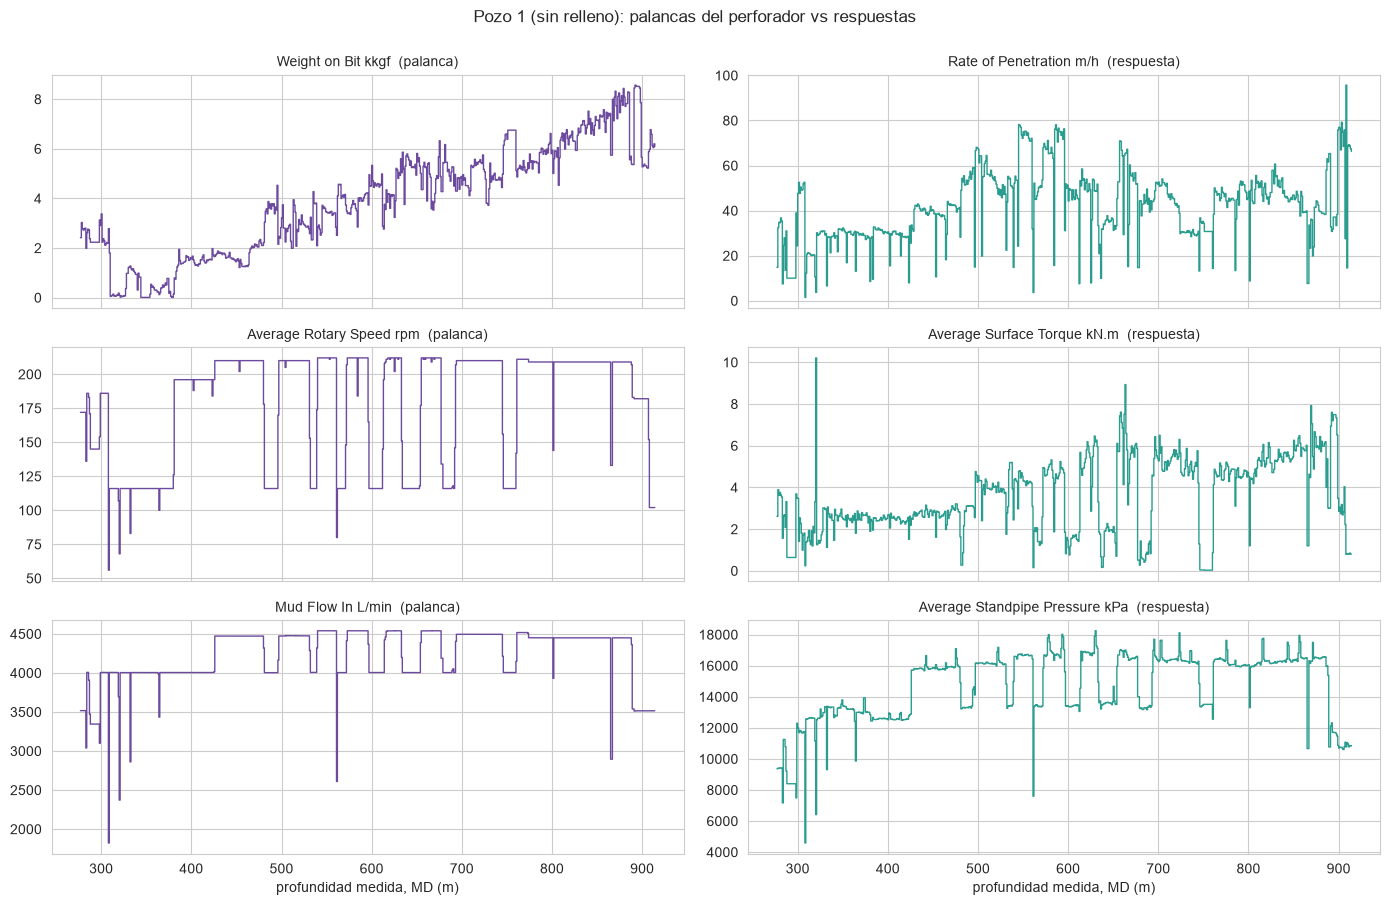

In [27]:
d1 = finales[1]
pares = [('Weight on Bit kkgf', 'Rate of Penetration m/h'), ('Average Rotary Speed rpm', 'Average Surface Torque kN.m'),
         ('Mud Flow In L/min', 'Average Standpipe Pressure kPa')]

fig, axes = plt.subplots(3, 2, figsize=(14, 9), sharex=True)
for fila, (pal, resp) in enumerate(pares):
    axes[fila, 0].plot(d1['Measured Depth m'], d1[pal], drawstyle='steps-post', color='#6c4a9e', linewidth=1)
    axes[fila, 0].set_title(f'{pal}  (palanca)', fontsize=10)
    axes[fila, 1].plot(d1['Measured Depth m'], d1[resp], drawstyle='steps-post', color='#2a9d8f', linewidth=1)
    axes[fila, 1].set_title(f'{resp}  (respuesta)', fontsize=10)
for ax in axes[-1]:
    ax.set_xlabel('profundidad medida, MD (m)')
plt.suptitle('Pozo 1 (sin relleno): palancas del perforador vs respuestas', y=1.0)
plt.tight_layout()
plt.show()

<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Qué se ve en 2.4.2:** 

- **La tabla confirma la idea:** la **RPM** y el **caudal** son las variables más "quietas": en promedio, alrededor del **90 %** de las filas consecutivas casi no cambia (menos de 1 %). Se mantienen en un valor durante tramos y cambian a propósito. En los gráficos se ven como escalones.
- **El Hookload (91 %) y la presión (79 %) también cambian poco, pero por otra razón:** el Hookload es el peso de la sarta colgada y crece despacio con la profundidad; la presión acompaña al caudal. Son respuestas lentas, no valores elegidos.
- **El torque (18 %) y el ROP (40 %) se mueven mucho**: reaccionan a cada tipo de roca. El ROP varía según el pozo (de 11 % a 74 %).
- **Un detalle del gráfico:** los tramos planos que unen dos zonas (por ejemplo, entre 209 y 277 m) son **huecos sin mediciones**, no valores medidos: el gráfico simplemente mantiene el último valor hasta el siguiente.
- **El WOB es una palanca, pero se mueve mucho (17 %):** el perforador la ajusta todo el tiempo y el sensor la registra con variaciones. No es un escalón limpio como la RPM y el caudal.

**Qué implica para los outliers (y para tu pregunta):**

- Un valor **fijo no es un outlier**: que la RPM valga 212 en la mitad de las filas es el perforador manteniendo su valor. Por eso en el pozo 6 la RPM y el caudal dan **cero outliers** por IQR: sus dos o tres niveles (por ejemplo, RPM de 143 y 212) son regímenes de operación, no errores.
- **Los outliers aparecen cuando el valor se sale de los escalones.** Ejemplo del pozo 1 (2.5.3): 8 filas con caudal de 1.822 a 3.100 L/min, bastante por debajo del escalón habitual de ~4.000 a 4.500. Es lo esperable de una bomba reducida (por ejemplo, durante una conexión de tubería): son **eventos reales** y no los eliminamos.
- Cuando casi todo está en un solo valor, el IQR se vuelve muy sensible (le pasaba a la densidad del lodo en el pozo 1): marca como outlier cualquier valor distinto, aunque sea legítimo.

</div>

### 2.5 Herramientas de análisis (las mismas para todos los pozos)

Antes de limpiar cada pozo definimos seis **herramientas** (funciones) que se usan igual en todos. Las dos celdas de abajo solo las **definen**, por eso no muestran resultados: se ven funcionando en 2.5.1 (ejemplo con el pozo 1) y en los pasos 5 a 7 de cada pozo. Estas funciones repiten lo que hicimos en el Notebook 1 (secciones 10.2, 10.6 y 10.9).

| Función | Qué hace |
|---|---|
| `ficha_columnas` | Tipo, valores distintos, nulos, ceros, negativos, mínimo y máximo de cada columna |
| `chequeos_generales` | Duplicados, infinitos, orden de la profundidad y saltos entre filas consecutivas |
| `rangos_fisicos` | Cuántas filas cumplen cada regla física (las de la sección 2.3) |
| `reparto_profundidad` | Cuántas filas y qué ROP promedio hay en cada tramo de 100 m |
| `tabla_outliers` | Outliers por IQR y por z-score, y de qué lado caen |
| `corr_simple_parcial` | Correlación simple con el ROP, y parcial (sacando el efecto de la profundidad) |

In [28]:
def ficha_columnas(df):
    return pd.DataFrame({'tipo': df.dtypes.astype(str), 'valores distintos': df.nunique(), 'nulos': df.isna().sum(),
                         'ceros': (df == 0).sum(), 'negativos': (df < 0).sum(),
                         'mínimo': df.min().round(3), 'máximo': df.max().round(3)})

def chequeos_generales(df):
    exceso = df['Hole Depth (TVD) m'] - df['Measured Depth m']
    paso = df['Measured Depth m'].diff().dropna()
    print('Filas:', len(df), '| Columnas:', df.shape[1])
    print('Filas duplicadas:', df.duplicated().sum(), '| Valores infinitos:', int(np.isinf(df).sum().sum()))
    print('Profundidad medida (MD) creciente:', df['Measured Depth m'].is_monotonic_increasing)
    print('Filas con TVD mayor que MD:', int((exceso > 0).sum()), '| mayor diferencia (m):', round(exceso.max(), 3))
    print('Paso entre filas consecutivas (m): mediana', round(paso.median(), 3), '| máximo', round(paso.max(), 3))
    saltos = paso[paso > 5]
    print('Saltos de más de 5 m:', len(saltos))
    for i in saltos.index:
        print(f'   salto de {saltos[i]:.1f} m: de {df.loc[i-1, "Measured Depth m"]:.1f} a {df.loc[i, "Measured Depth m"]:.1f} m')

def rangos_fisicos(df):
    reglas = {
        'Weight on Bit entre 0 y 35':   df['Weight on Bit kkgf'].between(0, 35),
        'Torque >= 0':                  df['Average Surface Torque kN.m'] >= 0,
        'Presión entre 0 y 51.700':     df['Average Standpipe Pressure kPa'].between(0, 51700),
        'Caudal >= 0':                  df['Mud Flow In L/min'] >= 0,
        'ROP entre 0 y 100':            df['Rate of Penetration m/h'].between(0, 100),
        'RPM >= 0':                     df['Average Rotary Speed rpm'] >= 0,
        'Hookload > 0':                 df['Average Hookload kkgf'] > 0,
    }
    return pd.DataFrame({'filas que cumplen': {k: int(v.sum()) for k, v in reglas.items()}, 'de un total de': len(df)})

def reparto_profundidad(df, paso=100):
    inicio = int(df['Measured Depth m'].min() // paso * paso)
    fin = int(df['Measured Depth m'].max() // paso * paso + paso)
    tramos = pd.cut(df['Measured Depth m'], bins=range(inicio, fin + paso, paso))
    g = df.groupby(tramos, observed=True)
    return pd.DataFrame({'filas': g.size(), 'ROP promedio (m/h)': g['Rate of Penetration m/h'].mean().round(1)})

In [29]:
def tabla_outliers(df, columnas):
    """Outliers por IQR (1,5 x IQR) y por z-score (>3), y de qué lado caen los del IQR."""
    filas = []
    for col in columnas:
        s = df[col]
        q1, q3 = s.quantile(0.25), s.quantile(0.75)
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_bajo, n_alto = int((s < lo).sum()), int((s > hi).sum())
        z = int((np.abs(stats.zscore(s)) > 3).sum()) if s.std() > 0 else 0
        filas.append({'variable': col, 'por debajo (IQR)': n_bajo, 'por encima (IQR)': n_alto,
                      '% IQR': round(100 * (n_bajo + n_alto) / len(s), 1), 'outliers (z>3)': z})
    return pd.DataFrame(filas).set_index('variable')

def boxplots(df, columnas, titulo):
    fig, axes = plt.subplots(2, 4, figsize=(16, 7))
    for ax, col in zip(axes.flatten(), columnas):
        sns.boxplot(y=df[col], ax=ax)
        ax.set_title(col, fontsize=10)
    for ax in axes.flatten()[len(columnas):]:
        ax.axis('off')
    fig.suptitle(titulo)
    plt.tight_layout()
    plt.show()

def sin_efecto_profundidad(y, z):
    """Resta la curva (polinomio de grado 3) que explica la profundidad; lo que sobra es lo que la profundidad no explica."""
    A = np.column_stack([np.ones(len(z)), z, z ** 2, z ** 3])
    return y - A @ np.linalg.lstsq(A, y, rcond=None)[0]

def corr_simple_parcial(df):
    z = df['Hole Depth (TVD) m'].values
    rop_sin = sin_efecto_profundidad(df[objetivo].values, z)
    return pd.DataFrame({
        'Simple': {v: df[v].corr(df[objetivo]) for v in nucleo},
        'Parcial (sin profundidad)': {v: np.corrcoef(sin_efecto_profundidad(df[v].values, z), rop_sin)[0, 1] for v in nucleo},
        'Simple con la profundidad': {v: df[v].corr(df['Measured Depth m']) for v in nucleo},
    }).round(2).sort_values('Parcial (sin profundidad)', ascending=False)

#### 2.5.1 Las herramientas en acción: ejemplo con el pozo 1

Usamos dos de las herramientas sobre el pozo 1 ya limpio (602 filas) para ver qué devuelve cada una. Primero `ficha_columnas`: una fila por columna.

In [30]:
d1 = armar_dataset(invalidar_imposibles(preparar_pozo(cargar_pozo(1)))[0])     # pozo 1, sin relleno (602 filas)
ficha_columnas(d1)

,tipo,valores distintos,nulos,ceros,negativos,mínimo,máximo
Measured Depth m,float64,602,0,0,0,276.999,914.001
Weight on Bit kkgf,float64,403,0,0,0,0.010,8.566
Average Standpipe Pressure kPa,float64,537,0,0,0,4589.000,18250.999
Average Surface Torque kN.m,float64,365,0,0,0,0.030,10.210
Rate of Penetration m/h,float64,553,0,0,0,1.480,95.700
Average Rotary Speed rpm,float64,45,0,0,0,56.000,212.000
Mud Flow In L/min,float64,366,0,0,0,1822.450,4540.850
Diameter mm,float64,1,0,0,0,444.500,444.500
Average Hookload kkgf,float64,364,0,0,0,96.822,106.734
Hole Depth (TVD) m,float64,602,0,0,0,276.998,910.331


Y `tabla_outliers`: cuántas filas de cada variable quedan fuera de los límites del IQR (se explica en 2.5.3) y de qué lado.

In [31]:
tabla_outliers(d1, nucleo + [objetivo])

,por debajo (IQR),por encima (IQR),% IQR,outliers (z>3)
variable,,,,
Weight on Bit kkgf,0,0,0.0,0
Average Surface Torque kN.m,0,2,0.3,2
Average Rotary Speed rpm,0,0,0.0,0
Average Standpipe Pressure kPa,6,0,1.0,6
Average Hookload kkgf,0,0,0.0,0
Mud Flow In L/min,7,0,1.2,7
Rate of Penetration m/h,0,1,0.2,1


#### 2.5.2 Verlo en los datos: cómo funciona la correlación parcial

La correlación parcial (`corr_simple_parcial`) es la herramienta menos intuitiva. La mostramos paso a paso con un ejemplo: el **Hookload** y el **ROP** del pozo 1.

1. **(a)** La correlación simple entre las dos variables.
2. **(b) y (c)** Las dos cambian con la profundidad; ajustamos una curva (polinomio de grado 3) a cada una.
3. **(d)** Restamos esas curvas y correlacionamos **lo que sobra**: es la correlación parcial.

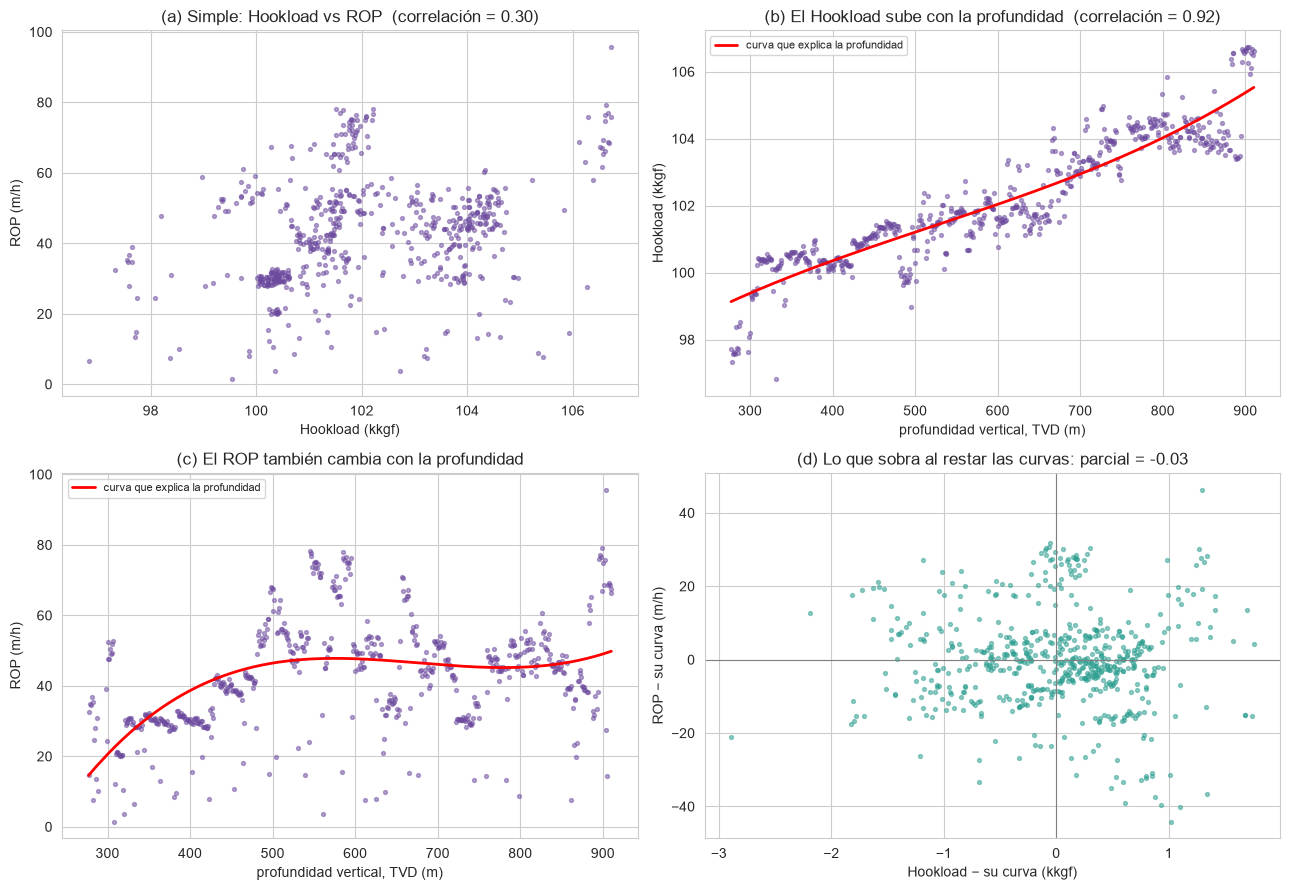

In [32]:
z = d1['Hole Depth (TVD) m'].values
hook, rop = d1['Average Hookload kkgf'].values, d1[objetivo].values

def curva_profundidad(y, z):
    A = np.column_stack([np.ones(len(z)), z, z ** 2, z ** 3])
    return A @ np.linalg.lstsq(A, y, rcond=None)[0]

curva_hook, curva_rop = curva_profundidad(hook, z), curva_profundidad(rop, z)
resto_hook, resto_rop = hook - curva_hook, rop - curva_rop
orden = np.argsort(z)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
axes[0, 0].scatter(hook, rop, s=8, alpha=0.5, color='#6c4a9e')
axes[0, 0].set_title(f'(a) Simple: Hookload vs ROP  (correlación = {np.corrcoef(hook, rop)[0, 1]:.2f})')
axes[0, 0].set_xlabel('Hookload (kkgf)'); axes[0, 0].set_ylabel('ROP (m/h)')

axes[0, 1].scatter(z, hook, s=8, alpha=0.5, color='#6c4a9e')
axes[0, 1].plot(z[orden], curva_hook[orden], color='red', linewidth=2, label='curva que explica la profundidad')
axes[0, 1].set_title(f'(b) El Hookload sube con la profundidad  (correlación = {np.corrcoef(hook, z)[0, 1]:.2f})')
axes[0, 1].set_xlabel('profundidad vertical, TVD (m)'); axes[0, 1].set_ylabel('Hookload (kkgf)'); axes[0, 1].legend(fontsize=8)

axes[1, 0].scatter(z, rop, s=8, alpha=0.5, color='#6c4a9e')
axes[1, 0].plot(z[orden], curva_rop[orden], color='red', linewidth=2, label='curva que explica la profundidad')
axes[1, 0].set_title('(c) El ROP también cambia con la profundidad')
axes[1, 0].set_xlabel('profundidad vertical, TVD (m)'); axes[1, 0].set_ylabel('ROP (m/h)'); axes[1, 0].legend(fontsize=8)

axes[1, 1].scatter(resto_hook, resto_rop, s=8, alpha=0.5, color='#2a9d8f')
axes[1, 1].axhline(0, color='grey', linewidth=0.8); axes[1, 1].axvline(0, color='grey', linewidth=0.8)
axes[1, 1].set_title(f'(d) Lo que sobra al restar las curvas: parcial = {np.corrcoef(resto_hook, resto_rop)[0, 1]:.2f}')
axes[1, 1].set_xlabel('Hookload − su curva (kkgf)'); axes[1, 1].set_ylabel('ROP − su curva (m/h)')
plt.tight_layout()
plt.show()

<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Cómo se lee:** 

- **(a)** Hookload y ROP tienen correlación simple de **0,30**: parece una relación moderada.
- **(b)** Pero el Hookload **sube con la profundidad casi en línea recta** (correlación de 0,92 con ella). La curva roja es todo lo que la profundidad "explica" del Hookload.
- **(c)** El ROP también cambia con la profundidad (sube hasta ~500 m y después se mantiene): otra curva.
- **(d)** Si a cada punto le restamos su curva y correlacionamos lo que sobra, la correlación **cae a −0,03**: sin el efecto de la profundidad no queda ninguna relación. Es decir, el 0,30 del gráfico (a) venía solo de que las dos variables cambian con la profundidad.
- El mismo procedimiento, aplicado a las demás variables, es lo que hace `corr_simple_parcial`: las que **mantienen** su correlación (como el torque) tienen una relación propia con el ROP; las que **la pierden** (como el Hookload) solo seguían a la profundidad.

</div>

#### 2.5.3 Verlo en los datos: cómo detecta outliers el IQR

La función `tabla_outliers` usa el **rango intercuartílico**. Lo mostramos sobre el caudal de lodo del pozo 1: la caja va de Q1 a Q3 (el 50 % central de los datos), y los límites están a 1,5 veces esa caja de cada lado. Lo que cae afuera es un outlier.

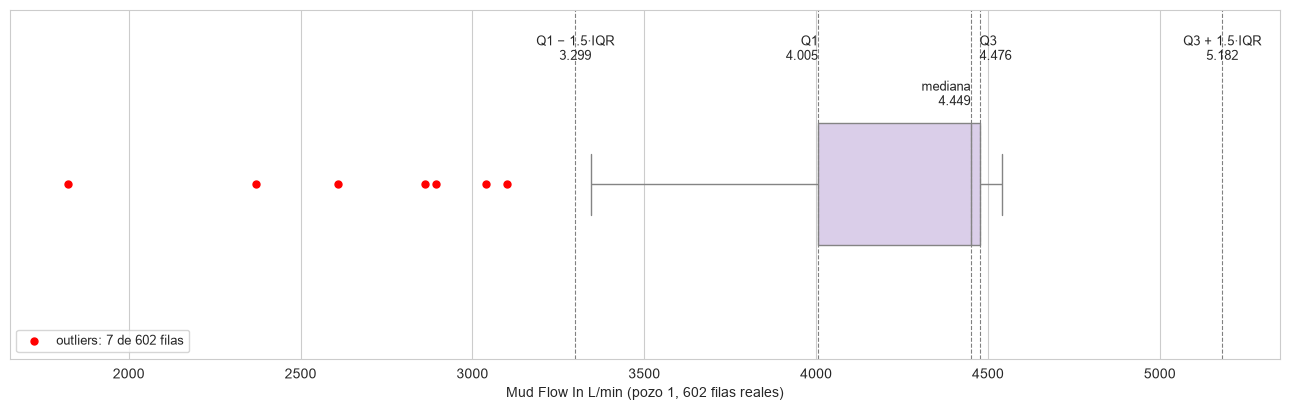

IQR = Q3 − Q1 = 471 L/min  ->  límites: 3.299 y 5.182


In [33]:
s = d1['Mud Flow In L/min']
q1, med, q3 = s.quantile(0.25), s.median(), s.quantile(0.75)
iqr = q3 - q1
lim_bajo, lim_alto = q1 - 1.5 * iqr, q3 + 1.5 * iqr
afuera = s[(s < lim_bajo) | (s > lim_alto)]

fig, ax = plt.subplots(figsize=(13, 4.2))
sns.boxplot(x=s, ax=ax, color='#d9c9ee', fliersize=0, whis=1.5, width=0.35)
ax.scatter(afuera, np.zeros(len(afuera)), color='red', s=25, zorder=3, label=f'outliers: {len(afuera)} de {len(s)} filas')
fraccion_y = ax.get_xaxis_transform()          # x en datos, y como fracción de la altura del gráfico
etiquetas = [(lim_bajo, 'Q1 − 1,5·IQR', 0.93, 'center'), (q1, 'Q1', 0.93, 'right'), (med, 'mediana', 0.80, 'right'),
             (q3, 'Q3', 0.93, 'left'), (lim_alto, 'Q3 + 1,5·IQR', 0.93, 'center')]
for valor, etiqueta, y, alineacion in etiquetas:
    ax.axvline(valor, color='grey', linestyle='--', linewidth=0.8)
    ax.text(valor, y, f'{etiqueta}\n{valor:,.0f}'.replace(',', '.'), transform=fraccion_y, ha=alineacion, va='top', fontsize=9)
ax.set_ylim(-0.5, 0.5)
ax.set_xlabel('Mud Flow In L/min (pozo 1, 602 filas reales)')
ax.set_yticks([])
ax.legend(loc='lower left', fontsize=9)
plt.tight_layout()
plt.show()
print(f'IQR = Q3 − Q1 = {iqr:,.0f} L/min  ->  límites: {lim_bajo:,.0f} y {lim_alto:,.0f}'.replace(',', '.'))

<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Cómo se lee:** 

- La **caja** (violeta) va de Q1 = 4.005 a Q3 = 4.476 L/min: ahí está el 50 % central de las filas. Su ancho es el IQR (471 L/min).
- Los **límites** están a 1,5 veces el IQR de cada lado: 3.299 por abajo y 5.182 por arriba.
- Los **7 puntos rojos** caen por debajo de 3.299: son los outliers (7 de 602 filas). Por arriba no hay ninguno.
- Como el IQR se calcula con cuartiles, **no lo distorsionan los propios outliers** ni exige que los datos tengan forma de campana; por eso lo usamos como criterio principal y dejamos el z-score como comparación.

</div>

<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Conclusión Parte 2:** quedan definidas **tres reglas de limpieza** (sacar los tramos de 26 pulgadas o más, ordenar por tramo y profundidad, y pasar a `NaN` los valores imposibles y el ROP de las lecturas sin perforar), una definición de **fila completa** (6 sensores + ROP + TVD a la vez) y un set de **herramientas de análisis** iguales para todos los pozos. Hay además un **canal equivalente de RPM** (2.1.1), que evita perder toda la parte profunda del pozo 3. Con esto, cada pozo se limpia sin rellenar nada, y cualquier diferencia entre pozos que veamos viene de los datos, no de haber aplicado criterios distintos. Los límites tienen base física (pisos, WOB por coherencia con el hookload, presión por el máximo de las bombas), salvo el ROP, que es un criterio práctico. Los fundamentos están en 2.3.

</div>

<div style="background-color:#1f5fa8; color:#ffffff; padding:26px 32px; border-radius:8px; margin:40px 0 10px 0;"><div style="font-size:42px; font-weight:bold; line-height:1.1; color:#ffffff;">POZO 6</div><div style="font-size:17px; margin-top:6px; color:#dbe9f8;">Parte 3</div></div>

## Parte 3. Pozo 6

Seguimos la plantilla de la intro: los mismos 9 pasos que en el resto de los pozos.

### 3.1 El archivo y sus tramos

In [34]:
crudo_6 = cargar_pozo(6)
print('Filas:', len(crudo_6), '| Columnas leídas:', crudo_6.shape[1])
print('Profundidad medida (MD):', crudo_6['Measured Depth m'].min(), 'a', crudo_6['Measured Depth m'].max(), 'm')
print()
tramos_6 = crudo_6.groupby('pulgadas').agg(filas=('pulgadas', 'size'), MD_mín=('Measured Depth m', 'min'), MD_máx=('Measured Depth m', 'max'))
tramos_6.index.name = 'diámetro (pulgadas)'
tramos_6.round(1)

Filas: 13830 | Columnas leídas: 14
Profundidad medida (MD): 0.0 a 633.536 m



,filas,MD_mín,MD_máx
diámetro (pulgadas),,,
17.5,10000,0.0,633.5
36.0,3830,0.0,226.1


### 3.2 Qué hay realmente medido

Medimos qué porcentaje de las filas tiene dato real en cada variable, y si los sensores del núcleo reportan juntos (como en el pozo 1).

In [35]:
presencia_6 = (100 * crudo_6[grupo_superficie + [densidad]].notna().mean()).round(1)
presencia_6['Gamma Ray (alguna columna)'] = round(100 * crudo_6['Gamma medido'].mean(), 1)
presencia_6.name = '% de filas con dato real'
display(presencia_6)

alguna = crudo_6[grupo_superficie].notna().any(axis=1)
todas = crudo_6[grupo_superficie].notna().all(axis=1)
print('Filas con alguna variable del grupo de superficie:', alguna.sum(), '| con las 7 a la vez:', todas.sum(),
      '| % que reporta junto:', round(100 * todas.sum() / alguna.sum(), 1))

# correlación entre los INDICADORES de nulo (1 = siempre faltan juntos, 0 = independientes)
wob_nulo = crudo_6['Weight on Bit kkgf'].isna().astype(int)
print('WOB nulo vs Torque nulo:', round(wob_nulo.corr(crudo_6['Average Surface Torque kN.m'].isna().astype(int)), 3))
print('WOB nulo vs Gamma nulo :', round(wob_nulo.corr((~crudo_6['Gamma medido']).astype(int)), 3))

Weight on Bit kkgf                 3.6
Average Surface Torque kN.m        3.6
Average Rotary Speed rpm           7.5
Average Standpipe Pressure kPa     3.6
Average Hookload kkgf              3.6
Mud Flow In L/min                  3.6
Rate of Penetration m/h            3.6
Mud Density In g/cm3               3.6
Gamma Ray (alguna columna)        15.2
Name: % de filas con dato real, dtype: float64

Filas con alguna variable del grupo de superficie: 1044 | con las 7 a la vez: 496 | % que reporta junto: 47.5
WOB nulo vs Torque nulo: 1.0
WOB nulo vs Gamma nulo : -0.072


### 3.3 Limpieza (sin relleno)

Aplicamos las tres reglas de la Parte 2, **una por una**, para ver qué hace cada una.

#### 3.3.1 Regla 1: sacar los tramos de 26 pulgadas o más

In [36]:
prep_6 = preparar_pozo(crudo_6)
print('Filas antes:', len(crudo_6), '| después de sacar los tramos grandes:', len(prep_6),
      '| filas sacadas:', len(crudo_6) - len(prep_6))
print('Tramos que quedan (pulgadas):', sorted(prep_6['pulgadas'].unique(), reverse=True))

Filas antes: 13830 | después de sacar los tramos grandes: 10000 | filas sacadas: 3830
Tramos que quedan (pulgadas): [np.float64(17.5)]


#### 3.3.2 Regla 2: ordenar por tramo y profundidad

Verificamos que, dentro de cada tramo, la profundidad quedó creciente.

In [37]:
for p, g in prep_6.groupby('pulgadas', sort=False):
    print(f'Tramo de {p:g} pulgadas: {len(g)} filas | profundidad creciente dentro del tramo:', g['Measured Depth m'].is_monotonic_increasing)

Tramo de 17.5 pulgadas: 10000 filas | profundidad creciente dentro del tramo: True


#### 3.3.3 Regla 3: valores imposibles a `NaN`

In [38]:
inval_6, conteo_6 = invalidar_imposibles(prep_6)
display(conteo_6[conteo_6 > 0] if conteo_6.sum() else conteo_6)
print('Total de valores invalidados:', conteo_6.sum(), '| filas del pozo (no se borró ninguna):', len(inval_6))

Torque < 0    11
ROP > 100      3
Name: valores invalidados, dtype: int64

Total de valores invalidados: 14 | filas del pozo (no se borró ninguna): 10000


### 3.4 Nulos que quedan

Sin relleno, el grupo de superficie tiene filas completas e incompletas. Vemos cuántas hay de cada una y qué falta en las incompletas.

In [39]:
alguna = inval_6[grupo_superficie].notna().any(axis=1)
completas = filas_completas(inval_6)
incompletas = alguna & ~inval_6[grupo_superficie].notna().all(axis=1)

print('Filas donde el grupo de superficie midió algo:', alguna.sum())
print('   completas (7 variables + TVD):', completas.sum())
print('   incompletas (falta alguna de las 7):', incompletas.sum())
if incompletas.sum():
    print()
    print('Qué variable falta en las filas incompletas:')
    print(inval_6.loc[incompletas, grupo_superficie].isna().sum()[lambda s: s > 0])
    print('Variables que faltan por fila incompleta:', inval_6.loc[incompletas, grupo_superficie].isna().sum(axis=1).value_counts().to_dict())

print()
print('De las filas completas, tienen densidad:', inval_6.loc[completas, densidad].notna().sum(),
      '| tienen Gamma:', int(inval_6.loc[completas, 'Gamma medido'].sum()), '| de', completas.sum())

Filas donde el grupo de superficie midió algo: 414
   completas (7 variables + TVD): 400
   incompletas (falta alguna de las 7): 14

Qué variable falta en las filas incompletas:
Average Surface Torque kN.m    11
Rate of Penetration m/h         3
dtype: int64
Variables que faltan por fila incompleta: {1: 14}

De las filas completas, tienen densidad: 400 | tienen Gamma: 7 | de 400


### 3.5 Dataset final del pozo 6

Armamos el dataset (solo filas completas, 10 columnas) y lo verificamos: forma, ceros, estadística, rangos físicos y reparto por profundidad.

In [40]:
final_6 = armar_dataset(inval_6)
print('Dataset final del pozo 6 (solo mediciones reales):', final_6.shape)
chequeos_generales(final_6)

Dataset final del pozo 6 (solo mediciones reales): (400, 10)
Filas: 400 | Columnas: 10
Filas duplicadas: 0 | Valores infinitos: 0
Profundidad medida (MD) creciente: True
Filas con TVD mayor que MD: 282 | mayor diferencia (m): 0.081
Paso entre filas consecutivas (m): mediana 1.0 | máximo 7.998
Saltos de más de 5 m: 1
   salto de 8.0 m: de 555.0 a 563.0 m


In [41]:
ficha_columnas(final_6)

,tipo,valores distintos,nulos,ceros,negativos,mínimo,máximo
Measured Depth m,float64,400,0,0,0,218.999,632.999
Weight on Bit kkgf,float64,300,0,0,0,0.010,10.024
Average Standpipe Pressure kPa,float64,365,0,0,0,8520.000,17753.999
Average Surface Torque kN.m,float64,240,0,0,0,0.310,7.220
Rate of Penetration m/h,float64,382,0,0,0,2.240,98.110
Average Rotary Speed rpm,float64,40,0,0,0,103.000,212.000
Mud Flow In L/min,float64,308,0,0,0,3305.000,4431.420
Diameter mm,float64,1,0,0,0,444.500,444.500
Average Hookload kkgf,float64,322,0,0,0,91.764,112.852
Hole Depth (TVD) m,float64,400,0,0,0,218.992,632.750


In [42]:
estadistica_6 = final_6.describe().T
estadistica_6['asimetría'] = final_6.skew()
estadistica_6.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetría
Measured Depth m,400.0,423.62,119.85,219.00,319.75,422.50,525.25,633.00,0.03
Weight on Bit kkgf,400.0,4.30,1.73,0.01,3.17,4.42,5.48,10.02,-0.08
Average Standpipe Pressure kPa,400.0,12586.49,2249.62,8520.00,10078.25,14058.00,14583.50,17754.00,-0.27
Average Surface Torque kN.m,400.0,3.81,1.08,0.31,3.37,3.90,4.49,7.22,-0.31
Rate of Penetration m/h,400.0,52.06,19.06,2.24,42.15,55.19,63.25,98.11,-0.51
Average Rotary Speed rpm,400.0,184.28,36.47,103.00,143.00,212.00,212.00,212.00,-1.00
Mud Flow In L/min,400.0,3999.00,470.54,3305.00,3435.00,4415.41,4426.77,4431.42,-0.28
Diameter mm,400.0,444.50,0.00,444.50,444.50,444.50,444.50,444.50,0.00
Average Hookload kkgf,400.0,97.95,2.65,91.76,95.89,97.96,99.81,112.85,0.48
Hole Depth (TVD) m,400.0,423.60,119.82,218.99,319.76,422.51,525.28,632.75,0.03


In [43]:
display(rangos_fisicos(final_6))
reparto_profundidad(final_6)

,filas que cumplen,de un total de
Weight on Bit entre 0 y 35,400,400
Torque >= 0,400,400
Presión entre 0 y 51.700,400,400
Caudal >= 0,400,400
ROP entre 0 y 100,400,400
RPM >= 0,400,400
Hookload > 0,400,400


,filas,ROP promedio (m/h)
Measured Depth m,,
"(200, 300]",82,31.5
"(300, 400]",95,59.4
"(400, 500]",101,66.2
"(500, 600]",89,51.1
"(600, 700]",33,41.3


### 3.6 Outliers (sobre mediciones reales)

Con el criterio del IQR (más de 1,5 veces el rango intercuartílico por debajo de Q1 o por encima de Q3) y con z-score, solo sobre las filas reales.

In [44]:
variables_outliers = nucleo + [objetivo]
tabla_outliers(final_6, variables_outliers)

,por debajo (IQR),por encima (IQR),% IQR,outliers (z>3)
variable,,,,
Weight on Bit kkgf,0,2,0.5,1
Average Surface Torque kN.m,14,6,5.0,4
Average Rotary Speed rpm,0,0,0.0,0
Average Standpipe Pressure kPa,0,0,0.0,0
Average Hookload kkgf,0,1,0.2,1
Mud Flow In L/min,0,0,0.0,0
Rate of Penetration m/h,15,3,4.5,0


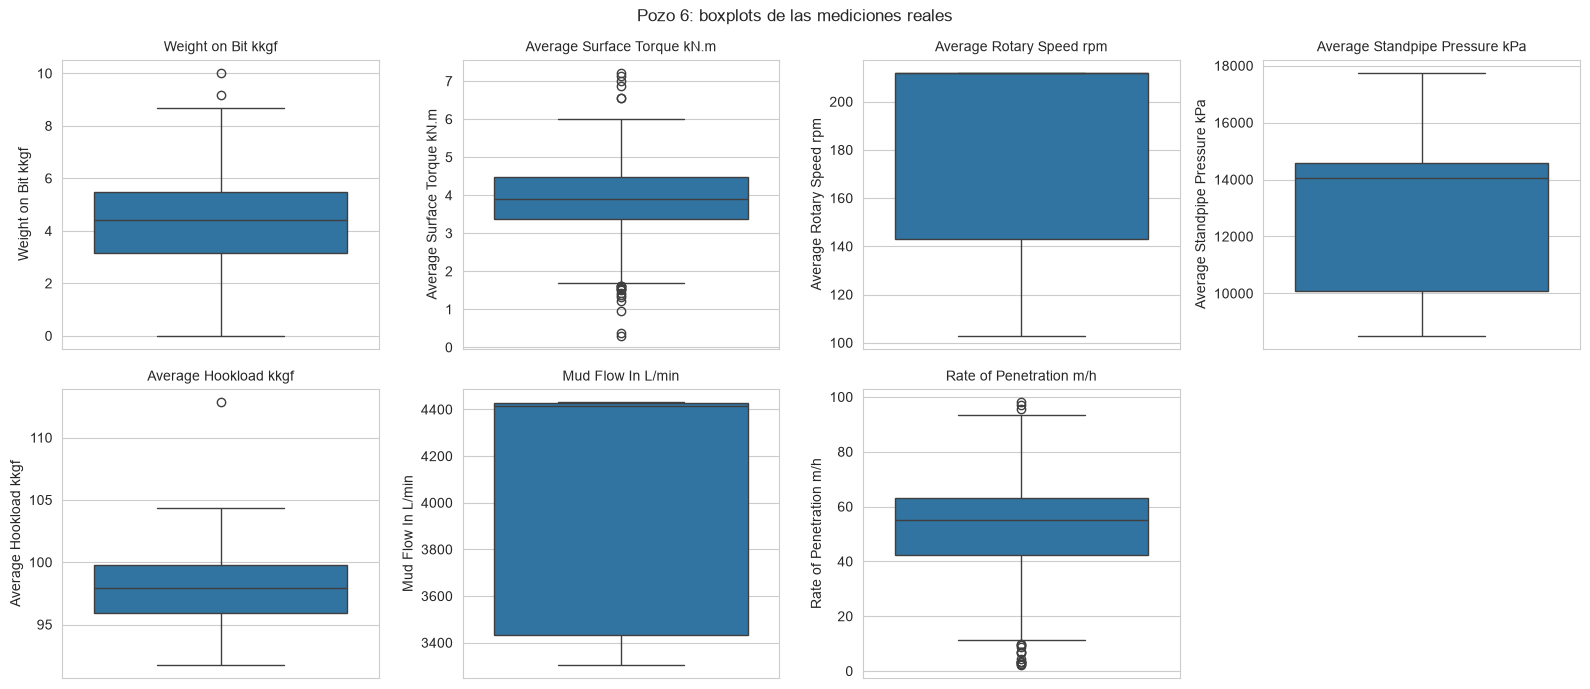

In [45]:
boxplots(final_6, variables_outliers, 'Pozo 6: boxplots de las mediciones reales')

### 3.7 Correlación con el ROP

La correlación **simple** mezcla el efecto de la profundidad; la **parcial** lo saca (ver sección 10.6.2 del Notebook 1). La tercera columna dice cuánto se pega cada variable a la profundidad.

In [46]:
corr_6 = corr_simple_parcial(final_6)
corr_6

,Simple,Parcial (sin profundidad),Simple con la profundidad
Average Surface Torque kN.m,0.30,0.25,0.25
Mud Flow In L/min,0.28,0.24,-0.53
Average Rotary Speed rpm,0.29,0.22,-0.64
Average Standpipe Pressure kPa,0.33,0.21,-0.41
Weight on Bit kkgf,0.27,0.10,0.53
Average Hookload kkgf,0.06,-0.05,0.77


### 3.8 Guardar

Se guarda con un nombre propio, con las 10 columnas en el orden oficial. **No se sobrescribe ningún archivo original.**

In [47]:
final_6.to_csv('USROP_A 6 sin relleno.csv', index=False)
print('Guardado: USROP_A 6 sin relleno.csv', final_6.shape, '| nulos:', final_6.isna().sum().sum())

Guardado: USROP_A 6 sin relleno.csv (400, 10) | nulos: 0


<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Conclusión Parte 3 (pozo 6):** resumen del pozo 6, paso por paso:

- **3.1 Archivo:** 13.830 filas y dos tramos: 36 pulgadas (3.830 filas, de 0 a 226 m) y 17,5 pulgadas (10.000 filas, de 0 a 634 m). Los dos se **solapan en profundidad**, por eso hay que ordenar por tramo.
- **3.2 Qué hay medido:** solo ~3,6 % de las filas tiene dato en cada sensor de superficie. WOB y torque faltan **juntos** en el 100 % de los casos (correlación 1,0): los sensores de superficie reportan todos a la vez, y cuando reportan lo hacen completos (las 496 filas con algún sensor tienen los 7).
- **3.3 Limpieza:** se sacó el tramo de 36 pulgadas (3.830 filas), el de 17,5 quedó ordenado y se invalidaron **14 valores**: 11 torques negativos y 3 ROP mayores a 100. No se borró ninguna fila.
- **3.4 Nulos que quedan:** de las 10.000 filas, el grupo de superficie midió algo en 414: **400 completas** y 14 incompletas. A cada incompleta le falta **exactamente un valor**, justo los 11 + 3 que invalidamos: no son datos que el sensor no mandó. Igual que en el pozo 1, se descartan (el ROP no se inventa). La densidad está en las 400 filas; el Gamma, solo en 7.
- **3.5 Dataset final:** **400 filas × 10 columnas, sin nulos, duplicados, ceros ni negativos**, y las 400 cumplen los rangos físicos. Cubre de 219 a 633 m, con paso típico de 1 m y un solo salto (8 m, entre los 555 y 563 m). El TVD supera al MD en 282 filas, pero por **8 cm como máximo**: ruido de medición normal en un pozo vertical. La RPM vale 212 en más de la mitad de las filas y el caudal se mueve en dos niveles (cerca de 3.400 y de 4.400 L/min): son parámetros que el perforador fija y mantiene (ver 2.4.2). El ROP promedia 52,1 m/h (mediana 55,2) y por tramo de 100 m va de 31,5 (200 a 300 m) a 66,2 (400 a 500 m), y baja a 41,3 (600 a 700 m, con solo 33 filas).
- **3.6 Outliers:** casi no hay. RPM, presión y caudal tienen cero. Los más altos son el torque (5,0 %: 14 por debajo y 6 por encima) y el ROP (4,5 %: 15 bajos y 3 altos, ninguno por z-score). No se elimina ninguno: los valores imposibles ya se sacaron en 3.3 y estos son valores posibles.
- **3.7 Correlación con el ROP:** la simple va de 0,06 (hookload) a 0,33 (presión). Sacando la profundidad: torque 0,25, caudal 0,24, RPM 0,22, presión 0,21, WOB 0,10 y hookload −0,05. Es el **mismo patrón que en el pozo 1**: el torque entre los más altos y el hookload en cero. Pero hay una diferencia: acá RPM, caudal y presión **bajan** con la profundidad (−0,64, −0,53 y −0,41), mientras que en el pozo 1 subían (+0,34, +0,30 y +0,44).
- **3.8 Guardado:** `USROP_A 6 sin relleno.csv`.

**En una frase:** el pozo 6 aporta **400 mediciones reales** (2,9 % de las filas del archivo crudo), con los mismos patrones que el pozo 1, y sin ningún nulo en el dataset final.

</div>

<div style="background-color:#1f5fa8; color:#ffffff; padding:26px 32px; border-radius:8px; margin:40px 0 10px 0;"><div style="font-size:42px; font-weight:bold; line-height:1.1; color:#ffffff;">POZO 0</div><div style="font-size:17px; margin-top:6px; color:#dbe9f8;">Parte 4</div></div>

## Parte 4. Pozo 0

Seguimos la plantilla de la intro: los mismos 9 pasos que en el resto de los pozos.

### 4.1 El archivo y sus tramos

In [48]:
crudo_0 = cargar_pozo(0)
print('Filas:', len(crudo_0), '| Columnas leídas:', crudo_0.shape[1])
print('Profundidad medida (MD):', crudo_0['Measured Depth m'].min(), 'a', crudo_0['Measured Depth m'].max(), 'm')
print()
tramos_0 = crudo_0.groupby('pulgadas').agg(filas=('pulgadas', 'size'), MD_mín=('Measured Depth m', 'min'), MD_máx=('Measured Depth m', 'max'))
tramos_0.index.name = 'diámetro (pulgadas)'
tramos_0.round(1)

Filas: 16670 | Columnas leídas: 14
Profundidad medida (MD): 273.101 a 1205.999 m



,filas,MD_mín,MD_máx
diámetro (pulgadas),,,
8.50,6670,880.0,1206.0
12.25,10000,273.1,848.0


### 4.2 Qué hay realmente medido

Medimos qué porcentaje de las filas tiene dato real en cada variable, y si los sensores del núcleo reportan juntos (como en el pozo 1).

In [49]:
presencia_0 = (100 * crudo_0[grupo_superficie + [densidad]].notna().mean()).round(1)
presencia_0['Gamma Ray (alguna columna)'] = round(100 * crudo_0['Gamma medido'].mean(), 1)
presencia_0.name = '% de filas con dato real'
display(presencia_0)

alguna = crudo_0[grupo_superficie].notna().any(axis=1)
todas = crudo_0[grupo_superficie].notna().all(axis=1)
print('Filas con alguna variable del grupo de superficie:', alguna.sum(), '| con las 7 a la vez:', todas.sum(),
      '| % que reporta junto:', round(100 * todas.sum() / alguna.sum(), 1))

# correlación entre los INDICADORES de nulo (1 = siempre faltan juntos, 0 = independientes)
wob_nulo = crudo_0['Weight on Bit kkgf'].isna().astype(int)
print('WOB nulo vs Torque nulo:', round(wob_nulo.corr(crudo_0['Average Surface Torque kN.m'].isna().astype(int)), 3))
print('WOB nulo vs Gamma nulo :', round(wob_nulo.corr((~crudo_0['Gamma medido']).astype(int)), 3))

Weight on Bit kkgf                33.6
Average Surface Torque kN.m       33.4
Average Rotary Speed rpm          33.6
Average Standpipe Pressure kPa    33.4
Average Hookload kkgf             33.6
Mud Flow In L/min                 33.4
Rate of Penetration m/h           33.4
Mud Density In g/cm3              14.0
Gamma Ray (alguna columna)        10.7
Name: % de filas con dato real, dtype: float64

Filas con alguna variable del grupo de superficie: 5603 | con las 7 a la vez: 5526 | % que reporta junto: 98.6
WOB nulo vs Torque nulo: 0.996
WOB nulo vs Gamma nulo : 0.486


### 4.3 Limpieza (sin relleno)

Aplicamos las tres reglas de la Parte 2, **una por una**, para ver qué hace cada una.

#### 4.3.1 Regla 1: sacar los tramos de 26 pulgadas o más

In [50]:
prep_0 = preparar_pozo(crudo_0)
print('Filas antes:', len(crudo_0), '| después de sacar los tramos grandes:', len(prep_0),
      '| filas sacadas:', len(crudo_0) - len(prep_0))
print('Tramos que quedan (pulgadas):', sorted(prep_0['pulgadas'].unique(), reverse=True))

Filas antes: 16670 | después de sacar los tramos grandes: 16670 | filas sacadas: 0
Tramos que quedan (pulgadas): [np.float64(12.25), np.float64(8.5)]


#### 4.3.2 Regla 2: ordenar por tramo y profundidad

Verificamos que, dentro de cada tramo, la profundidad quedó creciente.

In [51]:
for p, g in prep_0.groupby('pulgadas', sort=False):
    print(f'Tramo de {p:g} pulgadas: {len(g)} filas | profundidad creciente dentro del tramo:', g['Measured Depth m'].is_monotonic_increasing)

Tramo de 12.25 pulgadas: 10000 filas | profundidad creciente dentro del tramo: True
Tramo de 8.5 pulgadas: 6670 filas | profundidad creciente dentro del tramo: True


#### 4.3.3 Regla 3: valores imposibles a `NaN`

In [52]:
inval_0, conteo_0 = invalidar_imposibles(prep_0)
display(conteo_0[conteo_0 > 0] if conteo_0.sum() else conteo_0)
print('Total de valores invalidados:', conteo_0.sum(), '| filas del pozo (no se borró ninguna):', len(inval_0))

WOB < 0                                   1261
Torque < 0                                 223
ROP > 100                                 1182
ROP sin perforar (RPM<20 o caudal<500)      69
Name: valores invalidados, dtype: int64

Total de valores invalidados: 2735 | filas del pozo (no se borró ninguna): 16670


### 4.4 Nulos que quedan

Sin relleno, el grupo de superficie tiene filas completas e incompletas. Vemos cuántas hay de cada una y qué falta en las incompletas.

In [53]:
alguna = inval_0[grupo_superficie].notna().any(axis=1)
completas = filas_completas(inval_0)
incompletas = alguna & ~inval_0[grupo_superficie].notna().all(axis=1)

print('Filas donde el grupo de superficie midió algo:', alguna.sum())
print('   completas (7 variables + TVD):', completas.sum())
print('   incompletas (falta alguna de las 7):', incompletas.sum())
if incompletas.sum():
    print()
    print('Qué variable falta en las filas incompletas:')
    print(inval_0.loc[incompletas, grupo_superficie].isna().sum()[lambda s: s > 0])
    print('Variables que faltan por fila incompleta:', inval_0.loc[incompletas, grupo_superficie].isna().sum(axis=1).value_counts().to_dict())

print()
print('De las filas completas, tienen densidad:', inval_0.loc[completas, densidad].notna().sum(),
      '| tienen Gamma:', int(inval_0.loc[completas, 'Gamma medido'].sum()), '| de', completas.sum())

Filas donde el grupo de superficie midió algo: 5603
   completas (7 variables + TVD): 3845
   incompletas (falta alguna de las 7): 1758

Qué variable falta en las filas incompletas:
Weight on Bit kkgf                1261
Average Surface Torque kN.m        250
Average Standpipe Pressure kPa      27
Mud Flow In L/min                   43
Rate of Penetration m/h           1285
dtype: int64
Variables que faltan por fila incompleta: {2: 1009, 1: 713, 4: 27, 3: 9}

De las filas completas, tienen densidad: 1612 | tienen Gamma: 1445 | de 3845


### 4.5 Dataset final del pozo 0

Armamos el dataset (solo filas completas, 10 columnas) y lo verificamos: forma, ceros, estadística, rangos físicos y reparto por profundidad.

In [54]:
final_0 = armar_dataset(inval_0)
print('Dataset final del pozo 0 (solo mediciones reales):', final_0.shape)
chequeos_generales(final_0)

Dataset final del pozo 0 (solo mediciones reales): (3845, 10)
Filas: 3845 | Columnas: 10
Filas duplicadas: 0 | Valores infinitos: 0
Profundidad medida (MD) creciente: True
Filas con TVD mayor que MD: 0 | mayor diferencia (m): -0.256
Paso entre filas consecutivas (m): mediana 0.152 | máximo 74.829
Saltos de más de 5 m: 2
   salto de 74.8 m: de 843.2 a 918.1 m
   salto de 34.4 m: de 921.7 a 956.2 m


In [55]:
ficha_columnas(final_0)

,tipo,valores distintos,nulos,ceros,negativos,mínimo,máximo
Measured Depth m,float64,3845,0,0,0,489.509,1205.789
Weight on Bit kkgf,float64,2269,0,0,0,0.005,19.622
Average Standpipe Pressure kPa,float64,3699,0,0,0,3592.720,15664.406
Average Surface Torque kN.m,float64,811,0,29,0,0.000,10.616
Rate of Penetration m/h,float64,2863,0,0,0,0.549,88.441
Average Rotary Speed rpm,float64,721,0,0,0,84.000,204.170
Mud Flow In L/min,float64,60,0,0,0,1506.518,3734.574
Diameter mm,float64,2,0,0,0,215.900,311.150
Average Hookload kkgf,float64,2038,0,0,0,84.727,102.748
Hole Depth (TVD) m,float64,3845,0,0,0,489.253,1013.095


In [56]:
estadistica_0 = final_0.describe().T
estadistica_0['asimetría'] = final_0.skew()
estadistica_0.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetría
Measured Depth m,3845.0,840.53,223.18,489.51,642.82,794.16,1057.20,1205.79,0.12
Weight on Bit kkgf,3845.0,9.17,4.08,0.00,6.04,9.47,11.74,19.62,0.13
Average Standpipe Pressure kPa,3845.0,11690.81,2545.56,3592.72,10288.63,11214.60,14087.57,15664.41,-0.76
Average Surface Torque kN.m,3845.0,6.04,3.22,0.00,2.79,7.39,8.68,10.62,-0.61
Rate of Penetration m/h,3845.0,41.49,11.12,0.55,35.13,44.04,48.83,88.44,-0.52
Average Rotary Speed rpm,3845.0,148.24,36.64,84.00,104.00,143.40,193.25,204.17,-0.02
Mud Flow In L/min,3845.0,2721.19,763.39,1506.52,1895.51,2961.10,3447.22,3734.57,-0.25
Diameter mm,3845.0,271.39,46.98,215.90,215.90,311.15,311.15,311.15,-0.34
Average Hookload kkgf,3845.0,92.73,4.49,84.73,87.80,94.08,96.93,102.75,-0.11
Hole Depth (TVD) m,3845.0,777.28,162.37,489.25,635.22,765.74,936.45,1013.10,-0.11


In [57]:
display(rangos_fisicos(final_0))
reparto_profundidad(final_0)

,filas que cumplen,de un total de
Weight on Bit entre 0 y 35,3845,3845
Torque >= 0,3845,3845
Presión entre 0 y 51.700,3845,3845
Caudal >= 0,3845,3845
ROP entre 0 y 100,3845,3845
RPM >= 0,3845,3845
Hookload > 0,3845,3845


,filas,ROP promedio (m/h)
Measured Depth m,,
"(400, 500]",50,40.2
"(500, 600]",638,37.6
"(600, 700]",637,45.7
"(700, 800]",635,40.4
"(800, 900]",280,38.2
"(900, 1000]",268,22.8
"(1000, 1100]",647,47.7
"(1100, 1200]",653,45.2
"(1200, 1300]",37,41.9


### 4.6 Outliers (sobre mediciones reales)

Con el criterio del IQR (más de 1,5 veces el rango intercuartílico por debajo de Q1 o por encima de Q3) y con z-score, solo sobre las filas reales.

In [58]:
variables_outliers = nucleo + [objetivo]
tabla_outliers(final_0, variables_outliers)

,por debajo (IQR),por encima (IQR),% IQR,outliers (z>3)
variable,,,,
Weight on Bit kkgf,0,0,0.0,0
Average Surface Torque kN.m,0,0,0.0,0
Average Rotary Speed rpm,0,0,0.0,0
Average Standpipe Pressure kPa,28,0,0.7,19
Average Hookload kkgf,0,0,0.0,0
Mud Flow In L/min,0,0,0.0,0
Rate of Penetration m/h,47,34,2.1,41


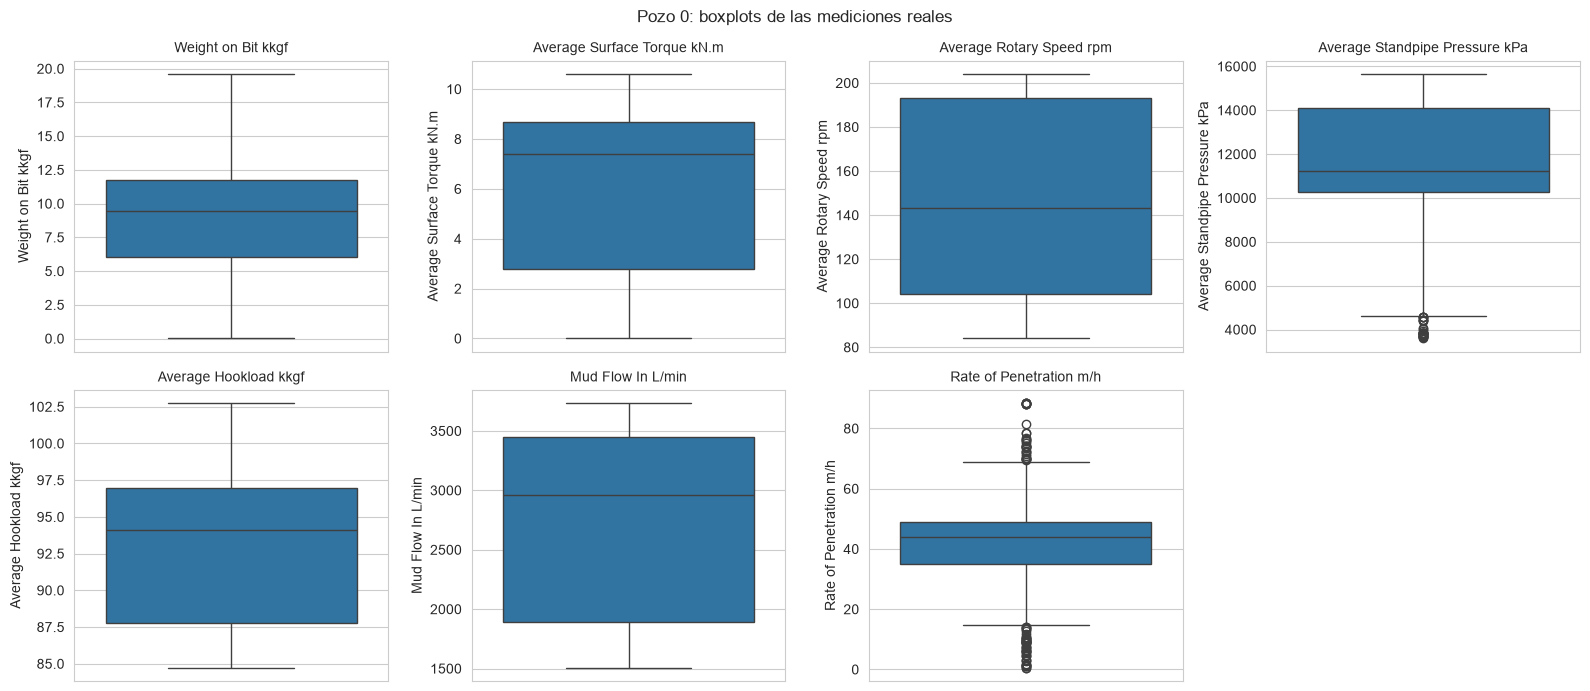

In [59]:
boxplots(final_0, variables_outliers, 'Pozo 0: boxplots de las mediciones reales')

### 4.7 Correlación con el ROP

La correlación **simple** mezcla el efecto de la profundidad; la **parcial** lo saca (ver sección 10.6.2 del Notebook 1). La tercera columna dice cuánto se pega cada variable a la profundidad.

In [60]:
corr_0 = corr_simple_parcial(final_0)
corr_0

,Simple,Parcial (sin profundidad),Simple con la profundidad
Average Rotary Speed rpm,0.39,0.53,0.85
Average Standpipe Pressure kPa,0.27,0.37,-0.41
Average Surface Torque kN.m,0.25,0.25,0.80
Mud Flow In L/min,0.02,0.18,-0.82
Weight on Bit kkgf,0.16,0.09,0.48
Average Hookload kkgf,-0.14,-0.07,-0.80


### 4.8 Guardar

Se guarda con un nombre propio, con las 10 columnas en el orden oficial. **No se sobrescribe ningún archivo original.**

In [61]:
final_0.to_csv('USROP_A 0 sin relleno.csv', index=False)
print('Guardado: USROP_A 0 sin relleno.csv', final_0.shape, '| nulos:', final_0.isna().sum().sum())

Guardado: USROP_A 0 sin relleno.csv (3845, 10) | nulos: 0


<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Conclusión Parte 4 (pozo 0):** resumen del pozo 0, paso por paso:

- **4.1 Archivo:** 16.670 filas y dos tramos: 12,25 pulgadas (10.000 filas, de 273 a 848 m) y 8,5 (6.670 filas, de 880 a 1.206 m). No hay tramos de 26 pulgadas o más y las filas ya vienen en orden: las reglas 1 y 2 **no cambian nada**. El pozo empieza a los 273 m.
- **4.2 Qué hay medido:** es el pozo con más datos de superficie: ~33,5 % de las filas por sensor (contra 3 % a 16 % en los demás). Los sensores reportan juntos en el 98,6 % de los casos.
- **4.3 Limpieza:** se invalidaron **2.735 valores**: 1.261 WOB negativos (de ~−53 kkgf, casi todos en un bloque), 223 torques negativos, 1.182 ROP mayores a 100 y 69 ROP sin perforar. Son las maniobras de 300 a 430 m y de 900 a 962 m (ver 2.3.6).
- **4.4 Nulos que quedan:** de 5.603 filas con datos de superficie, **3.845 completas** y 1.758 incompletas. Acá las incompletas no pierden de a un valor: 1.009 pierden dos (WOB y ROP, el bloque de maniobra). Se descartan. La densidad está en 1.612 de las filas completas y el Gamma en 1.445.
- **4.5 Dataset final:** **3.845 filas × 10 columnas**, sin nulos ni duplicados, y todas cumplen los rangos físicos. Cubre de 489 a 1.206 m: los primeros ~215 m del pozo (de 273 a 489) no tienen filas completas, son la maniobra del comienzo. Registra cada 0,15 m (5,4 filas por metro). Hay dos saltos grandes: 75 m (de 843 a 918, donde cambia el tramo) y 34 m (de 922 a 956). El diámetro toma dos valores. El ROP promedia 41,5 m/h (mediana 44,0; máximo 88,4) y la presión es la más baja del grupo (3.593 a 15.664 kPa).
- **4.6 Outliers:** pocos: el ROP (2,1 %: 47 bajos y 34 altos) y la presión (28 bajos). WOB, torque, RPM, caudal y hookload, ninguno.
- **4.7 Correlación con el ROP:** la parcial más alta es la **RPM (0,53)**, seguida de la presión (0,37), el torque (0,25), el caudal (0,18), el WOB (0,09) y el hookload (−0,07). En los pozos 1 y 6 la más alta era el torque. El torque sigue en ~0,25 y el hookload cerca de cero.
- **4.8 Guardado:** `USROP_A 0 sin relleno.csv`.

**En una frase:** el pozo 0 aporta **3.845 mediciones reales** (23,1 % de sus filas, el mayor porcentaje del grupo), una vez descartada la maniobra del comienzo.

</div>

<div style="background-color:#1f5fa8; color:#ffffff; padding:26px 32px; border-radius:8px; margin:40px 0 10px 0;"><div style="font-size:42px; font-weight:bold; line-height:1.1; color:#ffffff;">POZO 2</div><div style="font-size:17px; margin-top:6px; color:#dbe9f8;">Parte 5</div></div>

## Parte 5. Pozo 2

Seguimos la plantilla de la intro: los mismos 9 pasos que en el resto de los pozos.

### 5.1 El archivo y sus tramos

In [62]:
crudo_2 = cargar_pozo(2)
print('Filas:', len(crudo_2), '| Columnas leídas:', crudo_2.shape[1])
print('Profundidad medida (MD):', crudo_2['Measured Depth m'].min(), 'a', crudo_2['Measured Depth m'].max(), 'm')
print()
tramos_2 = crudo_2.groupby('pulgadas').agg(filas=('pulgadas', 'size'), MD_mín=('Measured Depth m', 'min'), MD_máx=('Measured Depth m', 'max'))
tramos_2.index.name = 'diámetro (pulgadas)'
tramos_2.round(1)

Filas: 110301 | Columnas leídas: 14
Profundidad medida (MD): 0.0 a 3466.07 m



,filas,MD_mín,MD_máx
diámetro (pulgadas),,,
8.50,30000,2661.1,3466.1
12.25,10000,2186.3,2569.4
17.50,40301,984.9,2281.5
26.00,30000,0.0,1066.1


### 5.2 Qué hay realmente medido

Medimos qué porcentaje de las filas tiene dato real en cada variable, y si los sensores del núcleo reportan juntos (como en el pozo 1).

In [63]:
presencia_2 = (100 * crudo_2[grupo_superficie + [densidad]].notna().mean()).round(1)
presencia_2['Gamma Ray (alguna columna)'] = round(100 * crudo_2['Gamma medido'].mean(), 1)
presencia_2.name = '% de filas con dato real'
display(presencia_2)

alguna = crudo_2[grupo_superficie].notna().any(axis=1)
todas = crudo_2[grupo_superficie].notna().all(axis=1)
print('Filas con alguna variable del grupo de superficie:', alguna.sum(), '| con las 7 a la vez:', todas.sum(),
      '| % que reporta junto:', round(100 * todas.sum() / alguna.sum(), 1))

# correlación entre los INDICADORES de nulo (1 = siempre faltan juntos, 0 = independientes)
wob_nulo = crudo_2['Weight on Bit kkgf'].isna().astype(int)
print('WOB nulo vs Torque nulo:', round(wob_nulo.corr(crudo_2['Average Surface Torque kN.m'].isna().astype(int)), 3))
print('WOB nulo vs Gamma nulo :', round(wob_nulo.corr((~crudo_2['Gamma medido']).astype(int)), 3))

Weight on Bit kkgf                 3.0
Average Surface Torque kN.m        3.0
Average Rotary Speed rpm           2.7
Average Standpipe Pressure kPa     2.7
Average Hookload kkgf              3.0
Mud Flow In L/min                  3.0
Rate of Penetration m/h            2.7
Mud Density In g/cm3               2.8
Gamma Ray (alguna columna)        15.2
Name: % de filas con dato real, dtype: float64

Filas con alguna variable del grupo de superficie: 3263 | con las 7 a la vez: 3031 | % que reporta junto: 92.9
WOB nulo vs Torque nulo: 1.0
WOB nulo vs Gamma nulo : -0.042


### 5.3 Limpieza (sin relleno)

Aplicamos las tres reglas de la Parte 2, **una por una**, para ver qué hace cada una.

#### 5.3.1 Regla 1: sacar los tramos de 26 pulgadas o más

In [64]:
prep_2 = preparar_pozo(crudo_2)
print('Filas antes:', len(crudo_2), '| después de sacar los tramos grandes:', len(prep_2),
      '| filas sacadas:', len(crudo_2) - len(prep_2))
print('Tramos que quedan (pulgadas):', sorted(prep_2['pulgadas'].unique(), reverse=True))

Filas antes: 110301 | después de sacar los tramos grandes: 80301 | filas sacadas: 30000
Tramos que quedan (pulgadas): [np.float64(17.5), np.float64(12.25), np.float64(8.5)]


#### 5.3.2 Regla 2: ordenar por tramo y profundidad

Verificamos que, dentro de cada tramo, la profundidad quedó creciente.

In [65]:
for p, g in prep_2.groupby('pulgadas', sort=False):
    print(f'Tramo de {p:g} pulgadas: {len(g)} filas | profundidad creciente dentro del tramo:', g['Measured Depth m'].is_monotonic_increasing)

Tramo de 17.5 pulgadas: 40301 filas | profundidad creciente dentro del tramo: True
Tramo de 12.25 pulgadas: 10000 filas | profundidad creciente dentro del tramo: True
Tramo de 8.5 pulgadas: 30000 filas | profundidad creciente dentro del tramo: True


#### 5.3.3 Regla 3: valores imposibles a `NaN`

In [66]:
inval_2, conteo_2 = invalidar_imposibles(prep_2)
display(conteo_2[conteo_2 > 0] if conteo_2.sum() else conteo_2)
print('Total de valores invalidados:', conteo_2.sum(), '| filas del pozo (no se borró ninguna):', len(inval_2))

ROP > 100                                 1
ROP sin perforar (RPM<20 o caudal<500)    2
Name: valores invalidados, dtype: int64

Total de valores invalidados: 3 | filas del pozo (no se borró ninguna): 80301


### 5.4 Nulos que quedan

Sin relleno, el grupo de superficie tiene filas completas e incompletas. Vemos cuántas hay de cada una y qué falta en las incompletas.

In [67]:
alguna = inval_2[grupo_superficie].notna().any(axis=1)
completas = filas_completas(inval_2)
incompletas = alguna & ~inval_2[grupo_superficie].notna().all(axis=1)

print('Filas donde el grupo de superficie midió algo:', alguna.sum())
print('   completas (7 variables + TVD):', completas.sum())
print('   incompletas (falta alguna de las 7):', incompletas.sum())
if incompletas.sum():
    print()
    print('Qué variable falta en las filas incompletas:')
    print(inval_2.loc[incompletas, grupo_superficie].isna().sum()[lambda s: s > 0])
    print('Variables que faltan por fila incompleta:', inval_2.loc[incompletas, grupo_superficie].isna().sum(axis=1).value_counts().to_dict())

print()
print('De las filas completas, tienen densidad:', inval_2.loc[completas, densidad].notna().sum(),
      '| tienen Gamma:', int(inval_2.loc[completas, 'Gamma medido'].sum()), '| de', completas.sum())

Filas donde el grupo de superficie midió algo: 2394
   completas (7 variables + TVD): 2159
   incompletas (falta alguna de las 7): 235

Qué variable falta en las filas incompletas:
Average Rotary Speed rpm          232
Average Standpipe Pressure kPa    232
Rate of Penetration m/h           235
dtype: int64
Variables que faltan por fila incompleta: {3: 232, 1: 3}

De las filas completas, tienen densidad: 2159 | tienen Gamma: 29 | de 2159


### 5.5 Dataset final del pozo 2

Armamos el dataset (solo filas completas, 10 columnas) y lo verificamos: forma, ceros, estadística, rangos físicos y reparto por profundidad.

In [68]:
final_2 = armar_dataset(inval_2)
print('Dataset final del pozo 2 (solo mediciones reales):', final_2.shape)
chequeos_generales(final_2)

Dataset final del pozo 2 (solo mediciones reales): (2158, 10)
Filas: 2158 | Columnas: 10
Filas duplicadas: 0 | Valores infinitos: 0
Profundidad medida (MD) creciente: True
Filas con TVD mayor que MD: 0 | mayor diferencia (m): -0.489
Paso entre filas consecutivas (m): mediana 1.0 | máximo 185.998
Saltos de más de 5 m: 2
   salto de 186.0 m: de 2569.0 a 2755.0 m
   salto de 49.0 m: de 2930.0 a 2979.0 m


In [69]:
ficha_columnas(final_2)

,tipo,valores distintos,nulos,ceros,negativos,mínimo,máximo
Measured Depth m,float64,2158,0,0,0,1049.999,3466.000
Weight on Bit kkgf,float64,875,0,0,0,0.469,15.092
Average Standpipe Pressure kPa,float64,1753,0,0,0,6479.000,25114.000
Average Surface Torque kN.m,float64,882,0,0,0,2.110,26.550
Rate of Penetration m/h,float64,1579,0,0,0,0.330,56.310
Average Rotary Speed rpm,float64,800,0,0,0,24.530,181.550
Mud Flow In L/min,float64,1003,0,0,0,1581.230,4538.450
Diameter mm,float64,3,0,0,0,215.900,444.500
Average Hookload kkgf,float64,1413,0,0,0,100.666,152.927
Hole Depth (TVD) m,float64,2158,0,0,0,1049.510,2993.791


In [70]:
estadistica_2 = final_2.describe().T
estadistica_2['asimetría'] = final_2.skew()
estadistica_2.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetría
Measured Depth m,2158.0,2205.65,715.34,1050.00,1592.25,2137.50,2868.75,3466.00,0.18
Weight on Bit kkgf,2158.0,5.53,2.57,0.47,4.09,5.13,6.49,15.09,1.16
Average Standpipe Pressure kPa,2158.0,17430.15,3209.21,6479.00,15531.50,17495.00,18929.50,25114.00,-0.01
Average Surface Torque kN.m,2158.0,11.33,2.65,2.11,9.62,11.41,12.83,26.55,0.94
Rate of Penetration m/h,2158.0,29.17,12.79,0.33,19.42,29.23,40.11,56.31,-0.07
Average Rotary Speed rpm,2158.0,140.64,32.11,24.53,120.11,159.42,160.37,181.55,-1.23
Mud Flow In L/min,2158.0,3396.25,997.61,1581.23,1985.22,3958.59,4229.05,4538.45,-0.59
Diameter mm,2158.0,357.91,103.02,215.90,215.90,444.50,444.50,444.50,-0.47
Average Hookload kkgf,2158.0,132.71,13.78,100.67,128.30,138.30,140.61,152.93,-0.94
Hole Depth (TVD) m,2158.0,2132.54,616.30,1049.51,1591.76,2136.99,2789.89,2993.79,-0.09


In [71]:
display(rangos_fisicos(final_2))
reparto_profundidad(final_2)

,filas que cumplen,de un total de
Weight on Bit entre 0 y 35,2158,2158
Torque >= 0,2158,2158
Presión entre 0 y 51.700,2158,2158
Caudal >= 0,2158,2158
ROP entre 0 y 100,2158,2158
RPM >= 0,2158,2158
Hookload > 0,2158,2158


,filas,ROP promedio (m/h)
Measured Depth m,,
"(1000, 1100]",50,13.2
"(1100, 1200]",97,25.4
"(1200, 1300]",101,37.6
"(1300, 1400]",99,39.1
"(1400, 1500]",101,34.9
"(1500, 1600]",100,27.6
"(1600, 1700]",99,36.7
"(1700, 1800]",101,39.6
"(1800, 1900]",94,39.8


### 5.6 Outliers (sobre mediciones reales)

Con el criterio del IQR (más de 1,5 veces el rango intercuartílico por debajo de Q1 o por encima de Q3) y con z-score, solo sobre las filas reales.

In [72]:
variables_outliers = nucleo + [objetivo]
tabla_outliers(final_2, variables_outliers)

,por debajo (IQR),por encima (IQR),% IQR,outliers (z>3)
variable,,,,
Weight on Bit kkgf,3,145,6.9,26
Average Surface Torque kN.m,7,30,1.7,29
Average Rotary Speed rpm,60,0,2.8,4
Average Standpipe Pressure kPa,43,41,3.9,34
Average Hookload kkgf,325,0,15.1,0
Mud Flow In L/min,0,0,0.0,0
Rate of Penetration m/h,0,0,0.0,0


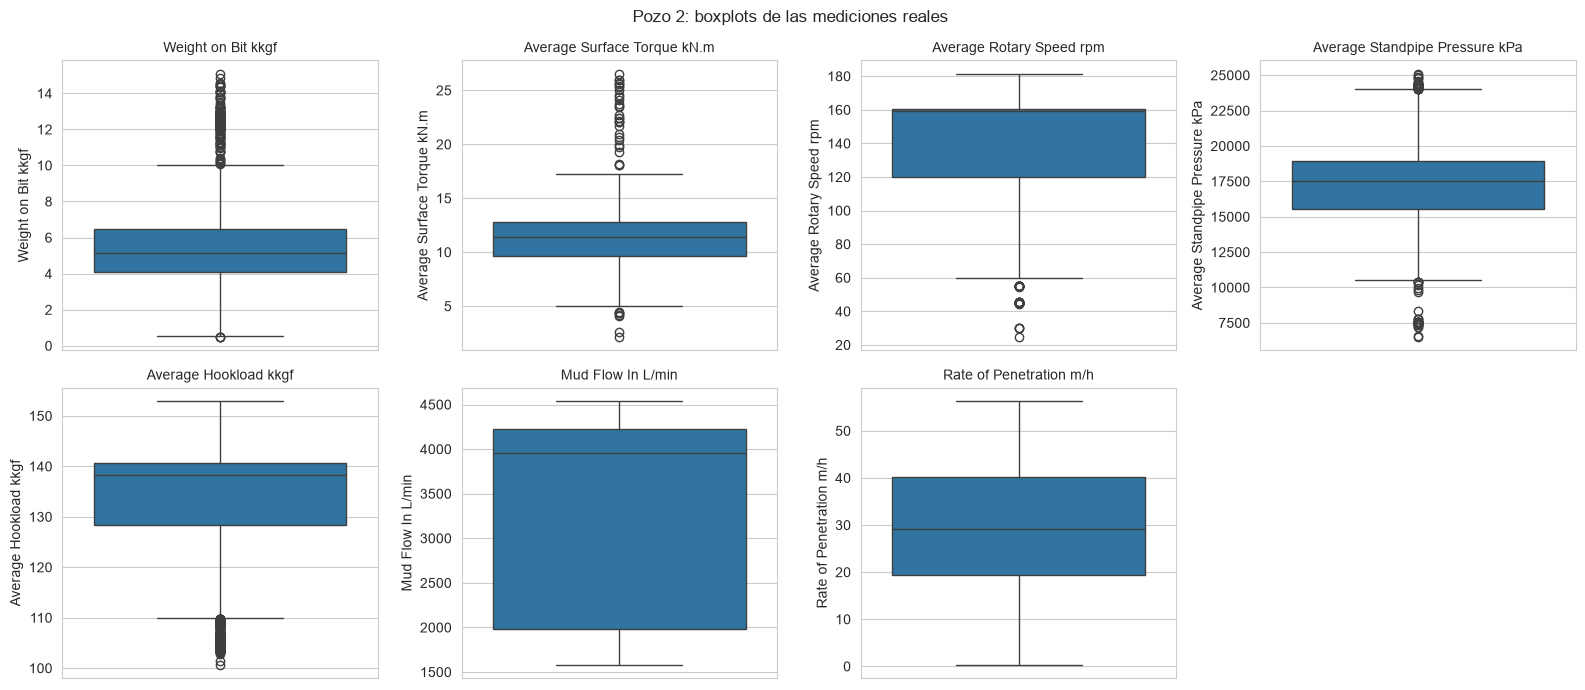

In [73]:
boxplots(final_2, variables_outliers, 'Pozo 2: boxplots de las mediciones reales')

### 5.7 Correlación con el ROP

La correlación **simple** mezcla el efecto de la profundidad; la **parcial** lo saca (ver sección 10.6.2 del Notebook 1). La tercera columna dice cuánto se pega cada variable a la profundidad.

In [74]:
corr_2 = corr_simple_parcial(final_2)
corr_2

,Simple,Parcial (sin profundidad),Simple con la profundidad
Average Standpipe Pressure kPa,0.21,0.51,0.45
Mud Flow In L/min,0.52,0.44,-0.84
Average Surface Torque kN.m,0.17,0.33,0.52
Average Rotary Speed rpm,0.25,0.27,0.32
Average Hookload kkgf,-0.10,0.14,0.72
Weight on Bit kkgf,-0.17,0.05,0.51


### 5.8 Guardar

Se guarda con un nombre propio, con las 10 columnas en el orden oficial. **No se sobrescribe ningún archivo original.**

In [75]:
final_2.to_csv('USROP_A 2 sin relleno.csv', index=False)
print('Guardado: USROP_A 2 sin relleno.csv', final_2.shape, '| nulos:', final_2.isna().sum().sum())

Guardado: USROP_A 2 sin relleno.csv (2158, 10) | nulos: 0


<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Conclusión Parte 5 (pozo 2):** resumen del pozo 2, paso por paso:

- **5.1 Archivo:** 110.301 filas y cuatro tramos: 26 pulgadas (30.000 filas, de 0 a 1.066 m), 17,5 (40.301, de 985 a 2.282 m), 12,25 (10.000, de 2.186 a 2.570 m) y 8,5 (30.000, de 2.661 a 3.466 m). El archivo **no está ordenado por profundidad** (el tramo de 8,5 viene antes que el de 17,5). La regla 1 saca los 30.000 de 26 pulgadas y la regla 2 ordena el resto.
- **5.2 Qué hay medido:** solo ~3 % de las filas tiene datos de superficie, y reportan juntos en el 92,9 % de los casos.
- **5.3 Limpieza:** es el pozo más limpio: solo **3 valores invalidados** (1 ROP mayor a 100 y 2 ROP sin perforar).
- **5.4 Nulos que quedan:** 2.394 filas con datos de superficie, **2.159 completas** y 235 incompletas. En 232 de las incompletas faltan a la vez la RPM, la presión y el ROP. Se descartan.
- **5.5 Dataset final:** **2.158 filas × 10 columnas**: había una fila idéntica repetida (a los 2.919 m) y se elimina. Sin nulos, y todas cumplen los rangos físicos. Cubre de 1.050 a 3.466 m, con una fila por metro y dos huecos: 186 m (de 2.569 a 2.755) y 49 m (de 2.930 a 2.979). El diámetro toma tres valores. El ROP promedia 29,2 m/h y nunca pasa de 56,3. El hookload sube de 101 a 153 kkgf a medida que se alarga la sarta.
- **5.6 Outliers:** el hookload da 15,1 % por IQR, pero es un efecto de la profundidad (el valor sube con la sarta y el IQR lo mira sobre todo el pozo junto), no un error. El WOB da 6,9 % (145 altos). Caudal y ROP, ninguno.
- **5.7 Correlación con el ROP:** la parcial más alta es la **presión (0,51)**, luego el caudal (0,44), el torque (0,33), la RPM (0,27), el hookload (0,14) y el WOB (0,05).
- **5.8 Guardado:** `USROP_A 2 sin relleno.csv`.

**En una frase:** el pozo 2 aporta **2.158 mediciones reales** (2,7 % de las filas que quedan sin el tramo de 26 pulgadas) y es el más limpio del grupo.

</div>

<div style="background-color:#1f5fa8; color:#ffffff; padding:26px 32px; border-radius:8px; margin:40px 0 10px 0;"><div style="font-size:42px; font-weight:bold; line-height:1.1; color:#ffffff;">POZO 3</div><div style="font-size:17px; margin-top:6px; color:#dbe9f8;">Parte 6</div></div>

## Parte 6. Pozo 3

Seguimos la plantilla de la intro: los mismos 9 pasos que en el resto de los pozos.

### 6.1 El archivo y sus tramos

In [76]:
crudo_3 = cargar_pozo(3)
print('Filas:', len(crudo_3), '| Columnas leídas:', crudo_3.shape[1])
print('Profundidad medida (MD):', crudo_3['Measured Depth m'].min(), 'a', crudo_3['Measured Depth m'].max(), 'm')
print()
tramos_3 = crudo_3.groupby('pulgadas').agg(filas=('pulgadas', 'size'), MD_mín=('Measured Depth m', 'min'), MD_máx=('Measured Depth m', 'max'))
tramos_3.index.name = 'diámetro (pulgadas)'
tramos_3.round(1)

Filas: 112714 | Columnas leídas: 14
Profundidad medida (MD): 1178.509 a 4065.345999999999 m



,filas,MD_mín,MD_máx
diámetro (pulgadas),,,
8.5,50000,2464.2,4065.3
17.5,62714,1178.5,2591.1


### 6.2 Qué hay realmente medido

Medimos qué porcentaje de las filas tiene dato real en cada variable, y si los sensores del núcleo reportan juntos (como en el pozo 1).

In [77]:
presencia_3 = (100 * crudo_3[grupo_superficie + [densidad]].notna().mean()).round(1)
presencia_3['Gamma Ray (alguna columna)'] = round(100 * crudo_3['Gamma medido'].mean(), 1)
presencia_3.name = '% de filas con dato real'
display(presencia_3)

alguna = crudo_3[grupo_superficie].notna().any(axis=1)
todas = crudo_3[grupo_superficie].notna().all(axis=1)
print('Filas con alguna variable del grupo de superficie:', alguna.sum(), '| con las 7 a la vez:', todas.sum(),
      '| % que reporta junto:', round(100 * todas.sum() / alguna.sum(), 1))

# correlación entre los INDICADORES de nulo (1 = siempre faltan juntos, 0 = independientes)
wob_nulo = crudo_3['Weight on Bit kkgf'].isna().astype(int)
print('WOB nulo vs Torque nulo:', round(wob_nulo.corr(crudo_3['Average Surface Torque kN.m'].isna().astype(int)), 3))
print('WOB nulo vs Gamma nulo :', round(wob_nulo.corr((~crudo_3['Gamma medido']).astype(int)), 3))

Weight on Bit kkgf                16.0
Average Surface Torque kN.m       16.0
Average Rotary Speed rpm          16.0
Average Standpipe Pressure kPa    16.0
Average Hookload kkgf             16.0
Mud Flow In L/min                 15.9
Rate of Penetration m/h           16.0
Mud Density In g/cm3               2.3
Gamma Ray (alguna columna)        11.1
Name: % de filas con dato real, dtype: float64

Filas con alguna variable del grupo de superficie: 18050 | con las 7 a la vez: 17846 | % que reporta junto: 98.9
WOB nulo vs Torque nulo: 1.0
WOB nulo vs Gamma nulo : 0.809


### 6.3 Limpieza (sin relleno)

Aplicamos las tres reglas de la Parte 2, **una por una**, para ver qué hace cada una.

#### 6.3.1 Regla 1: sacar los tramos de 26 pulgadas o más

In [78]:
prep_3 = preparar_pozo(crudo_3)
print('Filas antes:', len(crudo_3), '| después de sacar los tramos grandes:', len(prep_3),
      '| filas sacadas:', len(crudo_3) - len(prep_3))
print('Tramos que quedan (pulgadas):', sorted(prep_3['pulgadas'].unique(), reverse=True))

Filas antes: 112714 | después de sacar los tramos grandes: 112714 | filas sacadas: 0
Tramos que quedan (pulgadas): [np.float64(17.5), np.float64(8.5)]


#### 6.3.2 Regla 2: ordenar por tramo y profundidad

Verificamos que, dentro de cada tramo, la profundidad quedó creciente.

In [79]:
for p, g in prep_3.groupby('pulgadas', sort=False):
    print(f'Tramo de {p:g} pulgadas: {len(g)} filas | profundidad creciente dentro del tramo:', g['Measured Depth m'].is_monotonic_increasing)

Tramo de 17.5 pulgadas: 62714 filas | profundidad creciente dentro del tramo: True
Tramo de 8.5 pulgadas: 50000 filas | profundidad creciente dentro del tramo: True


#### 6.3.3 Regla 3: valores imposibles a `NaN`

In [80]:
inval_3, conteo_3 = invalidar_imposibles(prep_3)
display(conteo_3[conteo_3 > 0] if conteo_3.sum() else conteo_3)
print('Total de valores invalidados:', conteo_3.sum(), '| filas del pozo (no se borró ninguna):', len(inval_3))

WOB < 0                                    534
WOB > 35                                   679
Torque < 0                                   3
Presión > 51700                            122
ROP > 100                                 1274
ROP sin perforar (RPM<20 o caudal<500)     219
Name: valores invalidados, dtype: int64

Total de valores invalidados: 2831 | filas del pozo (no se borró ninguna): 112714


### 6.4 Nulos que quedan

Sin relleno, el grupo de superficie tiene filas completas e incompletas. Vemos cuántas hay de cada una y qué falta en las incompletas.

In [81]:
alguna = inval_3[grupo_superficie].notna().any(axis=1)
completas = filas_completas(inval_3)
incompletas = alguna & ~inval_3[grupo_superficie].notna().all(axis=1)

print('Filas donde el grupo de superficie midió algo:', alguna.sum())
print('   completas (7 variables + TVD):', completas.sum())
print('   incompletas (falta alguna de las 7):', incompletas.sum())
if incompletas.sum():
    print()
    print('Qué variable falta en las filas incompletas:')
    print(inval_3.loc[incompletas, grupo_superficie].isna().sum()[lambda s: s > 0])
    print('Variables que faltan por fila incompleta:', inval_3.loc[incompletas, grupo_superficie].isna().sum(axis=1).value_counts().to_dict())

print()
print('De las filas completas, tienen densidad:', inval_3.loc[completas, densidad].notna().sum(),
      '| tienen Gamma:', int(inval_3.loc[completas, 'Gamma medido'].sum()), '| de', completas.sum())

Filas donde el grupo de superficie midió algo: 18050
   completas (7 variables + TVD): 16276
   incompletas (falta alguna de las 7): 1774

Qué variable falta en las filas incompletas:
Weight on Bit kkgf                1214
Average Surface Torque kN.m         11
Average Rotary Speed rpm             1
Average Standpipe Pressure kPa     180
Average Hookload kkgf                1
Mud Flow In L/min                   93
Rate of Penetration m/h           1564
dtype: int64
Variables que faltan por fila incompleta: {2: 903, 1: 685, 3: 177, 4: 4, 5: 4, 6: 1}

De las filas completas, tienen densidad: 44 | tienen Gamma: 12041 | de 16276


### 6.5 Dataset final del pozo 3

Armamos el dataset (solo filas completas, 10 columnas) y lo verificamos: forma, ceros, estadística, rangos físicos y reparto por profundidad.

In [82]:
final_3 = armar_dataset(inval_3)
print('Dataset final del pozo 3 (solo mediciones reales):', final_3.shape)
chequeos_generales(final_3)

Dataset final del pozo 3 (solo mediciones reales): (16276, 10)
Filas: 16276 | Columnas: 10
Filas duplicadas: 0 | Valores infinitos: 0
Profundidad medida (MD) creciente: True
Filas con TVD mayor que MD: 0 | mayor diferencia (m): -22.833
Paso entre filas consecutivas (m): mediana 0.152 | máximo 166.573
Saltos de más de 5 m: 4
   salto de 27.0 m: de 2591.1 a 2618.1 m
   salto de 45.9 m: de 3113.7 a 3159.6 m
   salto de 5.2 m: de 3162.0 a 3167.2 m
   salto de 166.6 m: de 3350.5 a 3517.1 m


In [83]:
ficha_columnas(final_3)

,tipo,valores distintos,nulos,ceros,negativos,mínimo,máximo
Measured Depth m,float64,16276,0,0,0,1297.229,4065.270
Weight on Bit kkgf,float64,8690,0,1,0,0.000,19.858
Average Standpipe Pressure kPa,float64,15618,0,0,0,5895.983,27766.601
Average Surface Torque kN.m,float64,7113,0,0,0,5.437,36.489
Rate of Penetration m/h,float64,5885,0,0,0,1.591,99.206
Average Rotary Speed rpm,float64,4355,0,0,0,29.000,202.350
Mud Flow In L/min,float64,1051,0,0,0,1645.522,4573.043
Diameter mm,float64,2,0,0,0,215.900,444.500
Average Hookload kkgf,float64,10364,0,0,0,113.915,150.131
Hole Depth (TVD) m,float64,16276,0,0,0,1274.396,3189.256


In [84]:
estadistica_3 = final_3.describe().T
estadistica_3['asimetría'] = final_3.skew()
estadistica_3.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetría
Measured Depth m,16276.0,2626.39,806.57,1297.23,1934.07,2557.04,3271.15,4065.27,0.16
Weight on Bit kkgf,16276.0,6.25,4.49,0.00,2.15,5.22,9.22,19.86,0.68
Average Standpipe Pressure kPa,16276.0,19971.75,5392.28,5895.98,14842.63,18863.02,25550.94,27766.60,0.08
Average Surface Torque kN.m,16276.0,19.09,7.19,5.44,12.46,18.25,25.66,36.49,0.22
Rate of Penetration m/h,16276.0,22.02,8.59,1.59,17.81,19.79,28.87,99.21,1.60
Average Rotary Speed rpm,16276.0,133.35,21.67,29.00,120.00,139.00,139.96,202.35,-1.35
Mud Flow In L/min,16276.0,3260.30,1159.53,1645.52,2077.18,3987.86,4453.12,4573.04,-0.01
Diameter mm,16276.0,333.35,114.26,215.90,215.90,444.50,444.50,444.50,-0.06
Average Hookload kkgf,16276.0,132.86,6.88,113.92,127.38,130.74,138.12,150.13,0.46
Hole Depth (TVD) m,16276.0,2338.20,554.07,1274.40,1856.82,2413.92,2853.17,3189.26,-0.28


In [85]:
display(rangos_fisicos(final_3))
reparto_profundidad(final_3)

,filas que cumplen,de un total de
Weight on Bit entre 0 y 35,16276,16276
Torque >= 0,16276,16276
Presión entre 0 y 51.700,16276,16276
Caudal >= 0,16276,16276
ROP entre 0 y 100,16276,16276
RPM >= 0,16276,16276
Hookload > 0,16276,16276


,filas,ROP promedio (m/h)
Measured Depth m,,
"(1200, 1300]",2,74.0
"(1300, 1400]",581,19.6
"(1400, 1500]",653,15.1
"(1500, 1600]",656,17.0
"(1600, 1700]",645,15.1
"(1700, 1800]",655,17.5
"(1800, 1900]",654,18.5
"(1900, 2000]",652,20.0
"(2000, 2100]",654,19.8


### 6.6 Outliers (sobre mediciones reales)

Con el criterio del IQR (más de 1,5 veces el rango intercuartílico por debajo de Q1 o por encima de Q3) y con z-score, solo sobre las filas reales.

In [86]:
variables_outliers = nucleo + [objetivo]
tabla_outliers(final_3, variables_outliers)

,por debajo (IQR),por encima (IQR),% IQR,outliers (z>3)
variable,,,,
Weight on Bit kkgf,0,1,0.0,3
Average Surface Torque kN.m,0,0,0.0,0
Average Rotary Speed rpm,663,361,6.3,552
Average Standpipe Pressure kPa,0,0,0.0,0
Average Hookload kkgf,0,0,0.0,0
Mud Flow In L/min,0,0,0.0,0
Rate of Penetration m/h,0,82,0.5,78


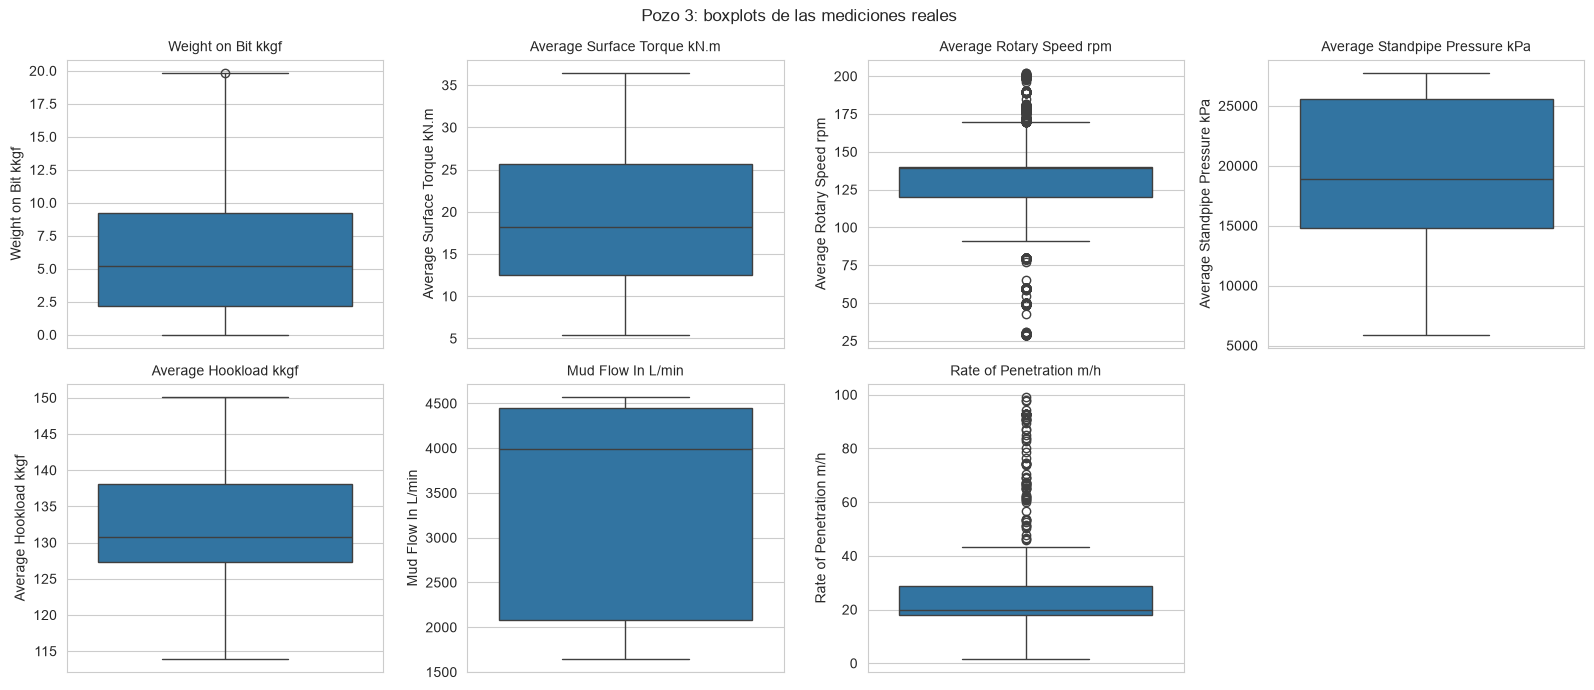

In [87]:
boxplots(final_3, variables_outliers, 'Pozo 3: boxplots de las mediciones reales')

### 6.7 Correlación con el ROP

La correlación **simple** mezcla el efecto de la profundidad; la **parcial** lo saca (ver sección 10.6.2 del Notebook 1). La tercera columna dice cuánto se pega cada variable a la profundidad.

In [88]:
corr_3 = corr_simple_parcial(final_3)
corr_3

,Simple,Parcial (sin profundidad),Simple con la profundidad
Average Rotary Speed rpm,0.26,0.08,0.44
Average Surface Torque kN.m,0.56,0.03,0.96
Weight on Bit kkgf,0.53,0.02,0.86
Average Hookload kkgf,-0.08,-0.06,0.06
Average Standpipe Pressure kPa,-0.50,-0.18,-0.64
Mud Flow In L/min,-0.57,-0.21,-0.83


### 6.8 Guardar

Se guarda con un nombre propio, con las 10 columnas en el orden oficial. **No se sobrescribe ningún archivo original.**

In [89]:
final_3.to_csv('USROP_A 3 sin relleno.csv', index=False)
print('Guardado: USROP_A 3 sin relleno.csv', final_3.shape, '| nulos:', final_3.isna().sum().sum())

Guardado: USROP_A 3 sin relleno.csv (16276, 10) | nulos: 0


**Cómo se recuperó la RPM en este pozo.** Lecturas de RPM por profundidad, con la columna principal sola y con el canal equivalente (2.1.1):

In [90]:
rpm_principal = pd.read_csv(archivos_crudos[3], usecols=['name', 'Measured Depth m', RPM])
rpm_principal['pulgadas'] = rpm_principal['name'].map(pulgadas)
rpm_principal = rpm_principal[rpm_principal['pulgadas'] < 26]
bandas = pd.cut(rpm_principal['Measured Depth m'], [1000, 2000, 2600, 3000, 3500, 4100])
superficie = crudo_3[grupo_superficie].notna().any(axis=1)
pd.DataFrame({'filas con datos de superficie': superficie.groupby(pd.cut(crudo_3['Measured Depth m'], [1000, 2000, 2600, 3000, 3500, 4100]), observed=True).sum(),
              'con la columna principal de RPM': rpm_principal[RPM].notna().groupby(bandas, observed=True).sum(),
              'con el canal equivalente': crudo_3[RPM].notna().groupby(pd.cut(crudo_3['Measured Depth m'], [1000, 2000, 2600, 3000, 3500, 4100]), observed=True).sum()})

,filas con datos de superficie,con la columna principal de RPM,con el canal equivalente
Measured Depth m,,,
"(1000, 2000]",5248,5248,5248
"(2000, 2600]",4527,3873,4527
"(2600, 3000]",2616,0,2616
"(3000, 3500]",2061,0,2060
"(3500, 4100]",3598,0,3598


<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Conclusión Parte 6 (pozo 3):** resumen del pozo 3, paso por paso:

- **6.1 Archivo:** 112.714 filas y dos tramos: 17,5 pulgadas (62.714 filas, de 1.179 a 2.591 m) y 8,5 (50.000, de 2.464 a 4.065 m); se pisan entre 2.464 y 2.591 m. El pozo empieza a los 1.179 m. No hay nada que sacar y ya viene ordenado.
- **6.2 Qué hay medido:** ~16 % de las filas por sensor. La columna principal de RPM (`Average Rotary Speed`) solo tiene el 8,1 % porque **no tiene ninguna lectura por debajo de los ~2.600 m**; con su canal equivalente (`Total Downhole RPM`, ver 2.1.1) llega al 16 %, como los demás sensores. Con la columna principal sola, los sensores reportaban juntos en el 50,4 % de los casos; con el canal equivalente, en el 98,9 %.
- **6.3 Limpieza:** se invalidaron **2.831 valores**: 534 WOB negativos, 679 WOB mayores a 35 (**un solo bloque** de 2.500 a 2.604 m, a ~78 kkgf, que no coincide con el hookload), 3 torques negativos, 122 presiones absurdas (hasta 10³² kPa), 1.274 ROP mayores a 100 y 219 ROP sin perforar. En el 61 % de los ROP > 100 la mecha no estaba perforando (maniobras al comenzar las corridas 3 y 5).
- **6.4 Nulos que quedan:** 18.050 filas con datos de superficie, **16.276 completas** y 1.774 incompletas (casi todas por un ROP o un WOB invalidado). La densidad está en solo 44 de las filas completas y el Gamma en 12.041.
- **6.5 Dataset final:** **16.276 filas × 10 columnas**, sin nulos ni duplicados. Cubre de 1.297 a 4.065 m, casi todo el pozo, con 5,9 filas por metro. Hay cuatro saltos: 27 m (de 2.591 a 2.618, el cambio de tramo), 46 m (de 3.114 a 3.160), 5 m y 167 m (de 3.350 a 3.517). El diámetro toma dos valores. El ROP es parejo en el tramo de 17,5 pulgadas (mediana 19,0 m/h, el 75 % por debajo de 19,7) y más alto en el de 8,5 (mediana 29,1). En el tramo de 17,5 el caudal es casi constante (4.453 L/min en la gran mayoría de las filas).
- **6.6 Outliers:** la RPM da 6,3 % (663 bajos y 361 altos; la mayoría de las filas está entre 120 y 140 rpm) y el ROP 0,5 % (82 altos). Todo lo demás, casi nada.
- **6.7 Correlación con el ROP:** las simples engañan (torque 0,56 y WOB 0,53, porque ambos van pegados a la profundidad: 0,96 y 0,86). **Las parciales son todas débiles**: caudal −0,21, presión −0,18, RPM 0,08, hookload −0,06, torque 0,03 y WOB 0,02. Es el único pozo donde la presión y el caudal tienen correlación parcial negativa con el ROP.
- **6.8 Guardado:** `USROP_A 3 sin relleno.csv`.

**En una frase:** el pozo 3 aporta **16.276 mediciones reales** (14,4 % de sus filas), el mayor aporte del grupo, gracias a recuperar la RPM de su canal equivalente: sin eso eran 8.362 y se perdía todo lo que está por debajo de los 2.600 m.

</div>

<div style="background-color:#1f5fa8; color:#ffffff; padding:26px 32px; border-radius:8px; margin:40px 0 10px 0;"><div style="font-size:42px; font-weight:bold; line-height:1.1; color:#ffffff;">POZO 4</div><div style="font-size:17px; margin-top:6px; color:#dbe9f8;">Parte 7</div></div>

## Parte 7. Pozo 4

Seguimos la plantilla de la intro: los mismos 9 pasos que en el resto de los pozos.

### 7.1 El archivo y sus tramos

In [91]:
crudo_4 = cargar_pozo(4)
print('Filas:', len(crudo_4), '| Columnas leídas:', crudo_4.shape[1])
print('Profundidad medida (MD):', crudo_4['Measured Depth m'].min(), 'a', crudo_4['Measured Depth m'].max(), 'm')
print()
tramos_4 = crudo_4.groupby('pulgadas').agg(filas=('pulgadas', 'size'), MD_mín=('Measured Depth m', 'min'), MD_máx=('Measured Depth m', 'max'))
tramos_4.index.name = 'diámetro (pulgadas)'
tramos_4.round(1)

Filas: 124636 | Columnas leídas: 14
Profundidad medida (MD): 0.0 a 4090.001 m



,filas,MD_mín,MD_máx
diámetro (pulgadas),,,
8.50,84636,0.0,4090.0
12.25,40000,1339.1,2431.7


### 7.2 Qué hay realmente medido

Medimos qué porcentaje de las filas tiene dato real en cada variable, y si los sensores del núcleo reportan juntos (como en el pozo 1).

In [92]:
presencia_4 = (100 * crudo_4[grupo_superficie + [densidad]].notna().mean()).round(1)
presencia_4['Gamma Ray (alguna columna)'] = round(100 * crudo_4['Gamma medido'].mean(), 1)
presencia_4.name = '% de filas con dato real'
display(presencia_4)

alguna = crudo_4[grupo_superficie].notna().any(axis=1)
todas = crudo_4[grupo_superficie].notna().all(axis=1)
print('Filas con alguna variable del grupo de superficie:', alguna.sum(), '| con las 7 a la vez:', todas.sum(),
      '| % que reporta junto:', round(100 * todas.sum() / alguna.sum(), 1))

# correlación entre los INDICADORES de nulo (1 = siempre faltan juntos, 0 = independientes)
wob_nulo = crudo_4['Weight on Bit kkgf'].isna().astype(int)
print('WOB nulo vs Torque nulo:', round(wob_nulo.corr(crudo_4['Average Surface Torque kN.m'].isna().astype(int)), 3))
print('WOB nulo vs Gamma nulo :', round(wob_nulo.corr((~crudo_4['Gamma medido']).astype(int)), 3))

Weight on Bit kkgf                 9.4
Average Surface Torque kN.m       11.5
Average Rotary Speed rpm          15.2
Average Standpipe Pressure kPa    15.0
Average Hookload kkgf              9.4
Mud Flow In L/min                 15.0
Rate of Penetration m/h           14.9
Mud Density In g/cm3               1.9
Gamma Ray (alguna columna)        12.1
Name: % de filas con dato real, dtype: float64

Filas con alguna variable del grupo de superficie: 18924 | con las 7 a la vez: 11622 | % que reporta junto: 61.4
WOB nulo vs Torque nulo: 0.892
WOB nulo vs Gamma nulo : 0.582


### 7.3 Limpieza (sin relleno)

Aplicamos las tres reglas de la Parte 2, **una por una**, para ver qué hace cada una.

#### 7.3.1 Regla 1: sacar los tramos de 26 pulgadas o más

In [93]:
prep_4 = preparar_pozo(crudo_4)
print('Filas antes:', len(crudo_4), '| después de sacar los tramos grandes:', len(prep_4),
      '| filas sacadas:', len(crudo_4) - len(prep_4))
print('Tramos que quedan (pulgadas):', sorted(prep_4['pulgadas'].unique(), reverse=True))

Filas antes: 124636 | después de sacar los tramos grandes: 124636 | filas sacadas: 0
Tramos que quedan (pulgadas): [np.float64(12.25), np.float64(8.5)]


#### 7.3.2 Regla 2: ordenar por tramo y profundidad

Verificamos que, dentro de cada tramo, la profundidad quedó creciente.

In [94]:
for p, g in prep_4.groupby('pulgadas', sort=False):
    print(f'Tramo de {p:g} pulgadas: {len(g)} filas | profundidad creciente dentro del tramo:', g['Measured Depth m'].is_monotonic_increasing)

Tramo de 12.25 pulgadas: 40000 filas | profundidad creciente dentro del tramo: True
Tramo de 8.5 pulgadas: 84636 filas | profundidad creciente dentro del tramo: True


#### 7.3.3 Regla 3: valores imposibles a `NaN`

In [95]:
inval_4, conteo_4 = invalidar_imposibles(prep_4)
display(conteo_4[conteo_4 > 0] if conteo_4.sum() else conteo_4)
print('Total de valores invalidados:', conteo_4.sum(), '| filas del pozo (no se borró ninguna):', len(inval_4))

WOB < 0                                   135
WOB > 35                                    9
Torque < 0                                  9
ROP > 100                                  95
ROP sin perforar (RPM<20 o caudal<500)    219
Name: valores invalidados, dtype: int64

Total de valores invalidados: 467 | filas del pozo (no se borró ninguna): 124636


### 7.4 Nulos que quedan

Sin relleno, el grupo de superficie tiene filas completas e incompletas. Vemos cuántas hay de cada una y qué falta en las incompletas.

In [96]:
alguna = inval_4[grupo_superficie].notna().any(axis=1)
completas = filas_completas(inval_4)
incompletas = alguna & ~inval_4[grupo_superficie].notna().all(axis=1)

print('Filas donde el grupo de superficie midió algo:', alguna.sum())
print('   completas (7 variables + TVD):', completas.sum())
print('   incompletas (falta alguna de las 7):', incompletas.sum())
if incompletas.sum():
    print()
    print('Qué variable falta en las filas incompletas:')
    print(inval_4.loc[incompletas, grupo_superficie].isna().sum()[lambda s: s > 0])
    print('Variables que faltan por fila incompleta:', inval_4.loc[incompletas, grupo_superficie].isna().sum(axis=1).value_counts().to_dict())

print()
print('De las filas completas, tienen densidad:', inval_4.loc[completas, densidad].notna().sum(),
      '| tienen Gamma:', int(inval_4.loc[completas, 'Gamma medido'].sum()), '| de', completas.sum())

Filas donde el grupo de superficie midió algo: 18924
   completas (7 variables + TVD): 11175
   incompletas (falta alguna de las 7): 7749

Qué variable falta en las filas incompletas:
Weight on Bit kkgf                7408
Average Surface Torque kN.m       4662
Average Rotary Speed rpm            20
Average Standpipe Pressure kPa     268
Average Hookload kkgf             7264
Mud Flow In L/min                  268
Rate of Penetration m/h            612
dtype: int64
Variables que faltan por fila incompleta: {3: 4397, 2: 2627, 1: 453, 6: 248, 5: 20, 4: 4}

De las filas completas, tienen densidad: 1482 | tienen Gamma: 7881 | de 11175


### 7.5 Dataset final del pozo 4

Armamos el dataset (solo filas completas, 10 columnas) y lo verificamos: forma, ceros, estadística, rangos físicos y reparto por profundidad.

In [97]:
final_4 = armar_dataset(inval_4)
print('Dataset final del pozo 4 (solo mediciones reales):', final_4.shape)
chequeos_generales(final_4)

Dataset final del pozo 4 (solo mediciones reales): (11175, 10)
Filas: 11175 | Columnas: 10
Filas duplicadas: 0 | Valores infinitos: 0
Profundidad medida (MD) creciente: True
Filas con TVD mayor que MD: 0 | mayor diferencia (m): -31.59
Paso entre filas consecutivas (m): mediana 0.152 | máximo 112.252
Saltos de más de 5 m: 4
   salto de 16.0 m: de 1416.0 a 1432.0 m
   salto de 112.3 m: de 2431.0 a 2543.3 m
   salto de 24.5 m: de 3570.1 a 3594.7 m
   salto de 9.6 m: de 3652.7 a 3662.3 m


In [98]:
ficha_columnas(final_4)

,tipo,valores distintos,nulos,ceros,negativos,mínimo,máximo
Measured Depth m,float64,11175,0,0,0,1381.000,4090.001
Weight on Bit kkgf,float64,6121,0,0,0,0.002,19.885
Average Standpipe Pressure kPa,float64,10664,0,0,0,5639.974,26834.051
Average Surface Torque kN.m,float64,3322,0,68,0,0.000,21.339
Rate of Penetration m/h,float64,5337,0,0,0,0.919,96.660
Average Rotary Speed rpm,float64,2665,0,0,0,20.000,290.560
Mud Flow In L/min,float64,930,0,0,0,576.730,4009.130
Diameter mm,float64,2,0,0,0,215.900,311.150
Average Hookload kkgf,float64,6787,0,0,0,95.288,152.213
Hole Depth (TVD) m,float64,11175,0,0,0,1349.410,3171.809


In [99]:
estadistica_4 = final_4.describe().T
estadistica_4['asimetría'] = final_4.skew()
estadistica_4.round(2)

,count,mean,std,min,25%,50%,75%,max,asimetría
Measured Depth m,11175.0,3196.37,603.70,1381.00,2811.09,3238.50,3714.95,4090.00,-0.68
Weight on Bit kkgf,11175.0,7.12,4.81,0.00,3.59,5.61,10.95,19.89,0.54
Average Standpipe Pressure kPa,11175.0,19747.70,3793.10,5639.97,15685.31,20894.00,22237.76,26834.05,-0.05
Average Surface Torque kN.m,11175.0,15.02,2.88,0.00,12.83,15.69,17.22,21.34,-1.18
Rate of Penetration m/h,11175.0,19.02,10.72,0.92,10.03,18.55,24.14,96.66,0.90
Average Rotary Speed rpm,11175.0,209.30,48.88,20.00,179.26,217.67,251.51,290.56,-0.93
Mud Flow In L/min,11175.0,2105.74,627.11,576.73,1705.92,1993.93,2193.34,4009.13,2.36
Diameter mm,11175.0,224.67,27.54,215.90,215.90,215.90,215.90,311.15,2.82
Average Hookload kkgf,11175.0,132.24,8.27,95.29,125.14,131.64,139.55,152.21,0.18
Hole Depth (TVD) m,11175.0,2680.53,351.86,1349.41,2546.23,2725.56,2926.16,3171.81,-1.45


In [100]:
display(rangos_fisicos(final_4))
reparto_profundidad(final_4)

,filas que cumplen,de un total de
Weight on Bit entre 0 y 35,11175,11175
Torque >= 0,11175,11175
Presión entre 0 y 51.700,11175,11175
Caudal >= 0,11175,11175
ROP entre 0 y 100,11175,11175
RPM >= 0,11175,11175
Hookload > 0,11175,11175


,filas,ROP promedio (m/h)
Measured Depth m,,
"(1300, 1400]",19,13.8
"(1400, 1500]",84,23.6
"(1500, 1600]",100,23.7
"(1600, 1700]",97,24.7
"(1700, 1800]",101,18.3
"(1800, 1900]",99,20.3
"(1900, 2000]",100,26.8
"(2000, 2100]",99,28.7
"(2100, 2200]",99,25.5


### 7.6 Outliers (sobre mediciones reales)

Con el criterio del IQR (más de 1,5 veces el rango intercuartílico por debajo de Q1 o por encima de Q3) y con z-score, solo sobre las filas reales.

In [101]:
variables_outliers = nucleo + [objetivo]
tabla_outliers(final_4, variables_outliers)

,por debajo (IQR),por encima (IQR),% IQR,outliers (z>3)
variable,,,,
Weight on Bit kkgf,0,0,0.0,0
Average Surface Torque kN.m,75,0,0.7,75
Average Rotary Speed rpm,124,0,1.1,122
Average Standpipe Pressure kPa,1,0,0.0,3
Average Hookload kkgf,2,0,0.0,2
Mud Flow In L/min,2,1026,9.2,909
Rate of Penetration m/h,0,96,0.9,8


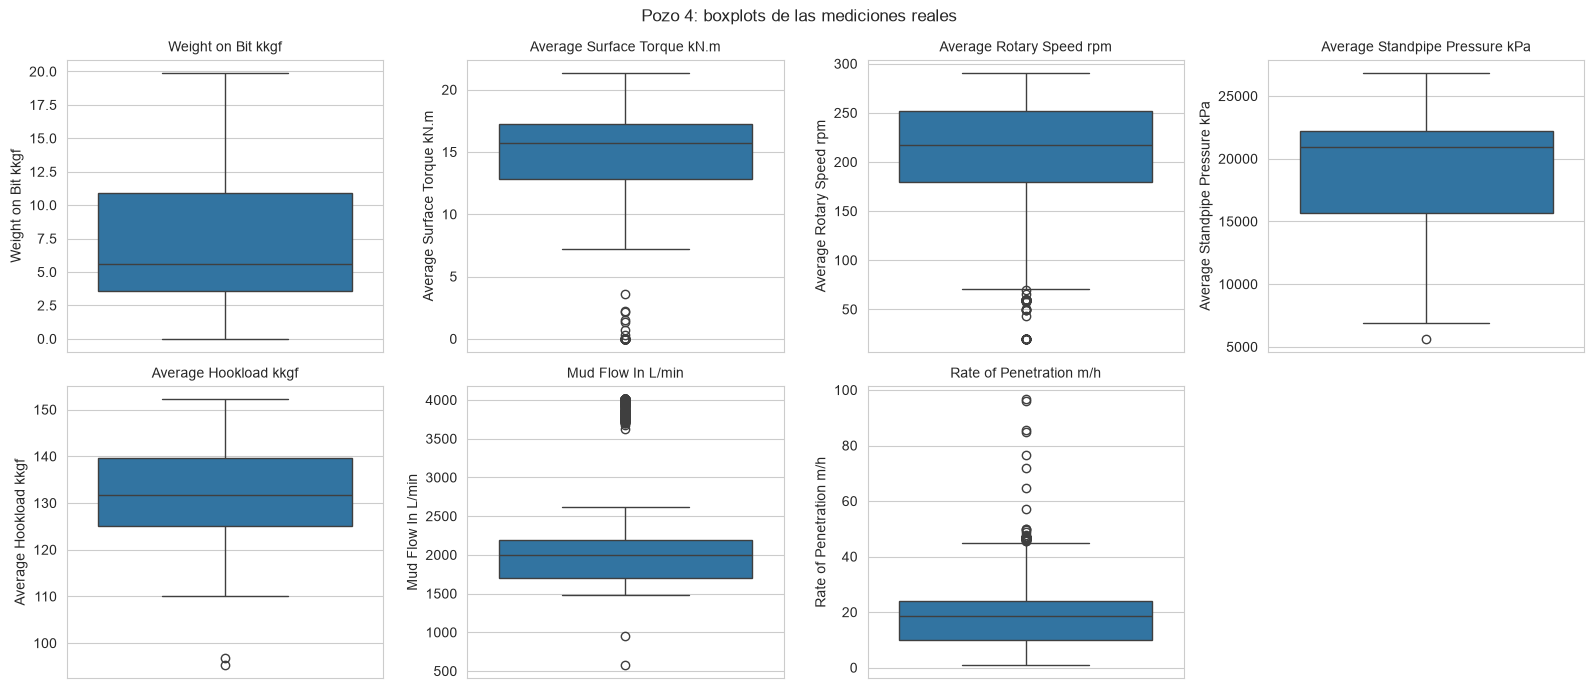

In [102]:
boxplots(final_4, variables_outliers, 'Pozo 4: boxplots de las mediciones reales')

### 7.7 Correlación con el ROP

La correlación **simple** mezcla el efecto de la profundidad; la **parcial** lo saca (ver sección 10.6.2 del Notebook 1). La tercera columna dice cuánto se pega cada variable a la profundidad.

In [103]:
corr_4 = corr_simple_parcial(final_4)
corr_4

,Simple,Parcial (sin profundidad),Simple con la profundidad
Average Standpipe Pressure kPa,0.73,0.57,-0.63
Average Surface Torque kN.m,-0.17,0.24,0.71
Weight on Bit kkgf,0.24,0.16,0.01
Average Rotary Speed rpm,0.22,0.09,0.02
Mud Flow In L/min,0.33,0.09,-0.82
Average Hookload kkgf,-0.63,-0.45,0.64


### 7.8 Guardar

Se guarda con un nombre propio, con las 10 columnas en el orden oficial. **No se sobrescribe ningún archivo original.**

In [104]:
final_4.to_csv('USROP_A 4 sin relleno.csv', index=False)
print('Guardado: USROP_A 4 sin relleno.csv', final_4.shape, '| nulos:', final_4.isna().sum().sum())

Guardado: USROP_A 4 sin relleno.csv (11175, 10) | nulos: 0


**Dos cosas a revisar en este pozo.** (1) Las filas del tramo de 8,5 pulgadas con profundidad de 0 a 146 m, que vimos en 2.2.1; y (2) las filas incompletas que tienen RPM, presión y caudal pero no WOB, hookload ni torque.

In [105]:
sospechosas = crudo_4[(crudo_4['pulgadas'] == 8.5) & (crudo_4['Measured Depth m'] < 1000)]
print('Filas del tramo de 8,5 pulgadas con MD < 1.000 m:', len(sospechosas), '| MD de', round(sospechosas['Measured Depth m'].min(), 1), 'a', round(sospechosas['Measured Depth m'].max(), 1), 'm')
print('   con algún dato del grupo de superficie:', int(sospechosas[grupo_superficie].notna().any(axis=1).sum()))

mecanicas = ['Weight on Bit kkgf', 'Average Hookload kkgf', 'Average Surface Torque kN.m']
sin_mecanicas = (inval_4[grupo_superficie].notna().any(axis=1) & inval_4[mecanicas].isna().all(axis=1)
                 & inval_4[['Average Rotary Speed rpm', 'Average Standpipe Pressure kPa', 'Mud Flow In L/min']].notna().all(axis=1))
print()
print('Filas con RPM, presión y caudal pero SIN WOB, hookload ni torque:', int(sin_mecanicas.sum()),
      '| MD de', round(inval_4.loc[sin_mecanicas, 'Measured Depth m'].min()), 'a', round(inval_4.loc[sin_mecanicas, 'Measured Depth m'].max()), 'm')

Filas del tramo de 8,5 pulgadas con MD < 1.000 m: 958 | MD de 0.0 a 145.8 m
   con algún dato del grupo de superficie: 0

Filas con RPM, presión y caudal pero SIN WOB, hookload ni torque: 4387 | MD de 1477 a 2432 m


<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Conclusión Parte 7 (pozo 4):** resumen del pozo 4, paso por paso:

- **7.1 Archivo:** 124.636 filas y dos tramos: 12,25 pulgadas (40.000 filas, de 1.339 a 2.432 m) y 8,5 (84.636). Estas últimas incluyen 958 filas a profundidades de 0 a 146 m, cuando ese tramo empieza recién a los ~2.390 m; ninguna tiene datos de superficie, así que no afectan las filas completas. No hay nada que sacar.
- **7.2 Qué hay medido:** 15 % de las filas con RPM, presión y caudal, pero solo 9,4 % con WOB y hookload y 11,5 % con torque. Por eso los sensores reportan juntos solo en el 61,4 % de los casos.
- **7.3 Limpieza:** se invalidaron **467 valores**: 135 WOB negativos, 9 WOB mayores a 35, 9 torques negativos, 95 ROP mayores a 100 y 219 ROP sin perforar.
- **7.4 Nulos que quedan:** 18.924 filas con datos de superficie, **11.175 completas** y 7.749 incompletas. La mayoría (4.387) tiene RPM, presión y caudal pero **no WOB, hookload ni torque**, todas entre 1.477 y 2.432 m, en el tramo de 12,25 pulgadas. En esa zona esos sensores no reportan, y ninguna otra columna del archivo los reemplaza. Se descartan.
- **7.5 Dataset final:** **11.175 filas × 10 columnas**, sin nulos ni duplicados. Cubre de 1.381 a 4.090 m, pero con **distinta densidad según el tramo**: 1 fila por metro en el tramo de 12,25 pulgadas contra 6,6 por metro en el de 8,5. Hay cuatro saltos: 112 m (de 2.431 a 2.543, el cambio de tramo), 16, 24,5 y 9,6 m. Hay 68 filas con torque exactamente 0. El ROP promedia 19,0 m/h (mediana 18,6; máximo 96,7). El diámetro toma dos valores.
- **7.6 Outliers:** el caudal da 9,2 % (1.026 altos), pero son exactamente las filas del tramo de 12,25 pulgadas, que se bombea a ~4.000 L/min contra ~2.000 en el de 8,5: es una diferencia entre tramos, no un error. La RPM da 1,1 %, el torque 0,7 % y el ROP 0,9 %.
- **7.7 Correlación con el ROP:** la parcial más alta es la **presión (0,57)**, luego el hookload, negativo (−0,45), el torque (0,24), el WOB (0,16), y la RPM y el caudal (0,09 las dos).
- **7.8 Guardado:** `USROP_A 4 sin relleno.csv`.

**En una frase:** el pozo 4 aporta **11.175 mediciones reales** (9,0 % de sus filas). Tiene dos regímenes de registro dentro del mismo pozo (1 y 6,6 filas por metro), que habrá que tener en cuenta al balancear por profundidad.

</div>

<div style="background-color:#1f5fa8; color:#ffffff; padding:26px 32px; border-radius:8px; margin:40px 0 10px 0;"><div style="font-size:42px; font-weight:bold; line-height:1.1; color:#ffffff;">POZO 5 · TEST</div><div style="font-size:17px; margin-top:6px; color:#dbe9f8;">Parte 8 · solo limpieza, sin exploración</div></div>

## Parte 8. Pozo 5 (test): limpieza sin exploración

El pozo 5 se limpia con **exactamente las mismas reglas** que los demás (las funciones de la Parte 2), para poder usarlo al final como prueba del modelo. **No se explora, no se grafica y no se toma ninguna decisión con él**: el código solo aplica las reglas y guarda el resultado.

In [106]:
crudo_5 = cargar_pozo(5)
inval_5, _ = invalidar_imposibles(preparar_pozo(crudo_5))
final_5 = armar_dataset(inval_5)

final_5.to_csv('USROP_A 5 sin relleno.csv', index=False)
print('Pozo 5 (test): dataset limpio guardado ->', final_5.shape, '| nulos:', final_5.isna().sum().sum())

Pozo 5 (test): dataset limpio guardado -> (908, 10) | nulos: 0


<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Conclusión Parte 8 (pozo 5, test):** el pozo 5 se limpió con las mismas reglas y quedó en **908 filas × 10 columnas**, sin nulos, guardado en `USROP_A 5 sin relleno.csv`. No se graficó ni se exploró, y no se usó para ninguna decisión: queda intacto para la evaluación final del modelo.

</div>

## Parte 9. Comparación entre pozos y dataset conjunto

Con los 6 pozos de entrenamiento limpios (el pozo 1 se rehace acá con las mismas funciones que los demás), comparamos los pozos entre sí y armamos el dataset conjunto para el modelado.

### 9.1 Los 6 pozos, lado a lado

In [107]:
datasets = {k: armar_dataset(invalidar_imposibles(d)[0]) for k, d in prep_todos.items()}

filas = []
for k, df in datasets.items():
    md_ = df['Measured Depth m']
    metros = md_.max() - md_.min()
    filas.append({'pozo': nombre_pozo[k], 'filas del pozo (sin tramos grandes)': len(prep_todos[k]), 'filas completas': len(df),
                  '% completas': round(100 * len(df) / len(prep_todos[k]), 1), 'MD mín (m)': round(md_.min()), 'MD máx (m)': round(md_.max()),
                  'filas por metro': round(len(df) / metros, 1), 'ROP mediana (m/h)': round(df[objetivo].median(), 1),
                  'ROP promedio (m/h)': round(df[objetivo].mean(), 1), 'valores de diámetro': df['Diameter mm'].nunique()})
tabla_final = pd.DataFrame(filas).set_index('pozo')
print('Total de filas completas de entrenamiento:', tabla_final['filas completas'].sum())
tabla_final

Total de filas completas de entrenamiento: 34456


,filas del pozo (sin tramos grandes),filas completas,% completas,MD mín (m),MD máx (m),filas por metro,ROP mediana (m/h),ROP promedio (m/h),valores de diámetro
pozo,,,,,,,,,
pozo 0,16670,3845,23.1,490,1206,5.4,44.0,41.5,2
pozo 1,19018,602,3.2,277,914,0.9,43.7,42.9,1
pozo 2,80301,2158,2.7,1050,3466,0.9,29.2,29.2,3
pozo 3,112714,16276,14.4,1297,4065,5.9,19.8,22.0,2
pozo 4,124636,11175,9.0,1381,4090,4.1,18.6,19.0,2
pozo 6,10000,400,4.0,219,633,1.0,55.2,52.1,1


**Sobre el pozo 1:** con las reglas de la Parte 2 da una fila menos que en el Notebook 1 (602 contra 603), porque la regla operativa descarta la fila de 209 m, con RPM = 15. Para el modelado se usa esta versión, así los 6 pozos tienen el mismo criterio.

### 9.2 ¿Se parecen los pozos en cómo se relacionan las variables con el ROP?

La **correlación parcial** con el ROP (sin el efecto de la profundidad, ver 2.5.2), pozo por pozo. La última columna cuenta en cuántos pozos tiene signo positivo.

In [108]:
parciales = pd.DataFrame({nombre_pozo[k]: corr_simple_parcial(df)['Parcial (sin profundidad)'] for k, df in datasets.items()})
parciales['pozos con signo positivo (de 6)'] = (parciales > 0).sum(axis=1)
parciales['promedio'] = parciales.iloc[:, :6].mean(axis=1).round(2)
parciales.sort_values('promedio', ascending=False).round(2)

,pozo 0,pozo 1,pozo 2,pozo 3,pozo 4,pozo 6,pozos con signo positivo (de 6),promedio
Average Standpipe Pressure kPa,0.37,0.18,0.51,-0.18,0.57,0.21,5,0.28
Average Rotary Speed rpm,0.53,0.20,0.27,0.08,0.09,0.22,6,0.23
Average Surface Torque kN.m,0.25,0.29,0.33,0.03,0.24,0.25,6,0.23
Mud Flow In L/min,0.18,0.19,0.44,-0.21,0.09,0.24,5,0.16
Weight on Bit kkgf,0.09,0.15,0.05,0.02,0.16,0.10,6,0.09
Average Hookload kkgf,-0.07,-0.03,0.14,-0.06,-0.45,-0.05,1,-0.09


<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Qué se ve en 9.2:** 

- **Torque, RPM y WOB tienen signo positivo en los 6 pozos.** El torque es el más parejo: de 0,24 a 0,33 en cinco pozos y 0,03 en el pozo 3. La RPM va de 0,08 a 0,53 y el WOB de 0,02 a 0,16.
- **El hookload es negativo en 5 de 6 pozos**, casi siempre cerca de cero (promedio −0,09): lo que parecía relación con el ROP era la profundidad.
- **La presión y el caudal cambian de signo en el pozo 3** (−0,18 y −0,21) y son positivas en los otros cinco. Es el pozo que más se aparta del resto.
- **Ninguna parcial promedio supera 0,28:** la señal propia de cada variable es débil, y varía de un pozo a otro (la presión va de −0,18 a 0,57).

</div>

### 9.3 El dataset conjunto, y el problema de la frecuencia de registro

Juntamos los 6 pozos en una sola tabla, con una columna `pozo`. Pero los pozos no registran con la misma frecuencia: algunos guardan una fila cada 0,15 m y otros una cada metro. Si se juntan tal cual, **los pozos que registran más seguido pesan más** en el modelo, aunque no tengan más información. Para evitarlo se igualan las muestras por metro: nos quedamos con **una fila por metro de profundidad** en cada pozo (la primera de cada metro).

In [109]:
conjunto = pd.concat([df.assign(pozo=k) for k, df in datasets.items()], ignore_index=True)
conjunto['metro'] = np.floor(conjunto['Measured Depth m']).astype(int)
balanceado = (conjunto.sort_values(['pozo', 'Measured Depth m']).groupby(['pozo', 'metro']).head(1).reset_index(drop=True))

resumen_balance = pd.DataFrame({
    'filas completas': conjunto.groupby('pozo').size(),
    '% del total': (100 * conjunto.groupby('pozo').size() / len(conjunto)).round(1),
    'filas balanceadas (1 por metro)': balanceado.groupby('pozo').size(),
    '% del total (balanceado)': (100 * balanceado.groupby('pozo').size() / len(balanceado)).round(1),
})
resumen_balance.index = [nombre_pozo[k] for k in resumen_balance.index]
resumen_balance.loc['TOTAL'] = [len(conjunto), 100.0, len(balanceado), 100.0]
resumen_balance

,filas completas,% del total,filas balanceadas (1 por metro),% del total (balanceado)
pozo 0,3845.0,11.2,603.0,7.1
pozo 1,602.0,1.7,554.0,6.5
pozo 2,2158.0,6.3,1979.0,23.4
pozo 3,16276.0,47.2,2518.0,29.7
pozo 4,11175.0,32.4,2451.0,28.9
pozo 6,400.0,1.2,368.0,4.3
TOTAL,34456.0,100.0,8473.0,100.0


<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Qué se ve en 9.3:** 

- **Sin balancear, los pozos 3 y 4 pesan el 79,6 % de las filas** (47,2 % y 32,4 %), y los pozos 1 y 6 solo el 1,7 % y el 1,2 %. Es un efecto de la frecuencia de registro (5,9 y 4,1 filas por metro contra 0,9 a 1,0), no de que tengan más información.
- **Balanceado a una fila por metro**, el conjunto queda en **8.473 filas** y cada pozo pesa según los metros que cubre con datos: pozo 3 (29,7 %), pozo 4 (28,9 %), pozo 2 (23,4 %), pozo 0 (7,1 %), pozo 1 (6,5 %) y pozo 6 (4,3 %).
- Se guardan las dos versiones; en el modelado conviene probar con las dos.

</div>

### 9.4 Multicolinealidad (VIF)

El **VIF** mide cuánto de una variable ya está explicado por las demás (más de 5 preocupa; más de 10 es casi redundante). Lo calculamos sobre el dataset balanceado, con las variables que usaría el modelo.

In [110]:
def vif(tabla):
    resultado = {}
    for col in tabla.columns:
        y = tabla[col].values
        A = np.column_stack([np.ones(len(tabla)), tabla.drop(columns=[col]).values])
        resto = y - A @ np.linalg.lstsq(A, y, rcond=None)[0]
        r2 = 1 - (resto ** 2).sum() / ((y - y.mean()) ** 2).sum()
        resultado[col] = round(1 / (1 - r2), 1)
    return pd.Series(resultado)

X = balanceado.drop(columns=['pozo', 'metro', objetivo])
pd.DataFrame({'con las dos profundidades': vif(X),
              'sin Hole Depth (TVD)': vif(X.drop(columns=['Hole Depth (TVD) m'])),
              'sin Measured Depth': vif(X.drop(columns=['Measured Depth m']))}).fillna('')

,con las dos profundidades,sin Hole Depth (TVD),sin Measured Depth
Average Hookload kkgf,15.4,10.4,15.2
Average Rotary Speed rpm,1.7,1.7,1.6
Average Standpipe Pressure kPa,3.7,3.4,3.7
Average Surface Torque kN.m,5.3,5.2,4.5
Diameter mm,8.4,8.4,8.4
Hole Depth (TVD) m,67.7,,37.6
Measured Depth m,54.6,30.4,
Mud Flow In L/min,21.0,19.0,19.8
Weight on Bit kkgf,2.0,1.9,2.0


<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Qué se ve en 9.4:** 

- **Las dos profundidades son casi lo mismo:** con las dos juntas, el VIF del TVD es 67,7 y el del MD 54,6. Sacando una, el VIF de la otra baja pero sigue alto (MD: 30,4 sin el TVD; TVD: 37,6 sin el MD). Para un modelo lineal conviene dejar **una sola**; los árboles lo toleran.
- **El caudal (21,0) y el hookload (15,4) también tienen VIF alto:** cambian con la profundidad y con el tramo (el caudal es distinto en cada diámetro).
- Las demás variables están por debajo de 9 (diámetro 8,4; torque 5,3; presión 3,7; WOB 2,0; RPM 1,7).

</div>

<div style="background-color:#fdecea; border-left:8px solid #e74c3c; padding:22px 28px; border-radius:6px; font-size:19px; line-height:1.55;">

<div style="font-size:26px; font-weight:bold; color:#b71c1c; margin-bottom:8px;">⚠ Precaución: la profundidad no significa lo mismo en todos los pozos</div>

- Los pozos 1 y 6 son **verticales**; los pozos 3 y 4 **se inclinan**.
- En un pozo vertical, la profundidad medida (`Measured Depth`, MD) y la profundidad vertical (`Hole Depth (TVD)`) son casi iguales. En el pozo 3 se separan: entre los 3.200 y 3.600 m de MD el pozo avanza casi horizontal y la TVD casi no cambia (de 2.825 a 2.905 m).
- Por eso, un mismo valor de MD **no es la misma roca** en un pozo vertical que en el pozo 3.
- **Qué hacer al modelar:** usar la TVD (o las dos con cuidado). Y si el modelo falla en ese tramo del pozo 3, no asumir que los datos están mal.

</div>

### 9.5 Guardar los datasets

Se guardan **dos conjuntos de entrenamiento** (los mismos 6 pozos, con la columna `pozo`). El pozo 5 (test) queda aparte, en su propio archivo (Parte 8). No se sobrescribe ningún csv original.

<div style="background-color:#e8f1fb; border-left:6px solid #1f5fa8; padding:14px 20px; border-radius:6px; margin:10px 0; font-size:16px;">
<b style="font-size:19px; color:#1f5fa8;">conjunto_limpio.csv</b><br>
Los <b>6 pozos de entrenamiento juntos</b>, con todas sus mediciones reales: <b>34.456 filas</b>. La columna <code>pozo</code> dice de cuál es cada fila.
</div>

<div style="background-color:#e8f1fb; border-left:6px solid #1f5fa8; padding:14px 20px; border-radius:6px; margin:10px 0; font-size:16px;">
<b style="font-size:19px; color:#1f5fa8;">conjunto_limpio_balanceado.csv</b><br>
Los mismos 6 pozos, pero con <b>una sola fila por metro de profundidad</b>: <b>8.473 filas</b>. Sirve para que los pozos que registran más seguido (el 3 y el 4) no pesen más que los demás.
</div>

In [111]:
columnas_guardar = orden_columnas + ['pozo']
conjunto[columnas_guardar].to_csv('conjunto_limpio.csv', index=False)
balanceado[columnas_guardar].to_csv('conjunto_limpio_balanceado.csv', index=False)
print('Conjunto completo:', conjunto[columnas_guardar].shape, '| balanceado:', balanceado[columnas_guardar].shape)

Conjunto completo: (34456, 11) | balanceado: (8473, 11)


### 9.6 Resumen de los archivos que quedan

| Archivo | Contenido | Para qué |
|---|---|---|
| `USROP_A N sin relleno.csv` (N = 0, 2, 3, 4, 6) | Un pozo de entrenamiento, 10 columnas. El del pozo 1 es el del Notebook 1 (603 filas); en el conjunto entra con 602 | Ver o usar cada pozo por separado |
| `conjunto_limpio.csv` | Los 6 pozos juntos, con columna `pozo` | Entrenar usando todas las mediciones reales |
| `conjunto_limpio_balanceado.csv` | Los 6 pozos juntos, una fila por metro | Entrenar sin que pesen más los pozos que registran más seguido |
| `USROP_A 5 sin relleno.csv` | El pozo 5 (test), sin explorar | Solo para la evaluación final |


<div style="background-color:#fff9db; border-left:6px solid #f1c40f; padding:14px 18px; border-radius:4px;">

**Conclusión Parte 9:** 

- **Los 6 pozos son comparables** una vez limpios: mismos rangos de WOB, ROP y presión según la profundidad. Aportan **34.456 filas completas**, de 400 (pozo 6) a 16.276 (pozo 3).
- **Hay tres variables con efecto positivo en los 6 pozos:** torque, RPM y WOB, aunque débil (la correlación parcial promedio más alta es 0,23). El hookload no aporta, y la presión y el caudal cambian de signo en el pozo 3.
- **Los pozos no pesan igual por la frecuencia de registro:** los pozos 3 y 4 son el 80 % de las filas. Al balancear por profundidad (una fila por metro), el conjunto queda en **8.473 filas** y los pesos se reparten según los metros cubiertos.
- **Las dos profundidades son redundantes** (VIF de 55 y 68): para modelos lineales hay que dejar una.
- **Para el modelado:** validar dejando un pozo afuera (no filas sueltas al azar), probar con el dataset completo y con el balanceado, y evaluar al final con el pozo 5, que no se tocó. Es esperable una capacidad de predicción modesta: la señal propia de cada variable es débil y cambia de pozo a pozo.

</div>